# 02 — Market Distributions

**Purpose:** characterize the empirical distributions, tails, cross-asset heterogeneity, and temporal persistence of the **futures / market-state feature block** before any regime model is fitted.

This notebook is deliberately diagnostic. It:

- opens `research.duckdb` in **read-only** mode;
- uses `time_series_feature_state` as the primary research table;
- analyzes returns, realized volatility, activity/flow, price-bar structure, open interest, basis/spreads, and the standard L2 state;
- compares pooled distributions with **per-underlying** distributions;
- separates **full-range** views from **central-range** views instead of clipping or winsorizing observations;
- inspects extreme observations in their original timestamp / asset context;
- studies autocorrelation and session-to-session variation;
- evaluates candidate transforms only as **research hypotheses**;
- audits futures quote integrity and open-interest jumps on raw collector fields (Part I).

It does **not**:

- impute missing values;
- winsorize or delete tail events (integrity flags describe suspect states; they do not remove them);
- globally standardize across assets;
- fit HMMs / HSMMs;
- fit the Clean/Noisy latent chain;
- analyze the newly collected L2-instability block in depth (reserved for Notebook 04);
- analyze option-surface distributions (reserved for Notebook 03).

> Research rule: distribution diagnostics should reveal the data-generating structure, not force every feature to look Gaussian.

## 1. Environment and read-only database connection

The notebook follows the same database discipline as `01_feature_inventory.ipynb`: the research database is opened read-only and no production relation is modified.

The DuckDB session time zone is set to **UTC**. Without it, `TIMESTAMPTZ` values come back in the PC's local zone (Europe/Madrid, which also changes at DST), and every hour-of-day result would be shifted.


In [1]:
from pathlib import Path
import os
import math
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 220)
pd.set_option("display.max_rows", 220)
pd.set_option("display.width", 200)

load_dotenv()

data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError(
        "DERIBIT_DATA_ROOT is not defined in the environment/.env file."
    )

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"

if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")

print(f"Research DB: {DB_PATH}")
print("Connection mode: read-only")
print("Session time zone:", con.execute("SELECT current_setting('TimeZone')").fetchone()[0])

Research DB: D:\MarketData\Deribit\database\research.duckdb
Connection mode: read-only
Session time zone: UTC


## 2. Load the market-facing state table

The table grain is expected to remain:

**one row = one underlying × one five-minute state**

Unlike Notebook 01, this notebook does **not** apply one global readiness filter. Each feature family is analyzed using its own valid observations and, where appropriate, its component-specific readiness flag. This avoids discarding valid futures observations merely because an unrelated options component was unavailable.

In [2]:
features = con.execute(
    """
    SELECT *
    FROM time_series_feature_state
    ORDER BY state_time, underlying
    """
).df()

features["state_time"] = pd.to_datetime(features["state_time"], utc=True)

print(f"Rows:        {len(features):,}")
print(f"Columns:     {features.shape[1]:,}")
print(f"Underlyings: {features['underlying'].nunique(dropna=True):,}")
print(f"First state: {features['state_time'].min()}")
print(f"Last state:  {features['state_time'].max()}")

assert features["state_id"].duplicated().sum() == 0
assert features.duplicated(subset=["underlying", "state_time"]).sum() == 0

Rows:        28,224
Columns:     148
Underlyings: 7
First state: 2026-09-19 08:00:00+00:00
Last state:  2026-10-03 07:55:00+00:00


## 3. Analysis feature families

The groups below are intentionally narrower than the full feature inventory.

The aim is to understand the **market-state block** that may later contribute to:

- structural HSMM emissions;
- persistence / transition predictors;
- model-time normalization decisions.

Option-surface features are deferred to Notebook 03. The new L2-instability scalars are intentionally not a main subject here because their history is still short.

In [3]:
FEATURE_GROUPS = {
    "returns": [
        "return_5m",
        "return_15m",
        "return_30m",
        "return_1h",
    ],
    "realized_volatility": [
        "realized_vol_30m",
        "realized_vol_1h",
        "realized_vol_4h",
        "realized_vol_30m_annualized",
        "realized_vol_1h_annualized",
        "realized_vol_4h_annualized",
    ],
    "activity_flow": [
        "volume_usd",
        "log1p_volume_usd",
        "signed_volume_usd",
        "trade_flow_imbalance",
        "buy_volume_share",
        "average_trade_size_usd",
        "trade_count",
    ],
    "bar_structure_open_interest": [
        "intrabar_range_bps",
        "close_vs_vwap_bps",
        "open_interest",
        "open_interest_change_5m",
        "open_interest_return_5m",
    ],
    "basis_spread_microprice": [
        "futures_spread_bps",
        "perpetual_mid_vs_index_bps",
        "perpetual_mark_vs_index_bps",
        "microprice_vs_mid_bps",
        "book_twa_spread_bps",
        "book_twa_microprice_vs_reference_bps",
    ],
    "standard_l2": [
        "book_twa_obi_5",
        "book_twa_obi_10",
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
        "book_twa_bid_depth_20",
        "book_twa_ask_depth_20",
        "book_twa_spread",
        "book_twa_microprice",
    ],
}

available_groups = {
    group: [c for c in cols if c in features.columns]
    for group, cols in FEATURE_GROUPS.items()
}

for group, cols in available_groups.items():
    print(f"{group:<30} {len(cols):>2} / {len(FEATURE_GROUPS[group]):>2} available")
    missing = [c for c in FEATURE_GROUPS[group] if c not in features.columns]
    if missing:
        print("  missing:", missing)

returns                         4 /  4 available
realized_volatility             6 /  6 available
activity_flow                   7 /  7 available
bar_structure_open_interest     5 /  5 available
basis_spread_microprice         6 /  6 available
standard_l2                     8 /  8 available


## 4. Generic diagnostic helpers

Two principles are built into these helpers:

1. **Full range and central range are different questions.** Full-range plots show the existence of tail events; central-range plots show ordinary-state structure.
2. **Pooled crypto data can be misleading.** Per-underlying summaries remain first-class outputs throughout this notebook.

In [4]:
CENTRAL_LOWER_Q = 0.005
CENTRAL_UPPER_Q = 0.995
TAIL_QS = [0.001, 0.01, 0.05, 0.50, 0.95, 0.99, 0.999]

def clean_numeric(df, column):
    return (
        pd.to_numeric(df[column], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

def feature_summary(df, columns, group_col=None):
    rows = []
    iterator = [("ALL", df)] if group_col is None else df.groupby(group_col, dropna=False)

    for group_name, group in iterator:
        for col in columns:
            if col not in group.columns:
                continue

            s = clean_numeric(group, col)
            if s.empty:
                continue

            q = s.quantile(TAIL_QS)
            rows.append({
                "group": group_name,
                "feature": col,
                "n": len(s),
                "missing_pct": 100.0 * (len(group) - len(s)) / len(group),
                "mean": s.mean(),
                "std": s.std(),
                "skew": s.skew(),
                "excess_kurtosis": s.kurt(),
                "min": s.min(),
                "q001": q.loc[0.001],
                "q01": q.loc[0.01],
                "q05": q.loc[0.05],
                "median": q.loc[0.50],
                "q95": q.loc[0.95],
                "q99": q.loc[0.99],
                "q999": q.loc[0.999],
                "max": s.max(),
            })

    return pd.DataFrame(rows)

def plot_full_and_central(df, column, bins=100):
    s = clean_numeric(df, column)
    if s.empty:
        print(f"{column}: no observations")
        return

    lo = s.quantile(CENTRAL_LOWER_Q)
    hi = s.quantile(CENTRAL_UPPER_Q)
    central = s[(s >= lo) & (s <= hi)]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    axes[0].hist(s, bins=bins)
    axes[0].set_title(f"{column} — full range")
    axes[0].set_ylabel("Count")

    axes[1].hist(central, bins=bins)
    axes[1].set_title(
        f"{column} — central {100*(CENTRAL_UPPER_Q-CENTRAL_LOWER_Q):.1f}%"
    )
    axes[1].set_ylabel("Count")

    plt.tight_layout()
    plt.show()

    print(
        f"n={len(s):,} | "
        f"central bounds [{lo:.6g}, {hi:.6g}] | "
        f"min={s.min():.6g} | max={s.max():.6g}"
    )

def plot_asset_histograms(df, column, bins=70):
    assets = sorted(df["underlying"].dropna().unique().tolist())
    if not assets:
        return

    ncols = 2
    nrows = math.ceil(len(assets) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.7 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, asset in zip(axes, assets):
        s = clean_numeric(df[df["underlying"] == asset], column)
        if s.empty:
            ax.text(0.5, 0.5, "No observations", ha="center", va="center")
        else:
            lo = s.quantile(CENTRAL_LOWER_Q)
            hi = s.quantile(CENTRAL_UPPER_Q)
            central = s[(s >= lo) & (s <= hi)]
            ax.hist(central, bins=bins)
        ax.set_title(str(asset))

    for ax in axes[len(assets):]:
        ax.axis("off")

    fig.suptitle(f"{column} — per-asset central distributions", y=1.01)
    plt.tight_layout()
    plt.show()

def plot_ecdf_by_asset(df, column):
    fig, ax = plt.subplots(figsize=(10, 6))

    plotted = 0
    for asset, group in df.groupby("underlying"):
        s = clean_numeric(group, column).sort_values()
        if s.empty:
            continue

        y = np.arange(1, len(s) + 1) / len(s)
        ax.plot(s.to_numpy(), y, label=str(asset), linewidth=1.3)
        plotted += 1

    if plotted:
        ax.set_title(f"ECDF by underlying — {column}")
        ax.set_xlabel(column)
        ax.set_ylabel("Empirical CDF")
        ax.legend()
        plt.tight_layout()
        plt.show()

def contiguous_acf(df, column, max_lag=24):
    rows = []

    for asset, group in df.groupby("underlying"):
        g = group.sort_values("state_time").copy()
        x = pd.to_numeric(g[column], errors="coerce")

        for lag in range(1, max_lag + 1):
            lagged_x = x.shift(lag)
            lagged_time = g["state_time"].shift(lag)

            expected_minutes = 5 * lag
            valid = (
                x.notna()
                & lagged_x.notna()
                & (
                    (g["state_time"] - lagged_time)
                    .dt.total_seconds()
                    .div(60.0)
                    == expected_minutes
                )
            )

            n_pairs = int(valid.sum())
            corr = np.nan

            if n_pairs >= 20:
                corr = x[valid].corr(lagged_x[valid])

            rows.append({
                "underlying": asset,
                "feature": column,
                "lag": lag,
                "lag_minutes": expected_minutes,
                "n_pairs": n_pairs,
                "acf": corr,
            })

    return pd.DataFrame(rows)

def plot_acf_by_asset(df, column, max_lag=24):
    acf = contiguous_acf(df, column, max_lag=max_lag)

    fig, ax = plt.subplots(figsize=(11, 6))
    for asset, group in acf.groupby("underlying"):
        ax.plot(group["lag_minutes"], group["acf"], marker="o", ms=3, label=str(asset))

    ax.axhline(0.0, linewidth=1)
    ax.set_title(f"Autocorrelation by underlying — {column}")
    ax.set_xlabel("Lag (minutes)")
    ax.set_ylabel("Autocorrelation")
    ax.legend()
    plt.tight_layout()
    plt.show()

    return acf

def contextual_extremes(df, column, n=12, absolute=False):
    context = [
        "state_id",
        "state_time",
        "underlying",
        "expiry_date",
        "minutes_to_expiry",
        column,
        "return_5m",
        "realized_vol_1h_annualized",
        "volume_usd",
        "trade_flow_imbalance",
        "futures_spread_bps",
        "perpetual_mid_vs_index_bps",
        "book_twa_obi_20",
        "book_twa_spread_bps",
    ]
    context = list(dict.fromkeys(c for c in context if c in df.columns))

    work = df[context].copy()
    work[column] = pd.to_numeric(work[column], errors="coerce")
    work = work.dropna(subset=[column])

    if absolute:
        work["_rank_value"] = work[column].abs()
        result = work.nlargest(n, "_rank_value").drop(columns="_rank_value")
    else:
        high = work.nlargest(n, column).assign(tail="high")
        low = work.nsmallest(n, column).assign(tail="low")
        result = pd.concat([low, high], ignore_index=True)

    return result.sort_values(
        ["state_time", "underlying"],
        kind="stable"
    ).reset_index(drop=True)

def signed_log1p(s):
    s = pd.to_numeric(s, errors="coerce")
    return np.sign(s) * np.log1p(np.abs(s))

## 5. Feature availability by asset

Notebook 01 established overall integrity. Here we verify that the effective sample size of each **market** feature is understood before comparing distribution shape.

A feature with a smaller sample is not automatically defective; rolling windows and component readiness naturally reduce coverage.

In [5]:
market_feature_columns = sorted({
    c
    for cols in available_groups.values()
    for c in cols
})

availability_rows = []

for asset, group in features.groupby("underlying"):
    row = {
        "underlying": asset,
        "states": len(group),
    }

    for col in market_feature_columns:
        row[f"{col}_n"] = int(group[col].notna().sum())
        row[f"{col}_pct"] = 100.0 * group[col].notna().mean()

    availability_rows.append(row)

availability_by_asset = pd.DataFrame(availability_rows).sort_values("underlying")
display(availability_by_asset)

overall_availability = pd.DataFrame({
    "feature": market_feature_columns,
    "n": [int(features[c].notna().sum()) for c in market_feature_columns],
    "coverage_pct": [100.0 * features[c].notna().mean() for c in market_feature_columns],
}).sort_values("coverage_pct")

display(overall_availability.reset_index(drop=True))

,underlying,states,average_trade_size_usd_n,average_trade_size_usd_pct,book_twa_ask_depth_20_n,book_twa_ask_depth_20_pct,book_twa_bid_depth_20_n,book_twa_bid_depth_20_pct,book_twa_microprice_n,book_twa_microprice_pct,book_twa_microprice_vs_reference_bps_n,book_twa_microprice_vs_reference_bps_pct,book_twa_obi_10_n,book_twa_obi_10_pct,book_twa_obi_20_n,book_twa_obi_20_pct,book_twa_obi_20_change_5m_n,book_twa_obi_20_change_5m_pct,book_twa_obi_5_n,book_twa_obi_5_pct,book_twa_spread_n,book_twa_spread_pct,book_twa_spread_bps_n,book_twa_spread_bps_pct,buy_volume_share_n,buy_volume_share_pct,close_vs_vwap_bps_n,close_vs_vwap_bps_pct,futures_spread_bps_n,futures_spread_bps_pct,intrabar_range_bps_n,intrabar_range_bps_pct,log1p_volume_usd_n,log1p_volume_usd_pct,microprice_vs_mid_bps_n,microprice_vs_mid_bps_pct,open_interest_n,open_interest_pct,open_interest_change_5m_n,open_interest_change_5m_pct,open_interest_return_5m_n,open_interest_return_5m_pct,perpetual_mark_vs_index_bps_n,perpetual_mark_vs_index_bps_pct,perpetual_mid_vs_index_bps_n,perpetual_mid_vs_index_bps_pct,realized_vol_1h_n,realized_vol_1h_pct,realized_vol_1h_annualized_n,realized_vol_1h_annualized_pct,realized_vol_30m_n,realized_vol_30m_pct,realized_vol_30m_annualized_n,realized_vol_30m_annualized_pct,realized_vol_4h_n,realized_vol_4h_pct,realized_vol_4h_annualized_n,realized_vol_4h_annualized_pct,return_15m_n,return_15m_pct,return_1h_n,return_1h_pct,return_30m_n,return_30m_pct,return_5m_n,return_5m_pct,signed_volume_usd_n,signed_volume_usd_pct,trade_count_n,trade_count_pct,trade_flow_imbalance_n,trade_flow_imbalance_pct,volume_usd_n,volume_usd_pct
0,AVAX,4032,3234,80.208333,3153,78.199405,3153,78.199405,3153,78.199405,3152,78.174603,3153,78.199405,3153,78.199405,3151,78.149802,3153,78.199405,3153,78.199405,3152,78.174603,3234,80.208333,3234,80.208333,3420,84.821429,3234,80.208333,3423,84.895833,3152,78.174603,3420,84.821429,3416,84.722222,3416,84.722222,3420,84.821429,3420,84.821429,2922,72.470238,2922,72.470238,3130,77.628968,3130,77.628968,2008,49.801587,2008,49.801587,3328,82.539683,3315,82.217262,3321,82.366071,3331,82.614087,3423,84.895833,3423,84.895833,3234,80.208333,3423,84.895833
1,BTC,4032,3417,84.747024,3153,78.199405,3153,78.199405,3153,78.199405,3152,78.174603,3153,78.199405,3153,78.199405,3151,78.149802,3153,78.199405,3153,78.199405,3152,78.174603,3417,84.747024,3417,84.747024,3420,84.821429,3416,84.722222,3423,84.895833,3152,78.174603,3420,84.821429,3416,84.722222,3416,84.722222,3420,84.821429,3420,84.821429,2922,72.470238,2922,72.470238,3130,77.628968,3130,77.628968,2008,49.801587,2008,49.801587,3328,82.539683,3315,82.217262,3321,82.366071,3331,82.614087,3423,84.895833,3423,84.895833,3417,84.747024,3423,84.895833
2,ETH,4032,3416,84.722222,3153,78.199405,3153,78.199405,3153,78.199405,3152,78.174603,3153,78.199405,3153,78.199405,3151,78.149802,3153,78.199405,3153,78.199405,3152,78.174603,3416,84.722222,3416,84.722222,3420,84.821429,3415,84.697421,3423,84.895833,3152,78.174603,3420,84.821429,3416,84.722222,3416,84.722222,3420,84.821429,3420,84.821429,2922,72.470238,2922,72.470238,3130,77.628968,3130,77.628968,2008,49.801587,2008,49.801587,3328,82.539683,3315,82.217262,3321,82.366071,3331,82.614087,3423,84.895833,3423,84.895833,3416,84.722222,3423,84.895833
3,HYPE,4032,2740,67.956349,3153,78.199405,3153,78.199405,3153,78.199405,3152,78.174603,3153,78.199405,3153,78.199405,3151,78.149802,3153,78.199405,3153,78.199405,3152,78.174603,2740,67.956349,2740,67.956349,3420,84.821429,2739,67.931548,3423,84.895833,3152,78.174603,3420,84.821429,3416,84.722222,3416,84.722222,3420,84.821429,3420,84.821429,2922,72.470238,2922,72.470238,3130,77.628968,3130,77.628968,2008,49.801587,2008,49.801587,3328,82.539683,3315,82.217262,3321,82.366071,3331,82.614087,3423,84.895833,3423,84.895833,2740,67.956349,3423,84.895833
4,SOL,4032,3416,84.722222,3153,78.199405,3153,78.199405,3153,78.199405,3152,78.174603,3153,78.199405,3153,78.199405,3151,78.149802,3153,78.199405,3153,78.199405,3152

,feature,n,coverage_pct
0,realized_vol_4h_annualized,14056,49.801587
1,realized_vol_4h,14056,49.801587
2,realized_vol_1h_annualized,20454,72.470238
3,realized_vol_1h,20454,72.470238
4,intrabar_range_bps,20689,73.302863
5,average_trade_size_usd,20694,73.320578
6,buy_volume_share,20694,73.320578
7,close_vs_vwap_bps,20694,73.320578
8,trade_flow_imbalance,20694,73.320578
9,realized_vol_30m_annualized,21910,77.628968


# Part A — Returns

## 6. Return distributions

The return block is examined without forcing normality. Heavy tails, asymmetry, and asset-specific scale are economically meaningful diagnostics for later emission-family choices.

The four return horizons overlap heavily, so they should not be interpreted as independent observations.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,return_5m,23317,17.385913,-0.000006,0.002233,-0.208627,306.874587,-0.096015,-0.012791,-0.005798,-0.002977,0.000000,0.003063,0.005687,0.012219,0.096277
1,ALL,return_15m,23296,17.460317,-0.000024,0.003535,-0.464800,54.791981,-0.097046,-0.022136,-0.010312,-0.005286,0.000000,0.005188,0.009904,0.017211,0.095218
2,ALL,return_30m,23247,17.633929,-0.000046,0.004775,-0.404792,20.281032,-0.096828,-0.027663,-0.014083,-0.007544,0.000000,0.007113,0.013206,0.022076,0.095638
3,ALL,return_1h,23205,17.782738,-0.000087,0.006543,-0.136310,8.709333,-0.096610,-0.035114,-0.019086,-0.010591,-0.000041,0.010047,0.018819,0.033000,0.093610


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,return_5m,3331,17.385913,-1.320368e-05,0.003247,-0.362021,8.579298,-0.029578,-0.021391,-0.008464,-0.004830,-0.000044,0.004853,0.008046,0.014405,0.026031
1,AVAX,return_15m,3328,17.460317,-4.947891e-05,0.005362,-0.423069,3.724997,-0.038868,-0.029375,-0.014720,-0.008709,0.000000,0.008169,0.014083,0.019614,0.025022
2,AVAX,return_30m,3321,17.633929,-1.073574e-04,0.007345,-0.445312,2.697517,-0.044133,-0.037861,-0.021070,-0.011689,-0.000048,0.011549,0.017612,0.025862,0.030756
3,AVAX,return_1h,3315,17.782738,-2.144970e-04,0.010407,-0.155018,1.887847,-0.049665,-0.042256,-0.031448,-0.016411,-0.000591,0.016989,0.024616,0.041314,0.049225
4,BTC,return_5m,3331,17.385913,1.936452e-06,0.001138,-0.314000,8.478063,-0.011679,-0.005896,-0.003192,-0.001755,0.000000,0.001718,0.003210,0.005622,0.008250
5,BTC,return_15m,3328,17.460317,1.618079e-06,0.001907,-0.351166,7.846751,-0.016585,-0.011267,-0.005408,-0.002838,0.000016,0.002867,0.005104,0.009712,0.015458
6,BTC,return_30m,3321,17.633929,-1.701526e-07,0.002635,-0.286593,6.798301,-0.020807,-0.015726,-0.007888,-0.004062,0.000047,0.003965,0.006746,0.014127,0.019062
7,BTC,return_1h,3315,17.782738,-9.047558e-07,0.003622,-0.084773,3.928031,-0.021270,-0.016589,-0.010514,-0.005967,0.000051,0.005374,0.009823,0.017874,0.021389
8,ETH,return_5m,3331,17.385913,-1.465354e-06,0.001402,0.037529,8.090953,-0.009431,-0.008177,-0.003974,-0.002161,0.000004,0.002040,0.003834,0.007224,0.014017
9,ETH,return_15m,3328,17.460317,-1.276901e-05,0.002346,-0.434583,6.722804,-0.022593,-0.012209,-0.006488,-0.003622,0.000019,0.003540,0.006127,0.011041,0.012076


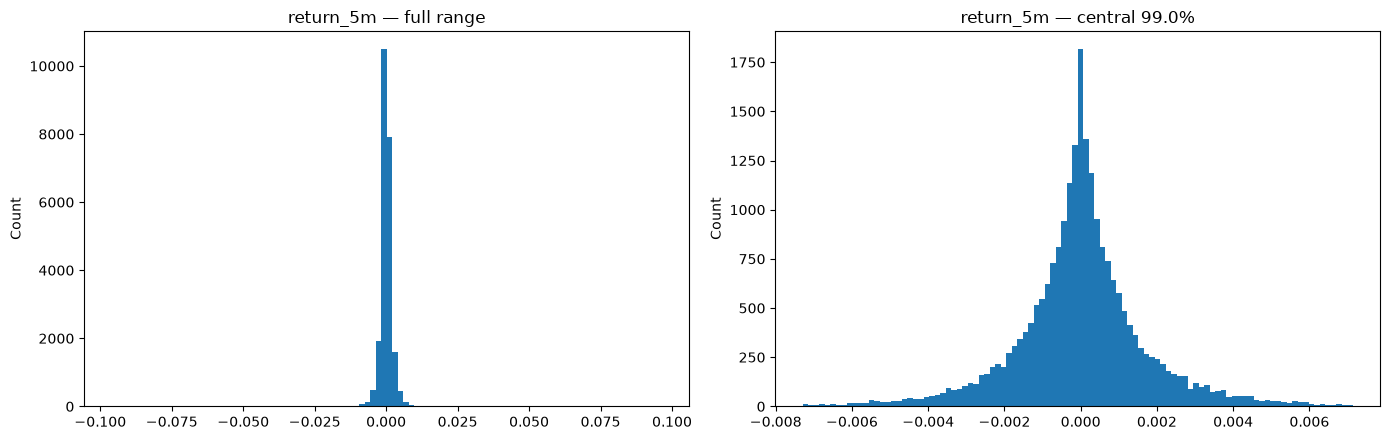

n=23,317 | central bounds [-0.00729229, 0.00713076] | min=-0.0960155 | max=0.0962766


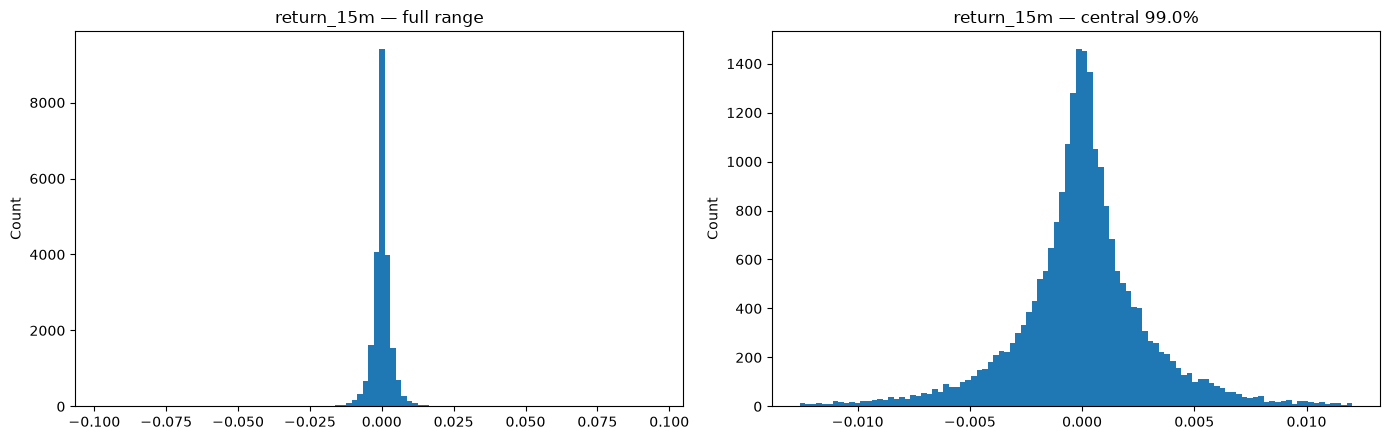

n=23,296 | central bounds [-0.012597, 0.0120455] | min=-0.097046 | max=0.0952179


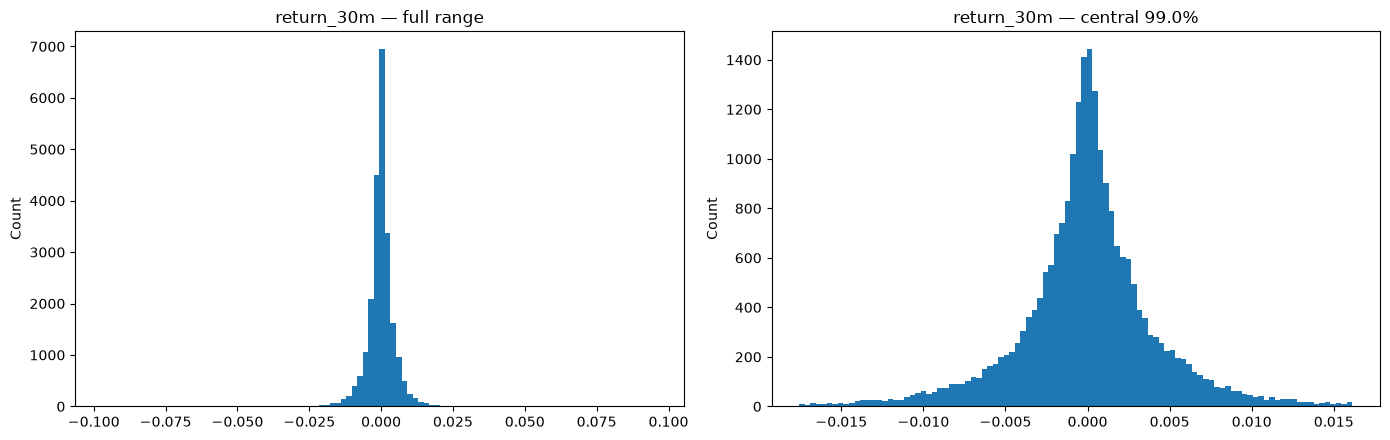

n=23,247 | central bounds [-0.0175774, 0.0161332] | min=-0.0968282 | max=0.0956384


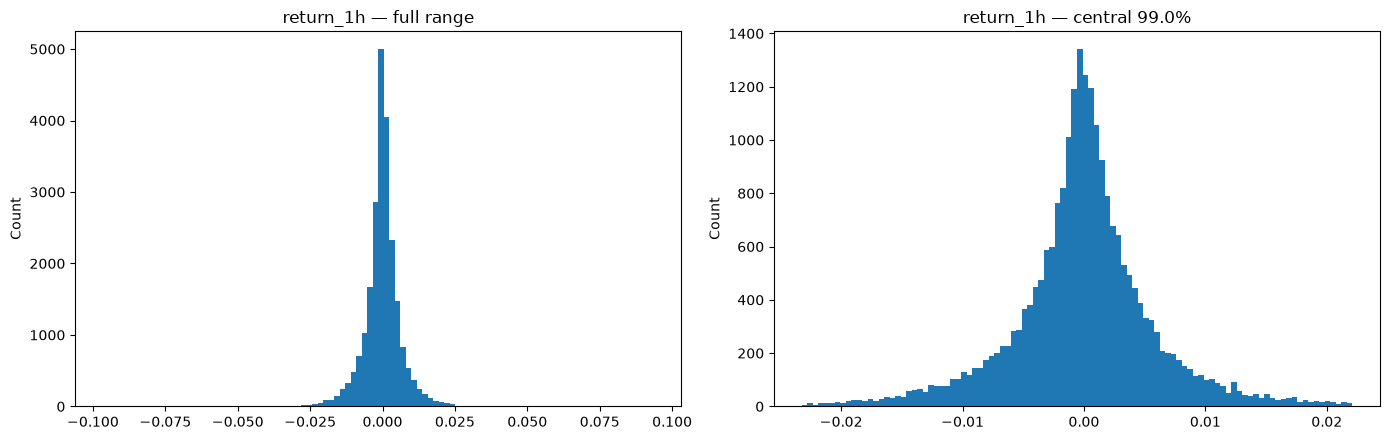

n=23,205 | central bounds [-0.0234385, 0.0221471] | min=-0.0966104 | max=0.0936103


In [6]:
return_cols = available_groups["returns"]

return_pooled = feature_summary(features, return_cols)
return_by_asset = feature_summary(features, return_cols, group_col="underlying")

display(return_pooled)
display(return_by_asset)

for col in return_cols:
    plot_full_and_central(features, col)

## 7. Per-asset return shape and empirical CDF

Pooled returns can hide substantial differences between BTC, ETH, and smaller underlyings. The ECDF provides a distribution comparison that does not depend on histogram bin choices.

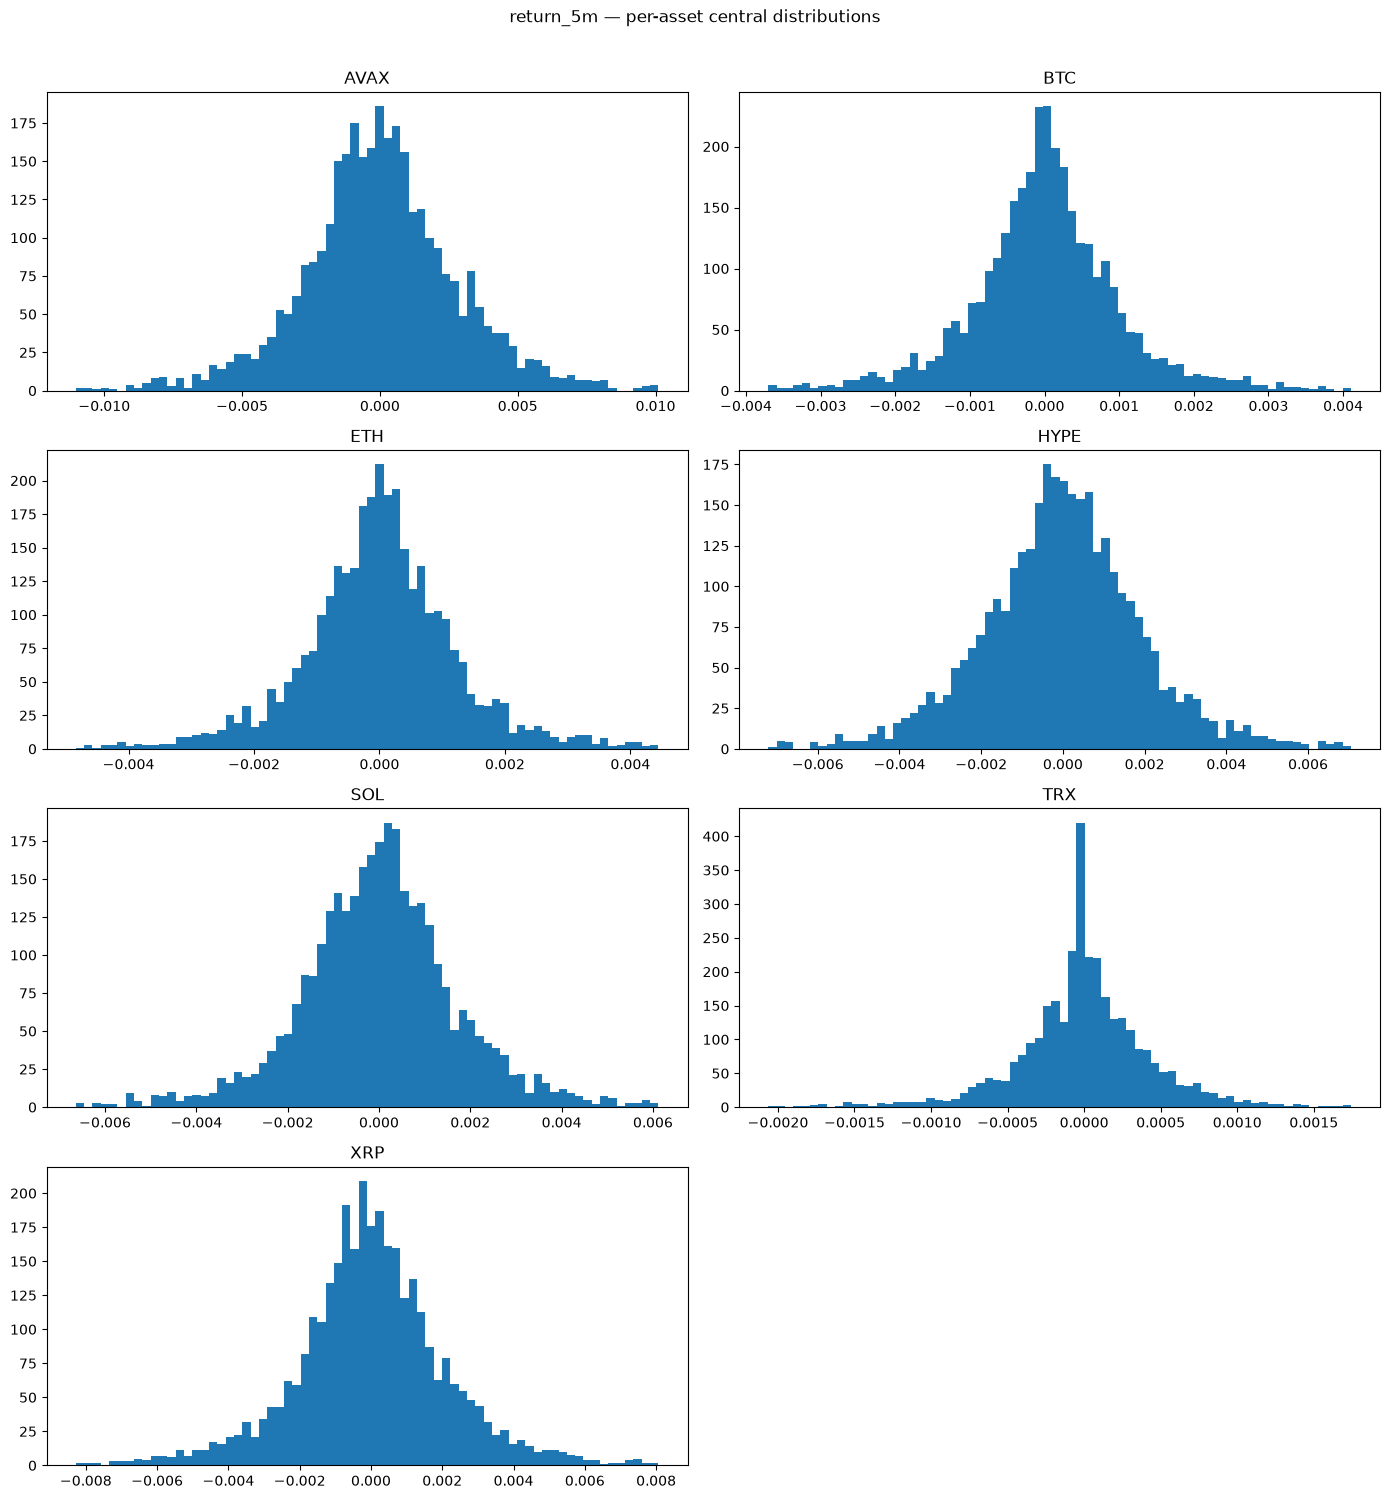

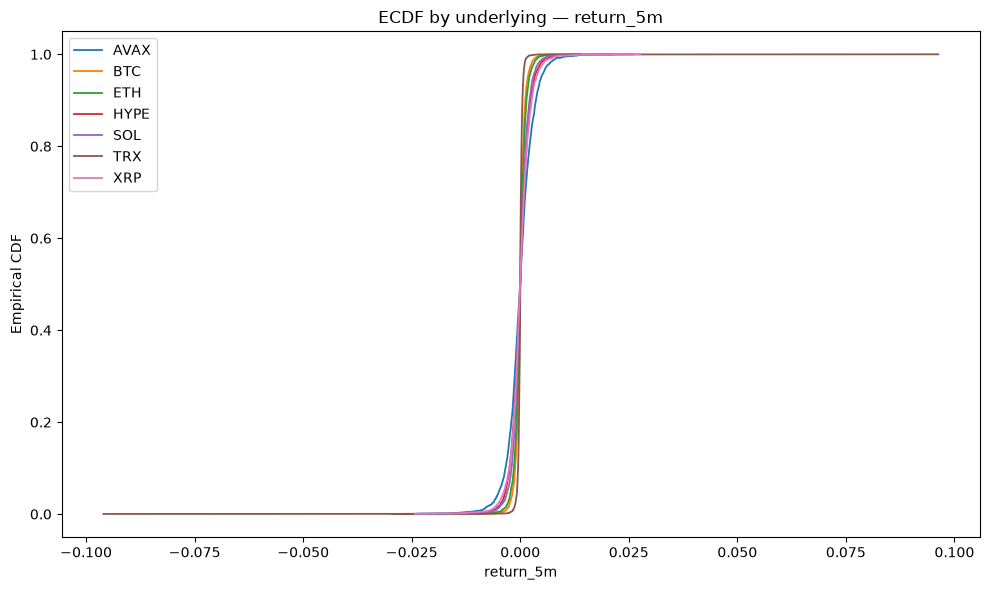

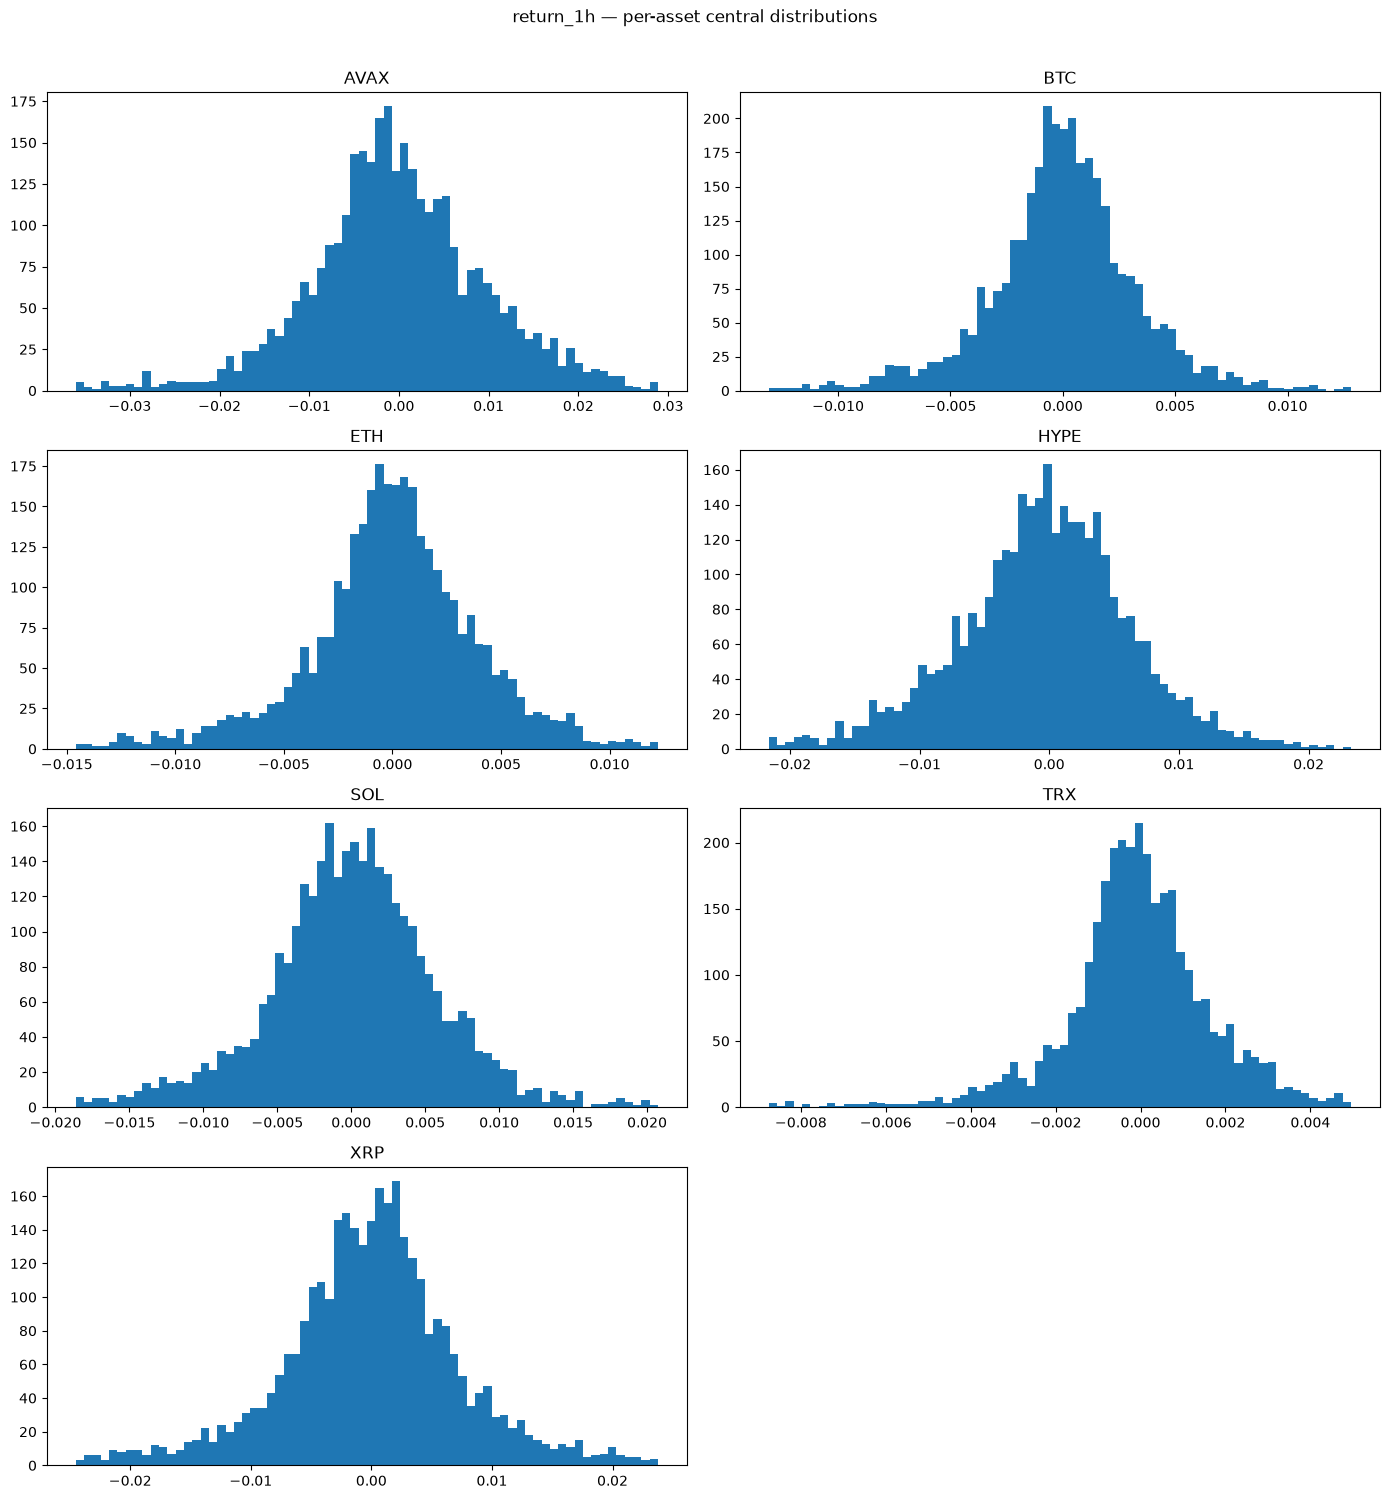

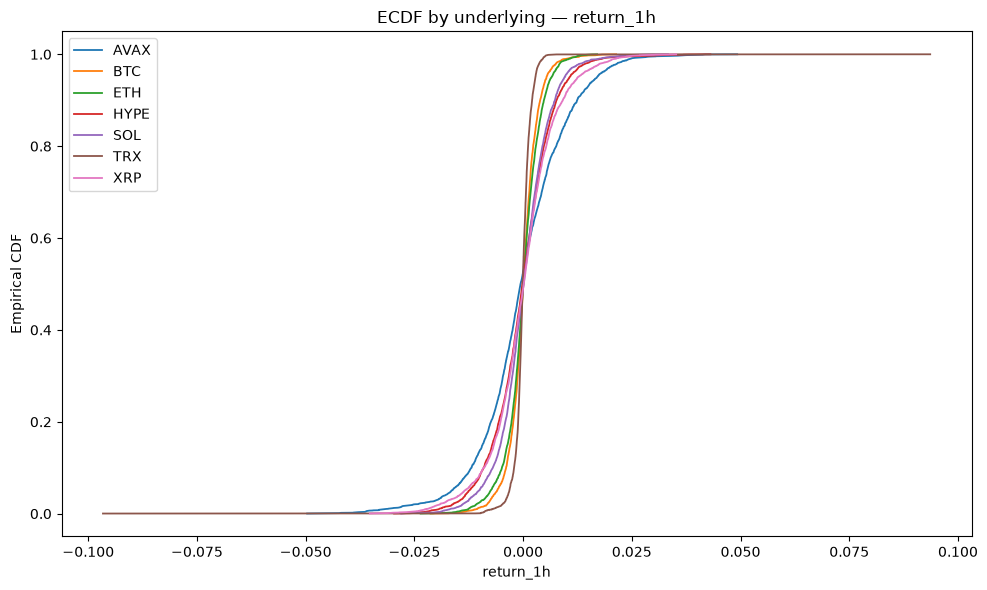

In [7]:
if "return_5m" in features.columns:
    plot_asset_histograms(features, "return_5m")
    plot_ecdf_by_asset(features, "return_5m")

if "return_1h" in features.columns:
    plot_asset_histograms(features, "return_1h")
    plot_ecdf_by_asset(features, "return_1h")

## 8. Absolute-return tails

For structural-regime research, the magnitude process can be as important as the signed return itself.

This section compares absolute 5-minute returns by underlying and lists the largest observed events without removing them.

In [8]:
if "return_5m" in features.columns:
    abs_return_rows = []

    for asset, group in features.groupby("underlying"):
        s = clean_numeric(group, "return_5m").abs()
        if s.empty:
            continue

        q = s.quantile([0.50, 0.90, 0.95, 0.99, 0.999])

        abs_return_rows.append({
            "underlying": asset,
            "n": len(s),
            "median_abs_return": q.loc[0.50],
            "q90_abs_return": q.loc[0.90],
            "q95_abs_return": q.loc[0.95],
            "q99_abs_return": q.loc[0.99],
            "q999_abs_return": q.loc[0.999],
            "max_abs_return": s.max(),
        })

    display(pd.DataFrame(abs_return_rows).sort_values("q99_abs_return", ascending=False))

    print("Largest absolute 5-minute returns:")
    display(contextual_extremes(features, "return_5m", n=25, absolute=True))

,underlying,n,median_abs_return,q90_abs_return,q95_abs_return,q99_abs_return,q999_abs_return,max_abs_return
0,AVAX,3331,0.001613,0.004849,0.006180,0.010698,0.023731,0.029578
6,XRP,3331,0.001174,0.003715,0.004892,0.008196,0.020094,0.027682
3,HYPE,3331,0.001154,0.003348,0.004400,0.007139,0.012918,0.028815
4,SOL,3331,0.000991,0.002954,0.003883,0.006475,0.012393,0.021125
2,ETH,3331,0.000675,0.002135,0.002814,0.004751,0.008610,0.014017
1,BTC,3331,0.000522,0.001751,0.002364,0.004079,0.006778,0.011679
5,TRX,3331,0.000217,0.000731,0.001002,0.001895,0.005634,0.096277


Largest absolute 5-minute returns:


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,perpetual_mid_vs_index_bps,book_twa_obi_20,book_twa_spread_bps
0,AVAX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,AVAX,2026-09-22,890,0.026031,2.663451,3.480952e+04,0.313985,520.985361,2.367802e+02,NaN,NaN
1,TRX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,TRX,2026-09-22,890,0.096277,9.012534,0.000000e+00,NaN,2139.637859,1.012713e+03,NaN,NaN
2,XRP|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,XRP,2026-09-22,890,0.027682,2.687570,4.653610e+04,0.957072,485.956891,2.223409e+02,NaN,NaN
3,AVAX|2026-09-21T17:15:00Z,2026-09-21 17:15:00+00:00,AVAX,2026-09-22,885,-0.029578,3.841447,4.765067e+04,-0.263110,5.466472,-1.001183e+01,NaN,NaN
4,TRX|2026-09-21T17:15:00Z,2026-09-21 17:15:00+00:00,TRX,2026-09-22,885,-0.096015,12.727235,0.000000e+00,NaN,2.030899,6.183556e+00,NaN,NaN
5,XRP|2026-09-21T17:15:00Z,2026-09-21 17:15:00+00:00,XRP,2026-09-22,885,-0.024263,3.517523,9.971089e+05,0.276447,2.676839,0.000000e+00,NaN,NaN
6,AVAX|2026-09-23T12:05:00Z,2026-09-23 12:05:00+00:00,AVAX,2026-09-24,1195,-0.022974,2.404836,5.771174e+05,-0.050456,5.522319,4.604052e+00,0.453480,11.740181
7,XRP|2026-09-23T14:15:00Z,2026-09-23 14:15:00+00:00,XRP,2026-09-24,1065,-0.015948,NaN,2.537395e+06,-0.053173,5.196155,4.548704e+00,0.007671,7.154034
8,AVAX|2026-09-23T14:20:00Z,2026-09-23 14:20:00+00:00,AVAX,2026-09-24,1060,-0.024104,NaN,5.888766e+05,-0.000998,7.714561,2.220446e-12,0.557972,34.796050
9,XRP|2026-09-23T14:20:00Z,2026-09-23 14:20:00+00:00,XRP,2026-09-24,1060,-0.016668,NaN,5.666636e+05,0.115584,3.302183,9.907530e-01,0.051252,5.845055


## 9. Return autocorrelation

Short-horizon return autocorrelation is checked per asset on the actual five-minute grid.

This diagnostic can later help distinguish low directional persistence, momentum-like persistence, anti-persistence / mean-reversion signatures, and microstructure effects. It is **not** yet a regime label.

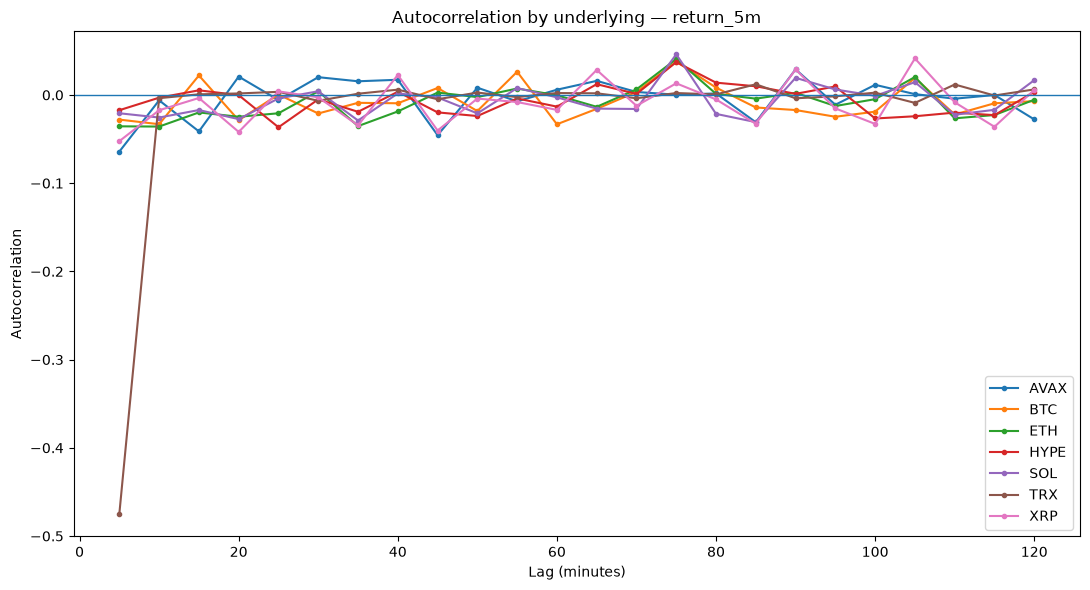

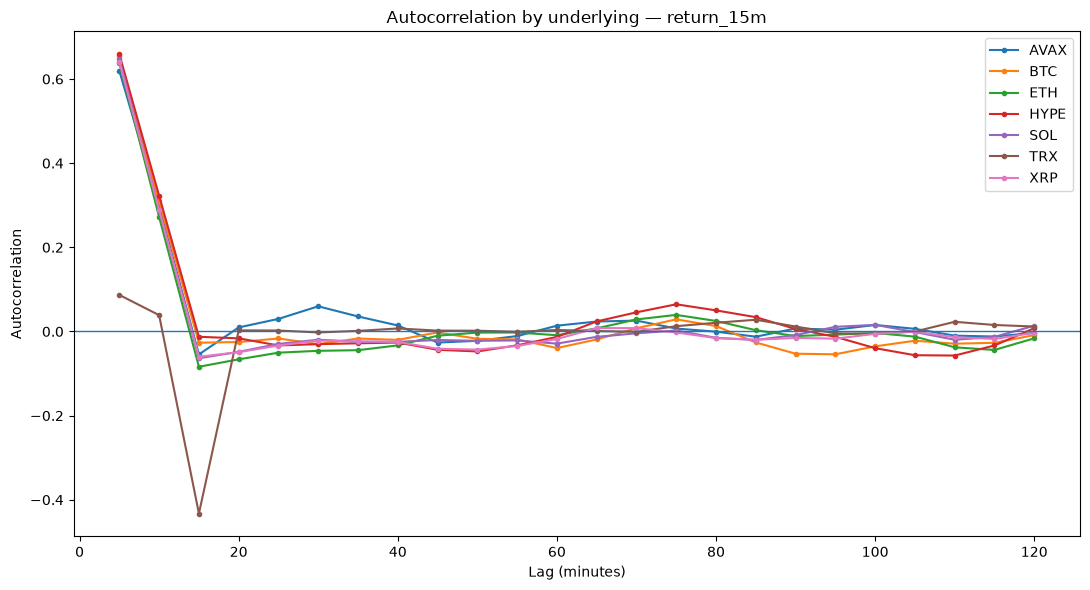

,underlying,feature,lag,lag_minutes,n_pairs,acf
0,AVAX,return_5m,1,5,3287,-0.064178
1,AVAX,return_5m,2,10,3246,-0.006093
2,AVAX,return_5m,3,15,3247,-0.041315
3,AVAX,return_5m,4,20,3244,0.020803
4,AVAX,return_5m,5,25,3240,-0.005760
5,AVAX,return_5m,6,30,3238,0.020152
6,AVAX,return_5m,7,35,3237,0.015504
7,AVAX,return_5m,8,40,3234,0.017211
8,AVAX,return_5m,9,45,3233,-0.045596
9,AVAX,return_5m,10,50,3235,0.008229


In [9]:
return_acf = {}

for col in [c for c in ["return_5m", "return_15m"] if c in features.columns]:
    return_acf[col] = plot_acf_by_asset(features, col, max_lag=24)

if "return_5m" in return_acf:
    display(return_acf["return_5m"].head(30))

# Part B — Realized Volatility

## 10. Realized-volatility distributions and effective sample size

Realized volatility is right-skewed by construction and its horizons have different readiness requirements. Sample size is therefore reported alongside every comparison.

Both raw-window and annualized forms are retained. Annualization changes scale, not information content.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,realized_vol_30m,21910,22.371032,0.003889,0.003829,12.052379,358.732018,0.000000,0.000000,0.000330,0.000641,0.003103,0.009485,0.015246,0.028143,0.135978
1,ALL,realized_vol_1h,20454,27.529762,0.005713,0.005202,9.906100,221.678990,0.000149,0.000388,0.000663,0.001049,0.004703,0.013018,0.020405,0.040636,0.135987
2,ALL,realized_vol_4h,14056,50.198413,0.012081,0.010452,6.022654,64.996063,0.001240,0.001374,0.001748,0.002289,0.010384,0.026720,0.039996,0.136021,0.136027
3,ALL,realized_vol_30m_annualized,21910,22.371032,0.514765,0.506792,12.052379,358.732018,0.000000,0.000000,0.043653,0.084834,0.410738,1.255526,2.018029,3.725082,17.998448
4,ALL,realized_vol_1h_annualized,20454,27.529762,0.534707,0.486876,9.906100,221.678990,0.013913,0.036352,0.062086,0.098181,0.440173,1.218453,1.909759,3.803325,12.727640
5,ALL,realized_vol_4h_annualized,14056,50.198413,0.565354,0.489139,6.022654,64.996063,0.058034,0.064295,0.081802,0.107125,0.485921,1.250445,1.871718,6.365427,6.365728


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,realized_vol_30m,3130,22.371032,0.006856,0.003962,2.470331,11.769713,0.000000,0.000000,0.001659,0.002473,0.005972,0.013744,0.020916,0.039834,0.040073
1,AVAX,realized_vol_1h,2922,27.529762,0.010070,0.004852,1.989019,7.365448,0.002070,0.002484,0.002873,0.004567,0.009075,0.019462,0.027272,0.041196,0.043298
2,AVAX,realized_vol_4h,2008,50.198413,0.021197,0.007439,1.150859,1.417280,0.009644,0.009713,0.010987,0.012225,0.018980,0.033956,0.046804,0.047158,0.047172
3,AVAX,realized_vol_30m_annualized,3130,22.371032,0.907512,0.524416,2.470331,11.769713,0.000000,0.000000,0.219564,0.327272,0.790503,1.819228,2.768522,5.272518,5.304175
4,AVAX,realized_vol_1h_annualized,2922,27.529762,0.942534,0.454123,1.989019,7.365448,0.193717,0.232446,0.268943,0.427468,0.849413,1.821505,2.552551,3.855702,4.052506
5,AVAX,realized_vol_4h_annualized,2008,50.198413,0.991958,0.348144,1.150859,1.417280,0.451334,0.454542,0.514184,0.572111,0.888194,1.589067,2.190317,2.206863,2.207535
6,BTC,realized_vol_30m,3130,22.371032,0.002296,0.001517,2.080714,6.977326,0.000000,0.000000,0.000369,0.000669,0.001923,0.005229,0.007788,0.012220,0.012288
7,BTC,realized_vol_1h,2922,27.529762,0.003346,0.001928,1.641285,4.078005,0.000406,0.000438,0.000713,0.001103,0.002954,0.007174,0.010259,0.013656,0.014484
8,BTC,realized_vol_4h,2008,50.198413,0.006784,0.003114,0.725452,0.562087,0.001836,0.001846,0.002006,0.002230,0.006473,0.012380,0.015121,0.018407,0.018454
9,BTC,realized_vol_30m_annualized,3130,22.371032,0.303941,0.200818,2.080714,6.977326,0.000000,0.000000,0.048879,0.088560,0.254516,0.692131,1.030805,1.617465,1.626446


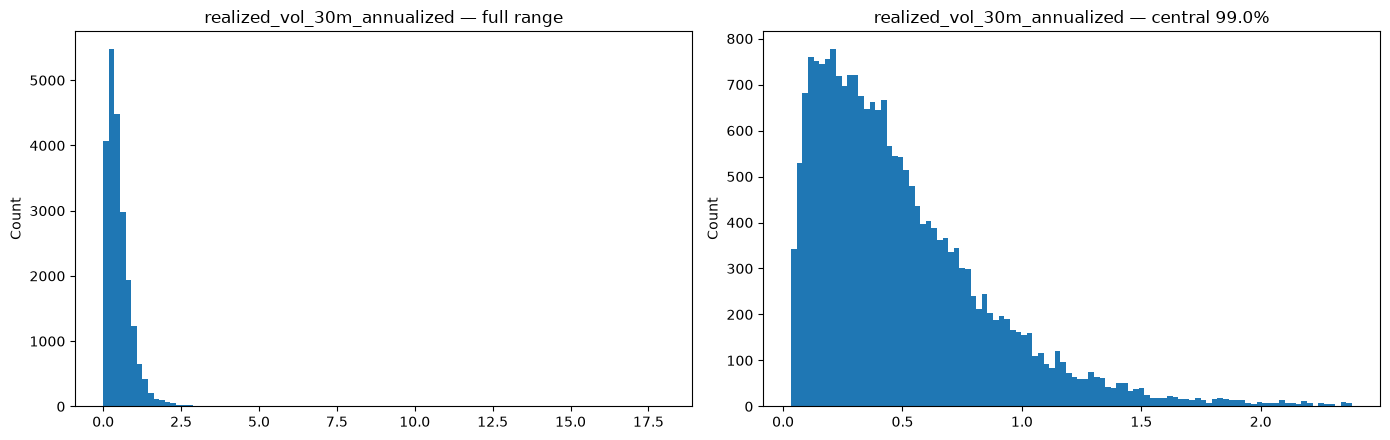

n=21,910 | central bounds [0.0339783, 2.38415] | min=0 | max=17.9984


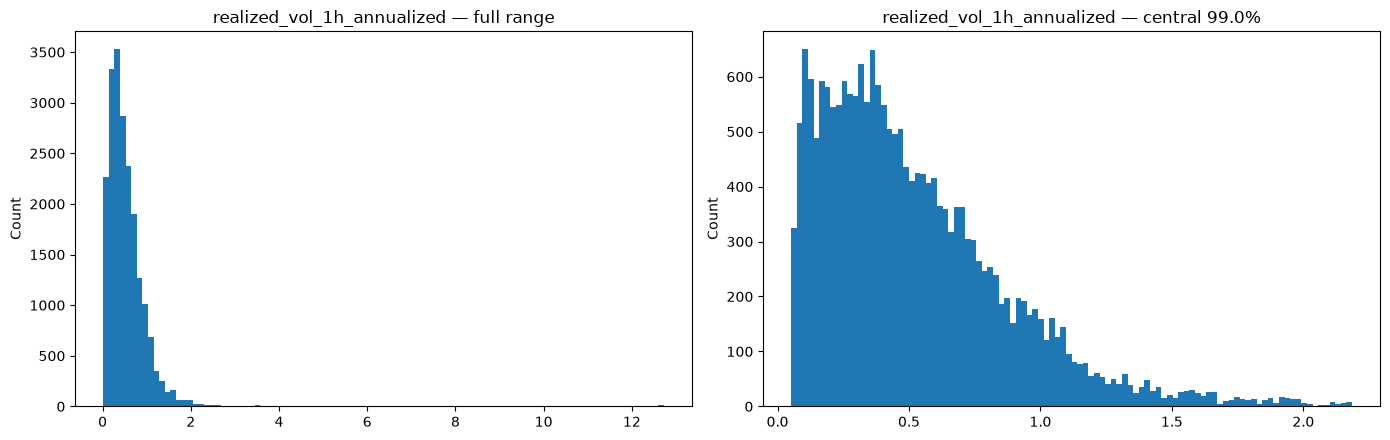

n=20,454 | central bounds [0.051852, 2.18994] | min=0.013913 | max=12.7276


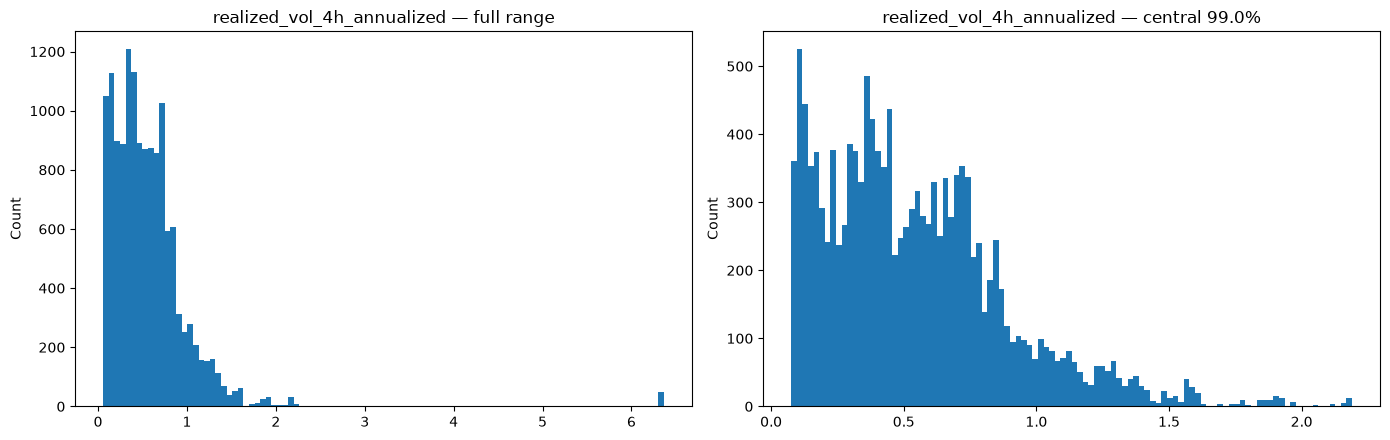

n=14,056 | central bounds [0.0757436, 2.1901] | min=0.0580344 | max=6.36573


In [10]:
rv_cols = available_groups["realized_volatility"]

rv_summary = feature_summary(features, rv_cols)
rv_by_asset = feature_summary(features, rv_cols, group_col="underlying")

display(rv_summary)
display(rv_by_asset)

for col in [
    c for c in [
        "realized_vol_30m_annualized",
        "realized_vol_1h_annualized",
        "realized_vol_4h_annualized",
    ]
    if c in features.columns
]:
    plot_full_and_central(features, col)

## 11. Volatility persistence

Persistent volatility is a plausible structural-state input. We therefore inspect autocorrelation independently for each underlying.

Longer-horizon realized-volatility features mechanically overlap, so high autocorrelation is expected. The question is **how persistent and how asset-dependent** it is, not whether the ACF is statistically zero.

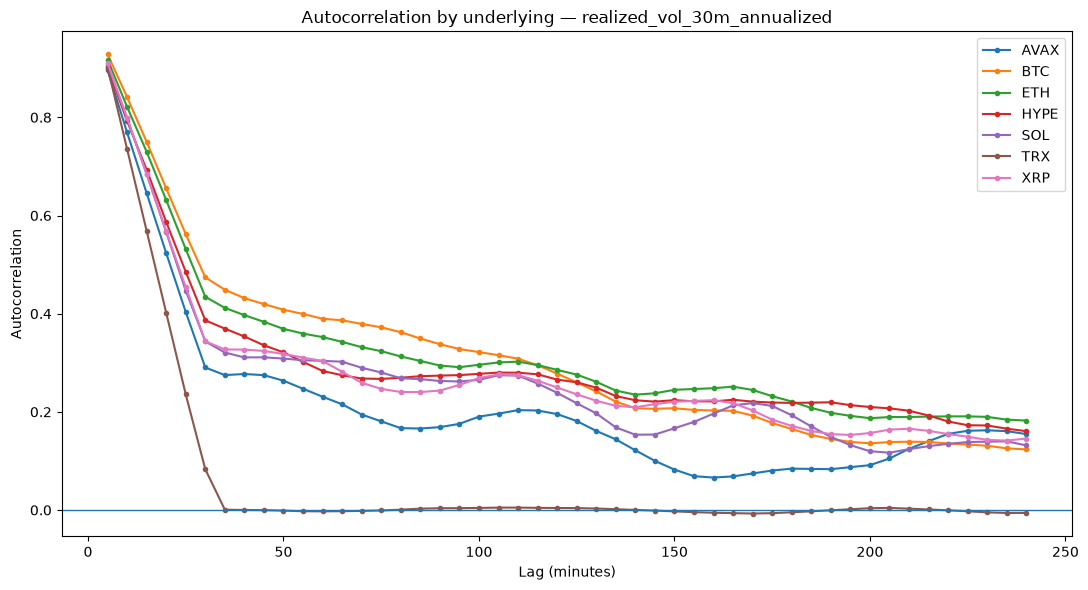

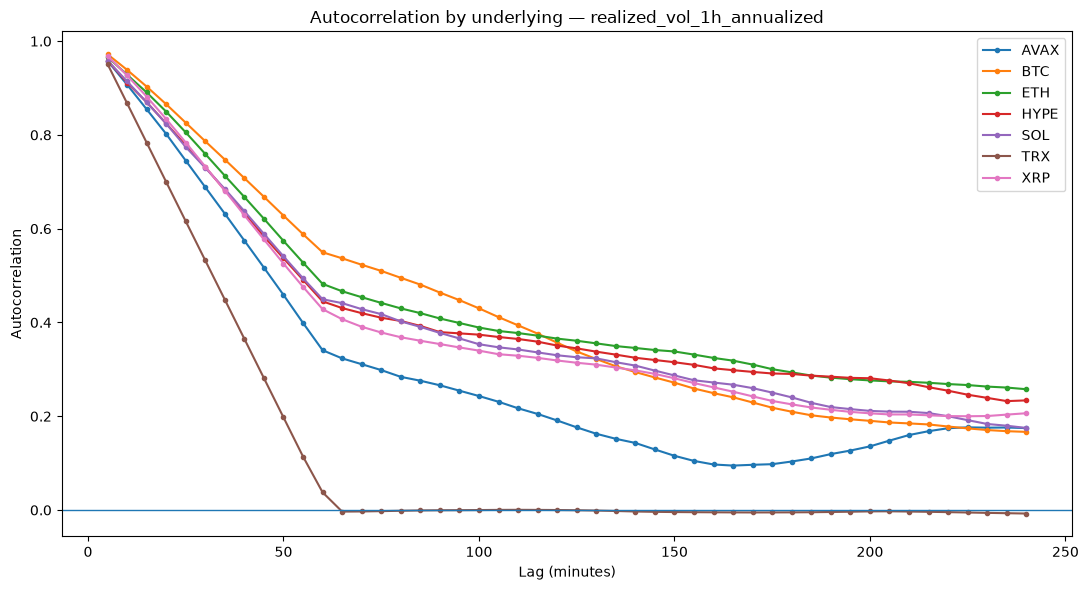

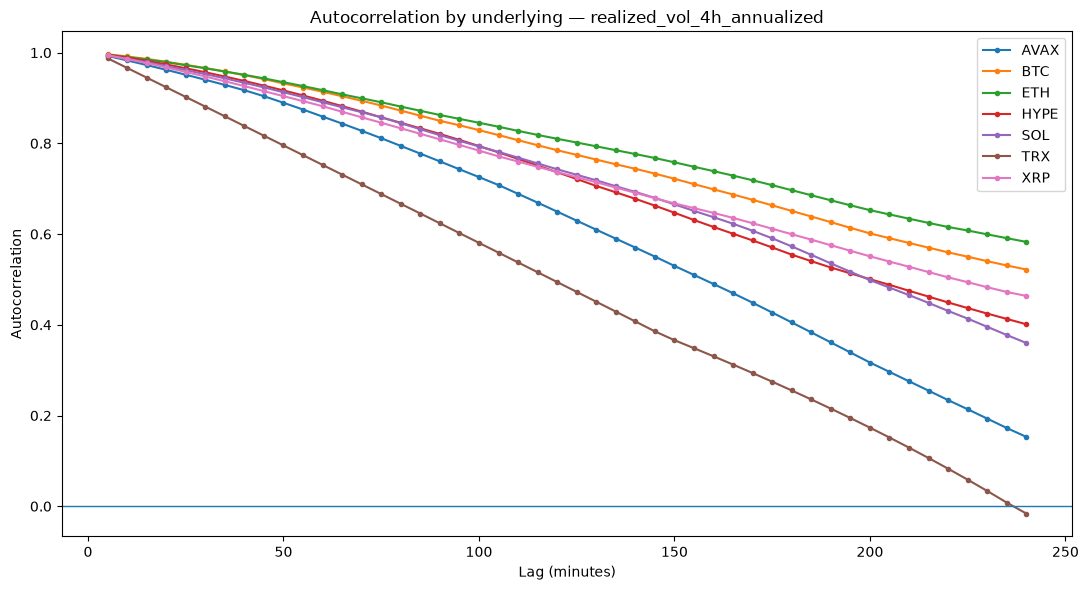

In [11]:
rv_acf = {}

for col in [
    c for c in [
        "realized_vol_30m_annualized",
        "realized_vol_1h_annualized",
        "realized_vol_4h_annualized",
    ]
    if c in features.columns
]:
    rv_acf[col] = plot_acf_by_asset(features, col, max_lag=48)

# Part C — Activity and Trade Flow

## 12. Volume, trade size, and flow distributions

The activity block contains several fundamentally different supports:

- volume and trade size are non-negative and typically long-tailed;
- signed volume is unbounded in both directions;
- trade-flow imbalance lies in `[-1, 1]`;
- buy-volume share lies in `[0, 1]`.

Boundary masses at `-1`, `0`, or `+1` are treated as real features of the data rather than as histogram artifacts.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,volume_usd,23961,15.104167,204457.551225,1.024069e+06,41.773862,3382.104714,0.000000e+00,0.000000e+00,0.000000,0.000000,14543.997850,926596.713700,3.553177e+06,9.459264e+06,9.611645e+07
1,ALL,log1p_volume_usd,23961,15.104167,8.528995,4.158616e+00,-0.904741,-0.067565,0.000000e+00,0.000000e+00,0.000000,0.000000,9.585002,13.739275,1.508335e+01,1.606247e+01,1.838107e+01
2,ALL,signed_volume_usd,23961,15.104167,-1951.597819,2.964763e+05,-4.945988,4240.192318,-2.370535e+07,-1.172936e+06,-257789.014382,-72040.286789,0.000000,65559.640340,2.431457e+05,8.960526e+05,2.419578e+07
3,ALL,trade_flow_imbalance,20694,26.679422,-0.015416,6.520057e-01,0.020513,-1.069728,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000,-0.003459,1.000000,1.000000e+00,1.000000e+00,1.000000e+00
4,ALL,buy_volume_share,20694,26.679422,0.492292,3.260029e-01,0.020513,-1.069728,0.000000e+00,0.000000e+00,0.000000,0.000000,0.498271,1.000000,1.000000e+00,1.000000e+00,1.000000e+00
5,ALL,average_trade_size_usd,20694,26.679422,1200.376591,9.451265e+03,62.509845,4555.749436,1.019400e-02,3.620277e-01,1.456829,9.907169,546.022150,3358.564058,7.193076e+03,3.203055e+04,8.202439e+05
6,ALL,trade_count,23961,15.104167,192.296148,3.614149e+02,4.802206,40.113453,0.000000e+00,0.000000e+00,0.000000,0.000000,39.000000,806.000000,1.669000e+03,3.867320e+03,7.175000e+03


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,volume_usd,3423,15.104167,1.798498e+04,3.655851e+04,8.916230,119.041640,0.000000e+00,0.000000e+00,0.000000,0.000000,7852.591124,6.285285e+04,1.490559e+05,5.743579e+05,6.417546e+05
1,AVAX,log1p_volume_usd,3423,15.104167,8.499342e+00,2.503312e+00,-2.167460,5.031302,0.000000e+00,0.000000e+00,0.000000,0.000000,8.968726,1.104857e+01,1.191196e+01,1.326099e+01,1.337196e+01
2,AVAX,signed_volume_usd,3423,15.104167,4.114474e+02,1.413700e+04,-0.411602,41.921761,-2.100080e+05,-9.651021e+04,-39028.664522,-17295.910363,0.000000,1.918364e+04,4.199614e+04,1.160511e+05,1.582488e+05
3,AVAX,trade_flow_imbalance,3234,19.791667,6.277863e-03,6.852396e-01,-0.009487,-1.267013,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000,0.000495,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
4,AVAX,buy_volume_share,3234,19.791667,5.031389e-01,3.426198e-01,-0.009487,-1.267013,0.000000e+00,0.000000e+00,0.000000,0.000000,0.500247,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
5,AVAX,average_trade_size_usd,3234,19.791667,8.790252e+02,1.031975e+03,16.771456,506.621211,1.019400e-02,2.575269e-01,23.693948,127.836252,730.993525,2.109411e+03,3.347095e+03,1.184101e+04,3.720554e+04
6,AVAX,trade_count,3423,15.104167,2.511335e+01,4.173705e+01,6.420867,73.935264,0.000000e+00,0.000000e+00,0.000000,0.000000,12.000000,9.100000e+01,1.757800e+02,5.094320e+02,7.750000e+02
7,BTC,volume_usd,3423,15.104167,1.108106e+06,2.392861e+06,20.853925,751.335766,0.000000e+00,0.000000e+00,15875.574482,47102.373275,566285.518840,4.182139e+06,8.053826e+06,1.686781e+07,9.611645e+07
8,BTC,log1p_volume_usd,3423,15.104167,1.309649e+01,1.444586e+00,-1.640098,12.164342,0.000000e+00,0.000000e+00,9.672515,10.760084,13.246855,1.524633e+01,1.590164e+01,1.663996e+01,1.838107e+01
9,BTC,signed_volume_usd,3423,15.104167,-6.567093e+03,6.522887e+05,0.345807,1083.857708,-2.370535e+07,-2.809266e+06,-686518.726622,-218103.921089,8.400000,1.945173e+05,6.066706e+05,1.719639e+06,2.419578e+07


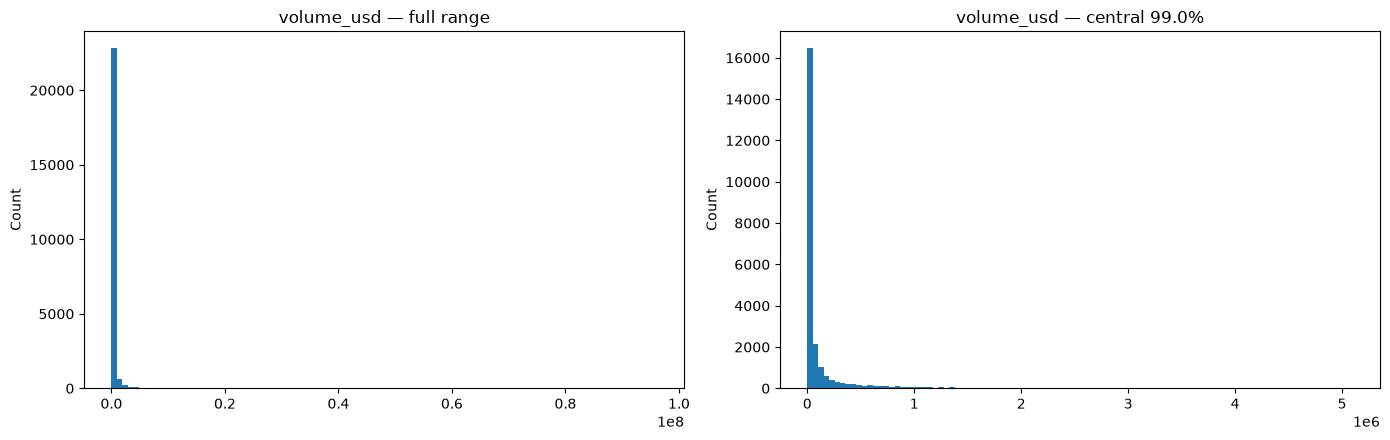

n=23,961 | central bounds [0, 5.10103e+06] | min=0 | max=9.61164e+07


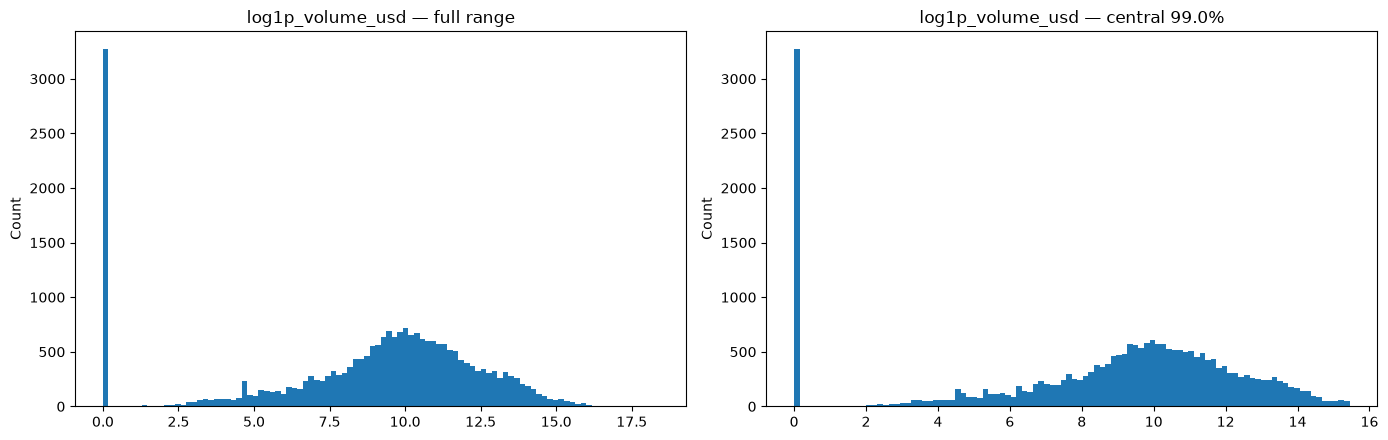

n=23,961 | central bounds [0, 15.445] | min=0 | max=18.3811


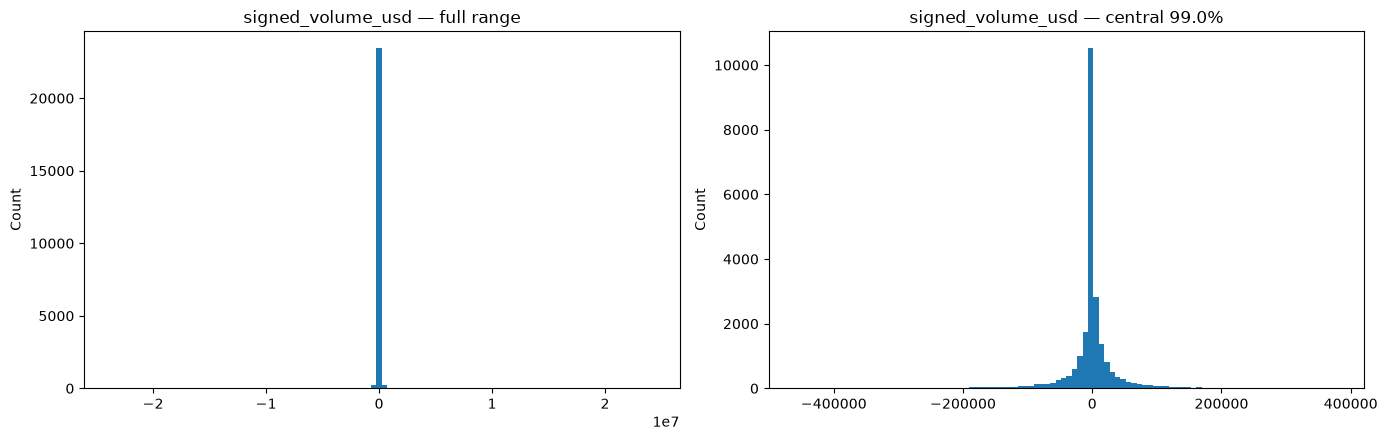

n=23,961 | central bounds [-459161, 379972] | min=-2.37054e+07 | max=2.41958e+07


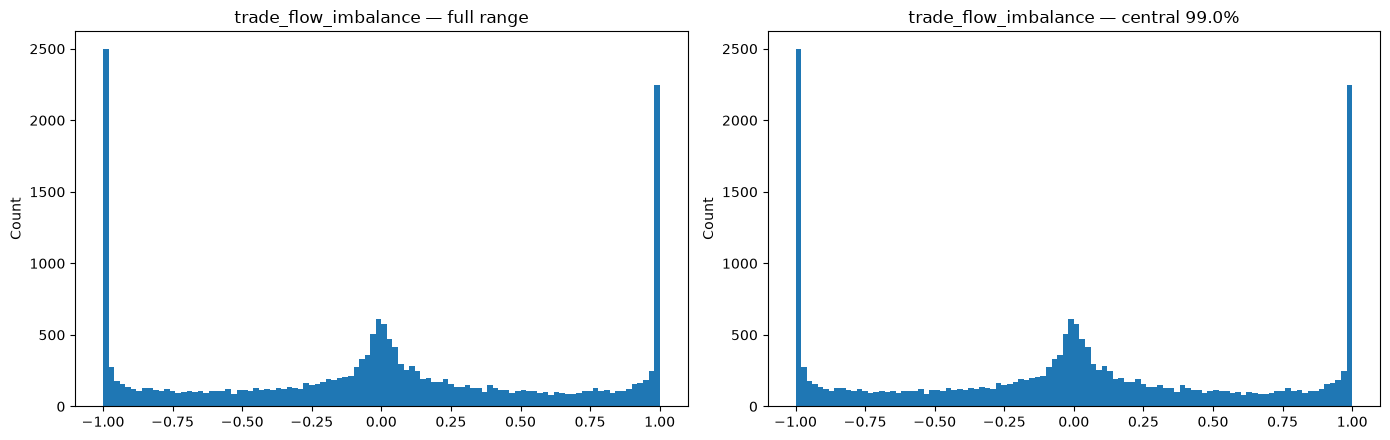

n=20,694 | central bounds [-1, 1] | min=-1 | max=1


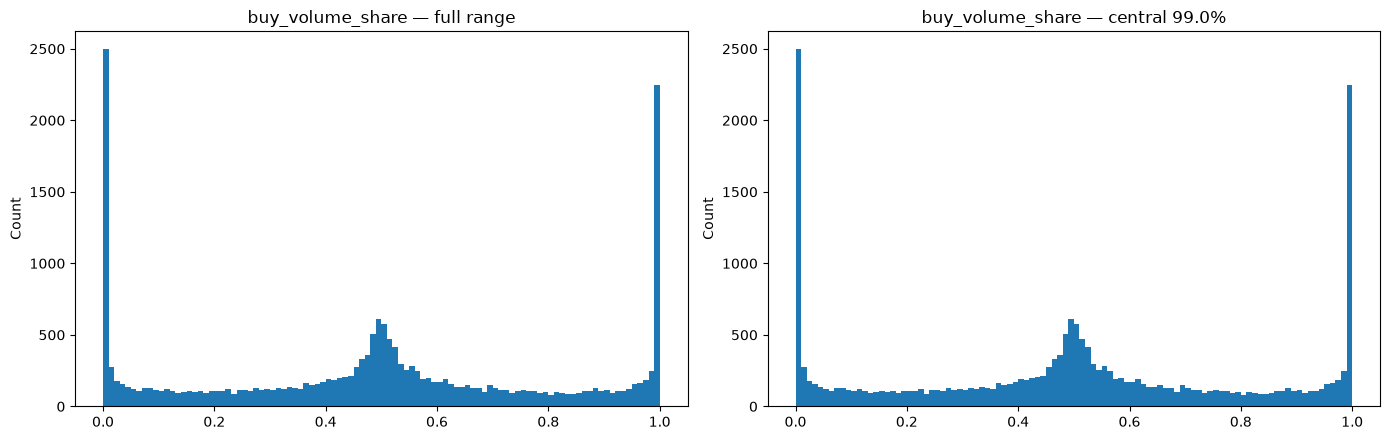

n=20,694 | central bounds [0, 1] | min=0 | max=1


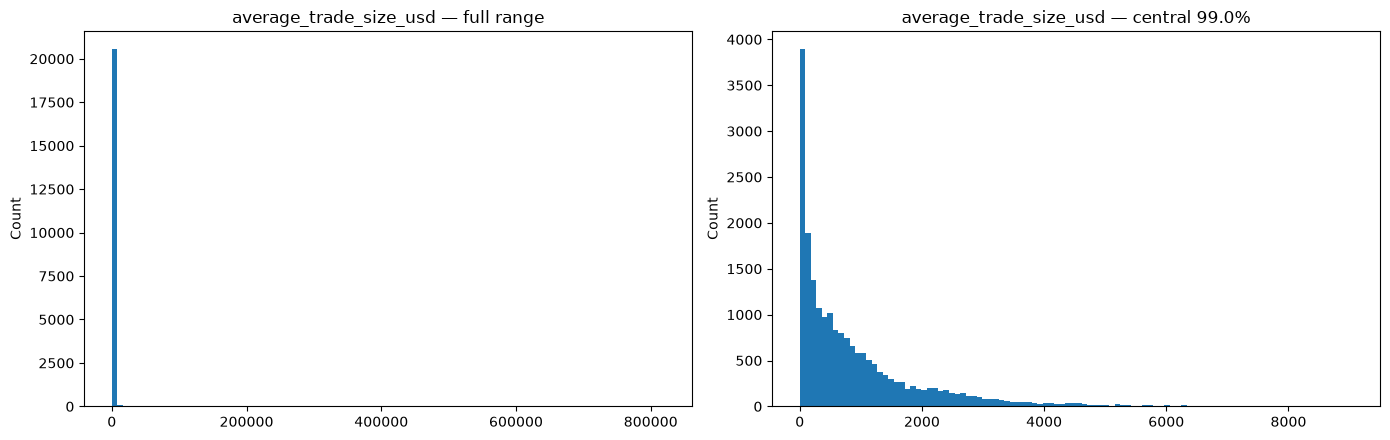

n=20,694 | central bounds [0.785453, 9054.15] | min=0.010194 | max=820244


In [12]:
activity_cols = available_groups["activity_flow"]

display(feature_summary(features, activity_cols))
display(feature_summary(features, activity_cols, group_col="underlying"))

for col in [
    c for c in [
        "volume_usd",
        "log1p_volume_usd",
        "signed_volume_usd",
        "trade_flow_imbalance",
        "buy_volume_share",
        "average_trade_size_usd",
    ]
    if c in features.columns
]:
    plot_full_and_central(features, col)

## 13. Structural probability masses: zero volume and ±1 flow

Extreme flow imbalance can occur when all observed aggressor flow in a window is one-sided. That is not equivalent to a smooth continuous observation close to ±1, so the endpoint mass is measured explicitly.

In [13]:
boundary_rows = []

for asset, group in features.groupby("underlying"):
    row = {"underlying": asset, "states": len(group)}

    if "volume_usd" in group.columns:
        vol = pd.to_numeric(group["volume_usd"], errors="coerce")
        valid = vol.notna()
        row["volume_valid_n"] = int(valid.sum())
        row["volume_zero_pct_of_valid"] = (
            100.0 * (vol[valid] == 0).mean() if valid.any() else np.nan
        )

    if "trade_flow_imbalance" in group.columns:
        flow = pd.to_numeric(group["trade_flow_imbalance"], errors="coerce")
        valid = flow.notna()
        row["flow_valid_n"] = int(valid.sum())
        row["flow_at_minus_1_pct"] = (
            100.0 * np.isclose(flow[valid], -1.0).mean() if valid.any() else np.nan
        )
        row["flow_at_plus_1_pct"] = (
            100.0 * np.isclose(flow[valid], 1.0).mean() if valid.any() else np.nan
        )
        row["flow_at_either_boundary_pct"] = (
            100.0
            * (
                np.isclose(flow[valid], -1.0)
                | np.isclose(flow[valid], 1.0)
            ).mean()
            if valid.any()
            else np.nan
        )

    if "buy_volume_share" in group.columns:
        share = pd.to_numeric(group["buy_volume_share"], errors="coerce")
        valid = share.notna()
        row["buy_share_zero_pct"] = (
            100.0 * np.isclose(share[valid], 0.0).mean() if valid.any() else np.nan
        )
        row["buy_share_one_pct"] = (
            100.0 * np.isclose(share[valid], 1.0).mean() if valid.any() else np.nan
        )

    boundary_rows.append(row)

boundary_mass = pd.DataFrame(boundary_rows).sort_values("underlying")
display(boundary_mass)

,underlying,states,volume_valid_n,volume_zero_pct_of_valid,flow_valid_n,flow_at_minus_1_pct,flow_at_plus_1_pct,flow_at_either_boundary_pct,buy_share_zero_pct,buy_share_one_pct
0,AVAX,4032,3423,5.521472,3234,12.121212,11.842919,23.964131,12.121212,11.904762
1,BTC,4032,3423,0.175285,3417,0.029265,0.029265,0.058531,0.029265,0.029265
2,ETH,4032,3423,0.204499,3416,0.000000,0.029274,0.029274,0.000000,0.029274
3,HYPE,4032,3423,19.953257,2740,22.591241,26.532847,49.124088,22.554745,26.532847
4,SOL,4032,3423,0.204499,3416,0.029274,0.000000,0.029274,0.029274,0.000000
5,TRX,4032,3423,62.722758,1276,53.683386,29.153605,82.836991,53.683386,29.153605
6,XRP,4032,3423,6.660824,3195,9.796557,7.699531,17.496088,9.796557,7.699531


## 14. Activity persistence

Volume and trade intensity often cluster. Flow direction may behave very differently.

That distinction matters for the later structural/noise split: a highly persistent activity state is not the same phenomenon as rapidly alternating signed flow.

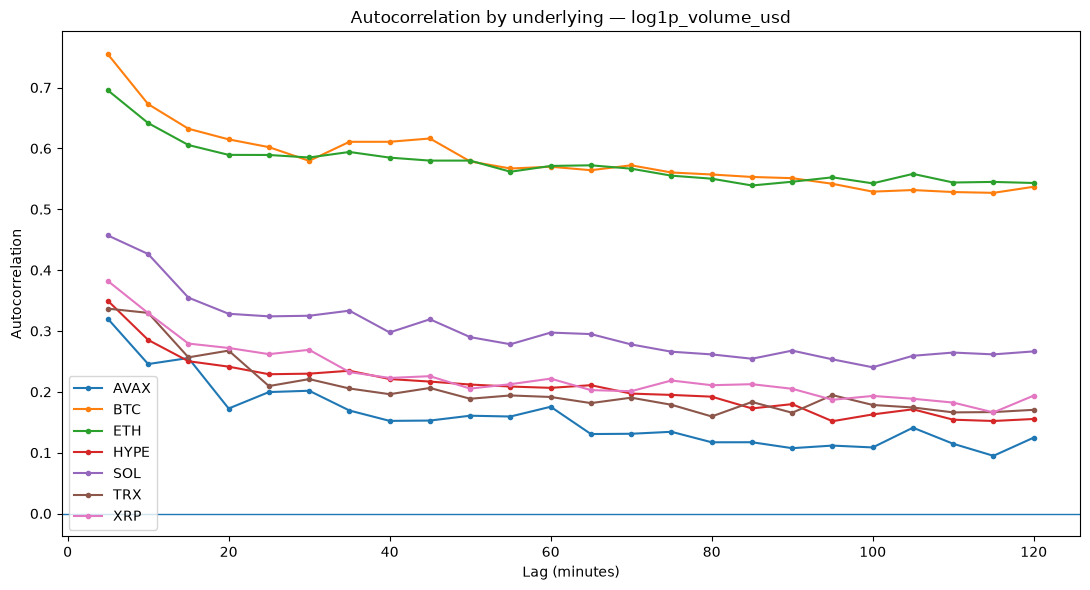

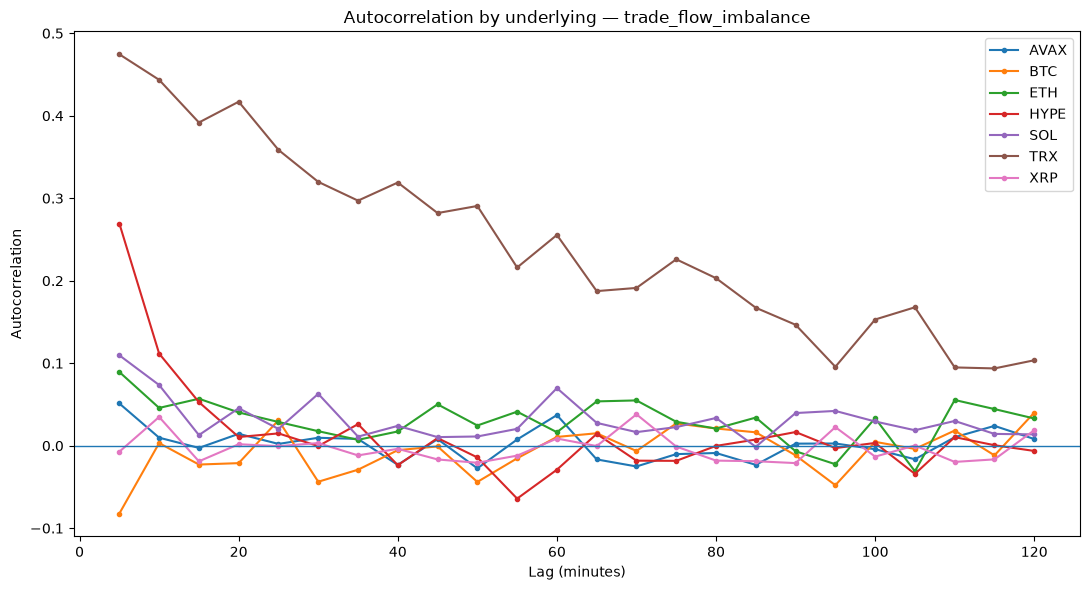

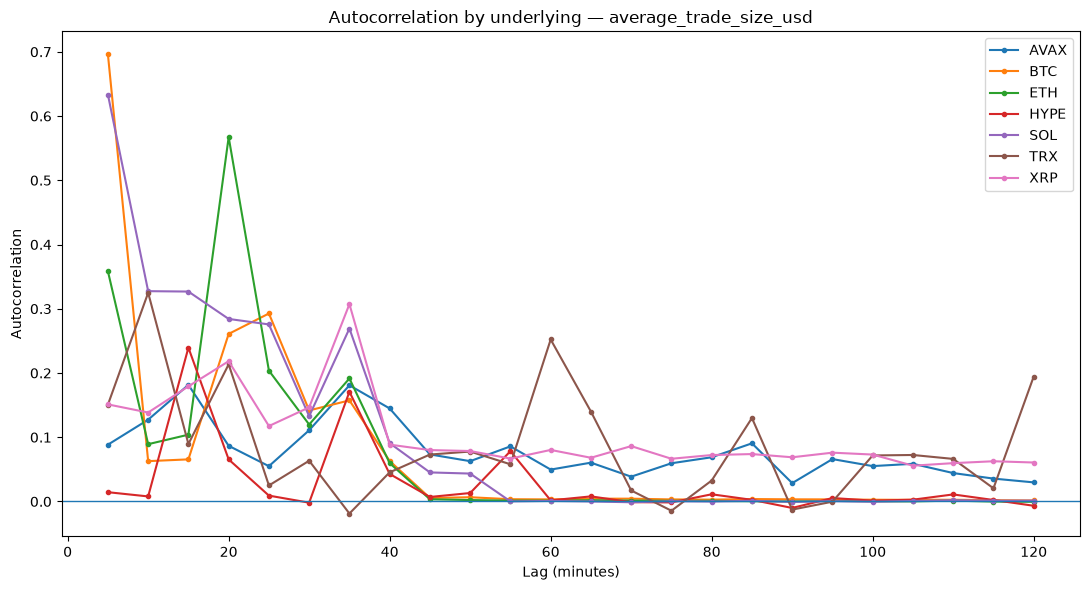

In [14]:
for col in [
    c for c in [
        "log1p_volume_usd",
        "trade_flow_imbalance",
        "average_trade_size_usd",
    ]
    if c in features.columns
]:
    plot_acf_by_asset(features, col, max_lag=24)

# Part D — Price-Bar Structure and Open Interest

## 15. Intrabar range, VWAP relation, and open-interest changes

`close_vs_vwap_bps` is the close relative to the **five-minute bar VWAP**. It is not yet the longer-horizon/session VWAP displacement envisioned for later structural research.

Open-interest changes are kept in both level-change and proportional-return form because asset scale may matter.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,intrabar_range_bps,20689,26.697137,2.059756e+01,2.033173e+01,3.429338,29.645185,0.000000,0.000000,0.000000,0.000000,15.919415,5.688251e+01,9.200234e+01,1.791131e+02,4.499671e+02
1,ALL,close_vs_vwap_bps,20694,26.679422,3.381841e-02,1.010044e+01,-0.074194,8.808373,-126.822025,-50.691897,-29.696160,-15.352201,0.000000,1.561805e+01,3.082451e+01,5.224856e+01,9.314506e+01
2,ALL,open_interest,23940,15.178571,1.188674e+06,1.859937e+06,1.555826,1.103857,436.458100,443.180871,447.521225,459.156920,211405.294500,5.304965e+06,6.710137e+06,6.935430e+06,6.963908e+06
3,ALL,open_interest_change_5m,23912,15.277778,4.272551e+01,1.377800e+04,-0.865146,1902.033793,-940726.000000,-90621.008000,-20401.730000,-1796.288850,0.000000,1.662817e+03,2.158994e+04,9.078369e+04,8.736680e+05
4,ALL,open_interest_return_5m,23912,15.277778,1.570596e-04,1.101563e-02,54.661270,3861.348200,-0.220090,-0.031761,-0.007835,-0.002550,0.000000,2.734564e-03,8.283825e-03,4.469958e-02,9.361797e-01


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,intrabar_range_bps,3234,19.791667,2.965950e+01,28.697845,3.030290,22.720572,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.325113e+01,7.844364e+01,1.355572e+02,2.156231e+02,4.499671e+02
1,AVAX,close_vs_vwap_bps,3234,19.791667,-6.603642e-03,14.396102,-0.040391,4.465691,-9.759374e+01,-7.008251e+01,-3.948441e+01,-2.342418e+01,0.000000e+00,2.298781e+01,3.985588e+01,6.493252e+01,9.314506e+01
2,AVAX,open_interest,3420,15.178571,3.592545e+05,70795.586161,0.382083,-1.390427,2.623524e+05,2.624074e+05,2.645607e+05,2.707109e+05,3.333289e+05,4.691369e+05,4.876737e+05,4.933016e+05,4.936168e+05
3,AVAX,open_interest_change_5m,3416,15.277778,-5.256555e+01,1136.471646,-2.643139,165.320893,-2.689630e+04,-7.406928e+03,-2.803856e+03,-1.319043e+03,0.000000e+00,1.170236e+03,2.937917e+03,8.179420e+03,2.215199e+04
4,AVAX,open_interest_return_5m,3416,15.277778,-1.290887e-04,0.003232,0.284273,216.559593,-6.752552e-02,-1.866832e-02,-7.677179e-03,-3.600576e-03,0.000000e+00,3.334375e-03,7.925213e-03,1.943574e-02,7.990061e-02
5,BTC,intrabar_range_bps,3416,15.277778,1.514751e+01,10.849502,2.334800,9.489118,0.000000e+00,0.000000e+00,2.017853e+00,3.713575e+00,1.259889e+01,3.494503e+01,5.796739e+01,8.097506e+01,1.234923e+02
6,BTC,close_vs_vwap_bps,3417,15.252976,-1.815762e-02,6.102731,-0.322205,6.403581,-4.799011e+01,-3.435617e+01,-1.744242e+01,-9.028720e+00,-2.565989e-02,9.328288e+00,1.640106e+01,3.082633e+01,3.561547e+01
7,BTC,open_interest,3420,15.178571,6.290959e+02,375.288917,1.813849,1.301795,4.364581e+02,4.380324e+02,4.438140e+02,4.468140e+02,4.660640e+02,1.479765e+03,1.501956e+03,1.526880e+03,1.532460e+03
8,BTC,open_interest_change_5m,3416,15.277778,3.014050e-01,13.255690,48.698448,2544.745248,-4.396310e+01,-1.526739e+01,-6.381115e+00,-1.651175e+00,3.430000e-02,1.767200e+00,4.233265e+00,2.562039e+01,7.161442e+02
9,BTC,open_interest_return_5m,3416,15.277778,4.735565e-04,0.018906,43.320423,1990.667206,-3.778178e-02,-2.648711e-02,-9.357471e-03,-2.597038e-03,6.652109e-05,3.107998e-03,7.040742e-03,1.993768e-02,9.361797e-01


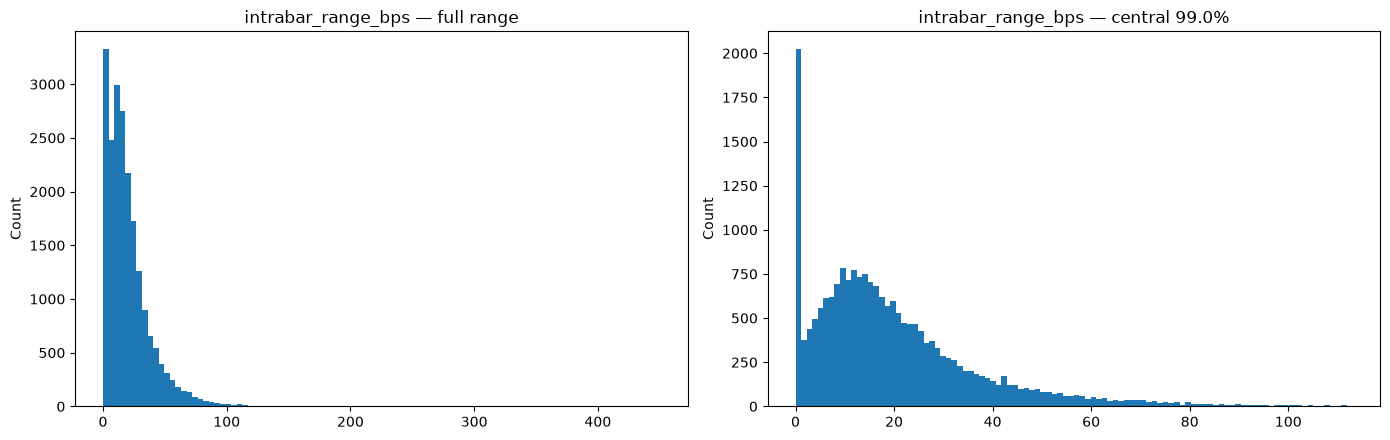

n=20,689 | central bounds [0, 113.392] | min=0 | max=449.967


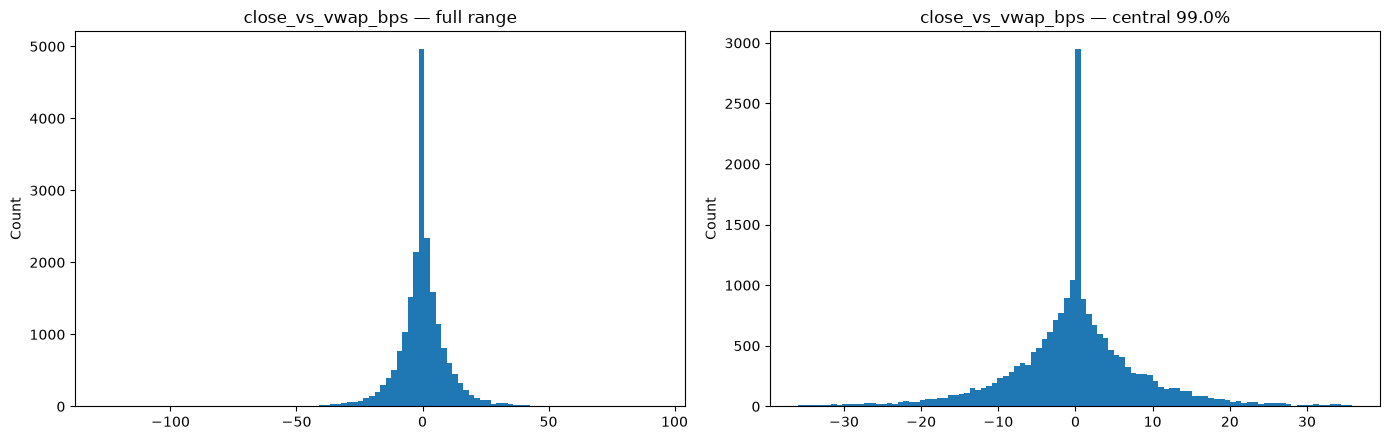

n=20,694 | central bounds [-35.9689, 36.0476] | min=-126.822 | max=93.1451


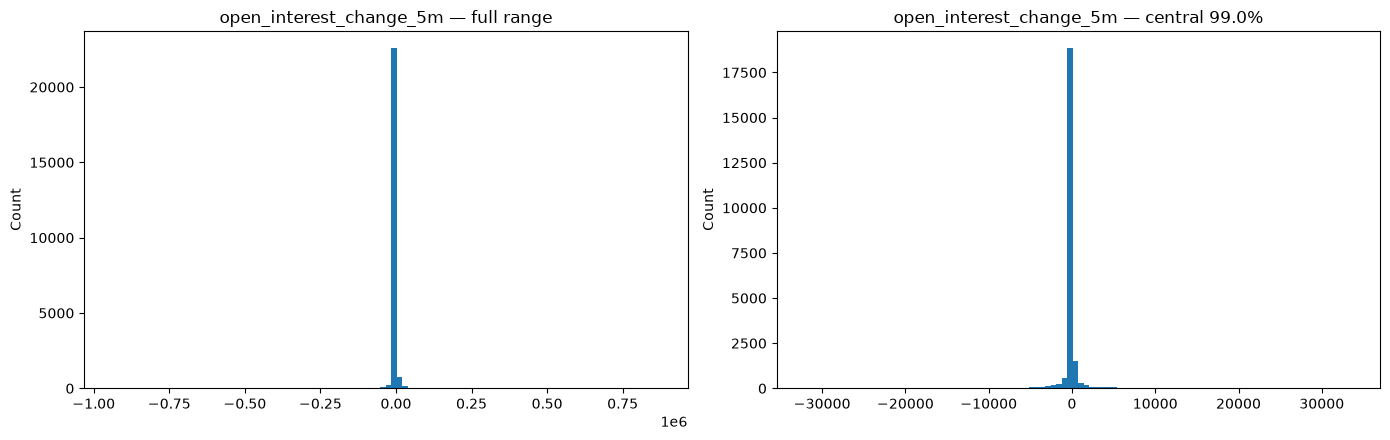

n=23,912 | central bounds [-32317, 33734.4] | min=-940726 | max=873668


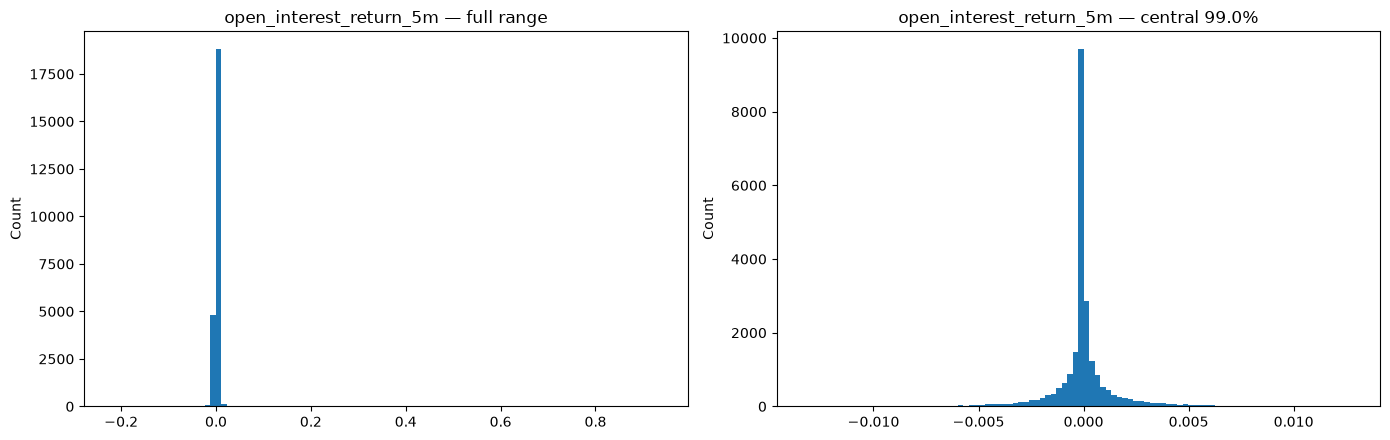

n=23,912 | central bounds [-0.013311, 0.0128043] | min=-0.22009 | max=0.93618


In [15]:
bar_oi_cols = available_groups["bar_structure_open_interest"]

display(feature_summary(features, bar_oi_cols))
display(feature_summary(features, bar_oi_cols, group_col="underlying"))

for col in [
    c for c in [
        "intrabar_range_bps",
        "close_vs_vwap_bps",
        "open_interest_change_5m",
        "open_interest_return_5m",
    ]
    if c in features.columns
]:
    plot_full_and_central(features, col)

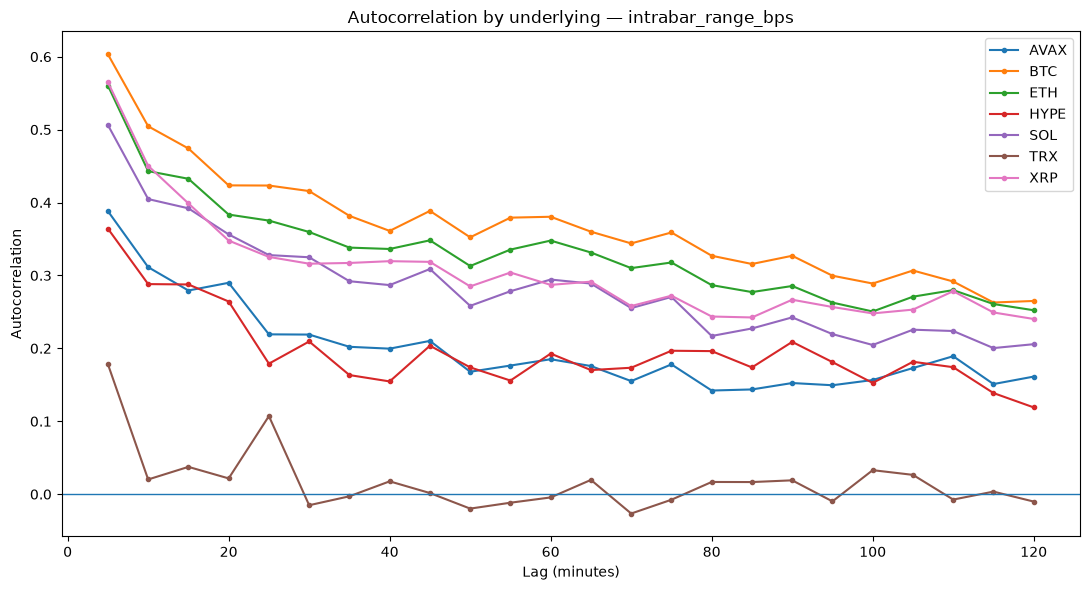

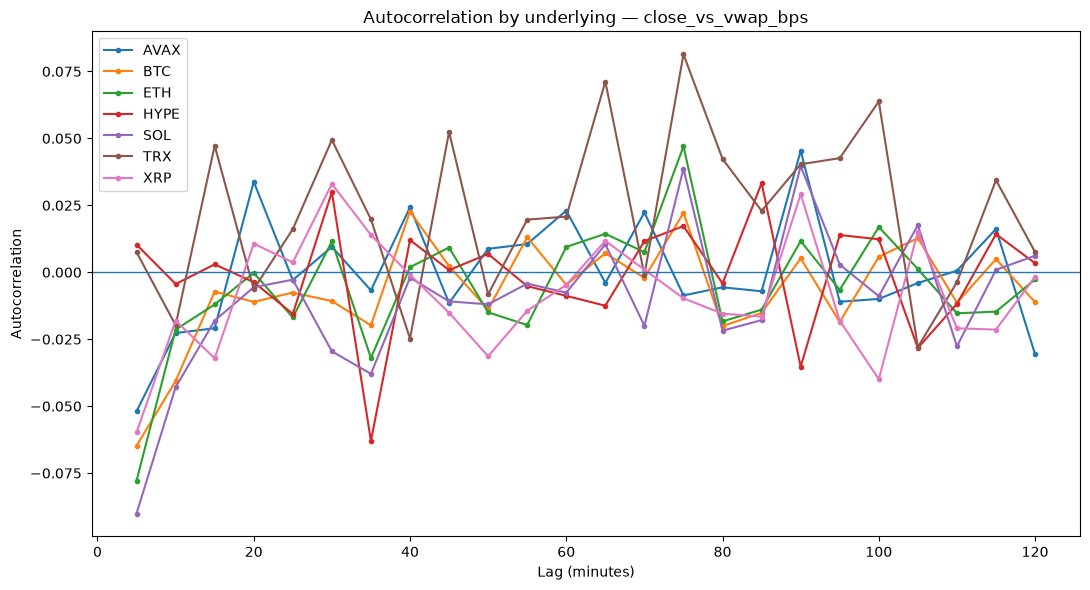

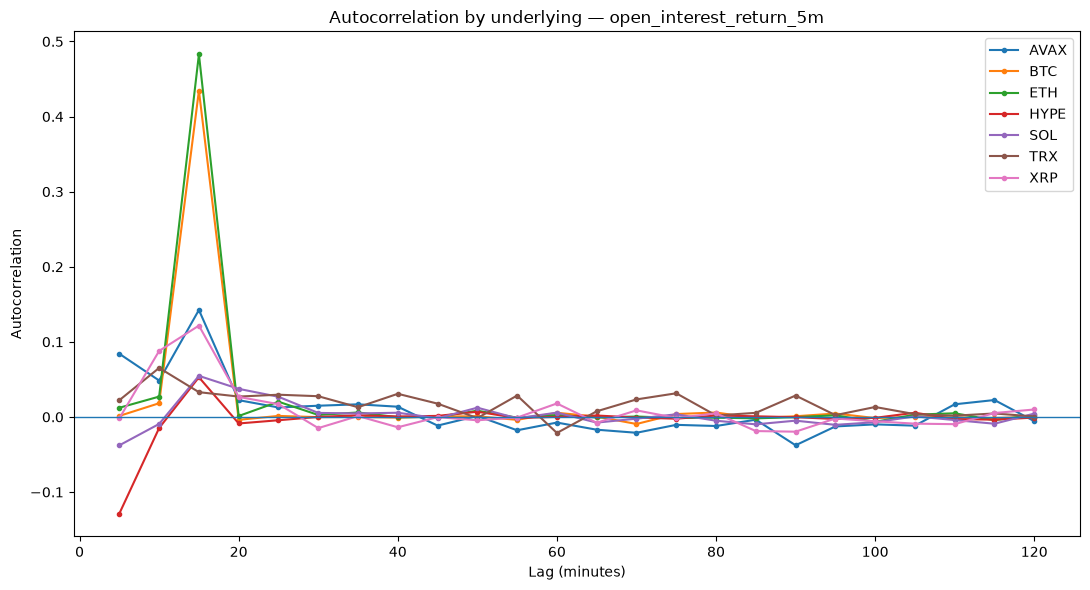

In [16]:
for col in [
    c for c in [
        "intrabar_range_bps",
        "close_vs_vwap_bps",
        "open_interest_return_5m",
    ]
    if c in features.columns
]:
    plot_acf_by_asset(features, col, max_lag=24)

# Part E — Basis, Spread, and Microprice

## 16. Distribution diagnostics

Notebook 01 exposed unusually large maxima in several spread/basis features relative to their ordinary quantiles. Here the goal is to determine whether these are concentrated in one asset, concentrated near particular session times, associated with high volatility / volume, associated with wider L2 spreads, or isolated observations versus repeated episodes.

No observation is deleted in this notebook.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,futures_spread_bps,23940,15.178571,2.716484,21.228951,53.524993,4517.717488,0.011464,0.011517,0.011584,0.011832,1.267668,5.987316,8.090017,328.927522,2139.637859
1,ALL,perpetual_mid_vs_index_bps,23940,15.178571,2.960438,9.257668,62.189352,6119.047891,-87.965324,-30.438449,-6.192289,-1.926174,2.752546,7.643632,10.761341,52.179879,1012.713340
2,ALL,perpetual_mark_vs_index_bps,23940,15.178571,2.851546,4.615314,22.803828,1211.436634,-91.281294,-10.932012,-5.495598,-1.194324,2.712247,7.178619,9.643697,14.202055,249.983155
3,ALL,microprice_vs_mid_bps,22064,21.825397,0.051811,4.899891,-9.933355,1107.615244,-265.592681,-31.196512,-2.665320,-1.360039,0.000930,1.877302,3.115687,20.488716,235.272364
4,ALL,book_twa_spread_bps,22064,21.825397,2.670835,16.712960,27.350862,884.175389,0.011569,0.011811,0.011890,0.013953,1.427671,5.286687,6.745908,328.927522,811.677494
5,ALL,book_twa_microprice_vs_reference_bps,22064,21.825397,0.225018,11.717765,-0.751730,28.925676,-188.698792,-87.318599,-31.083019,-15.791231,0.247622,16.429272,33.217031,63.583946,166.738352


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,futures_spread_bps,3420,15.178571,3.889038,12.861093,25.381070,855.106769,0.873324,0.887883,0.905163,0.981851,2.797594e+00,5.743029,7.737705,127.916404,520.985361
1,AVAX,perpetual_mid_vs_index_bps,3420,15.178571,2.301967,6.325231,19.100214,638.995813,-39.479587,-13.681348,-8.164018,-4.363362,2.277801e+00,7.618721,11.591670,60.084693,236.780152
2,AVAX,perpetual_mark_vs_index_bps,3420,15.178571,2.307024,5.364688,28.886806,1328.981946,-9.782125,-9.276546,-7.888437,-3.563269,1.987084e+00,7.231214,9.739615,16.816884,249.909453
3,AVAX,microprice_vs_mid_bps,3152,21.825397,0.299313,3.782864,12.894428,194.045711,-26.679118,-5.534879,-2.736045,-1.848345,1.161356e-01,2.016271,2.931048,57.233829,57.233829
4,AVAX,book_twa_spread_bps,3152,21.825397,3.764995,8.406275,15.383005,252.526890,1.152830,1.371320,1.654947,1.980616,3.066653e+00,4.718939,7.194492,127.916404,196.056469
5,AVAX,book_twa_microprice_vs_reference_bps,3152,21.825397,0.560091,17.715529,0.262472,8.548750,-132.481234,-112.304231,-44.146163,-24.962794,8.464708e-01,27.139494,55.736904,109.766115,160.264819
6,BTC,futures_spread_bps,3420,15.178571,0.232009,3.131877,16.708166,280.393756,0.011464,0.011477,0.011527,0.011567,1.187660e-02,0.227110,0.890565,53.876085,53.876085
7,BTC,perpetual_mid_vs_index_bps,3420,15.178571,2.609380,2.056445,-9.893160,161.661940,-38.192990,-29.017417,-0.625366,0.620797,2.686036e+00,4.708137,5.812231,7.485429,7.769031
8,BTC,perpetual_mark_vs_index_bps,3420,15.178571,2.705211,1.162032,-0.119010,20.318878,-11.455631,-3.502977,0.076420,0.814564,2.749952e+00,4.348199,5.009673,7.090294,16.958739
9,BTC,microprice_vs_mid_bps,3152,21.825397,0.066696,1.151387,15.833696,259.216084,-4.132181,-2.858026,-0.216175,-0.005799,-9.775327e-05,0.005865,0.542060,19.109893,19.109893


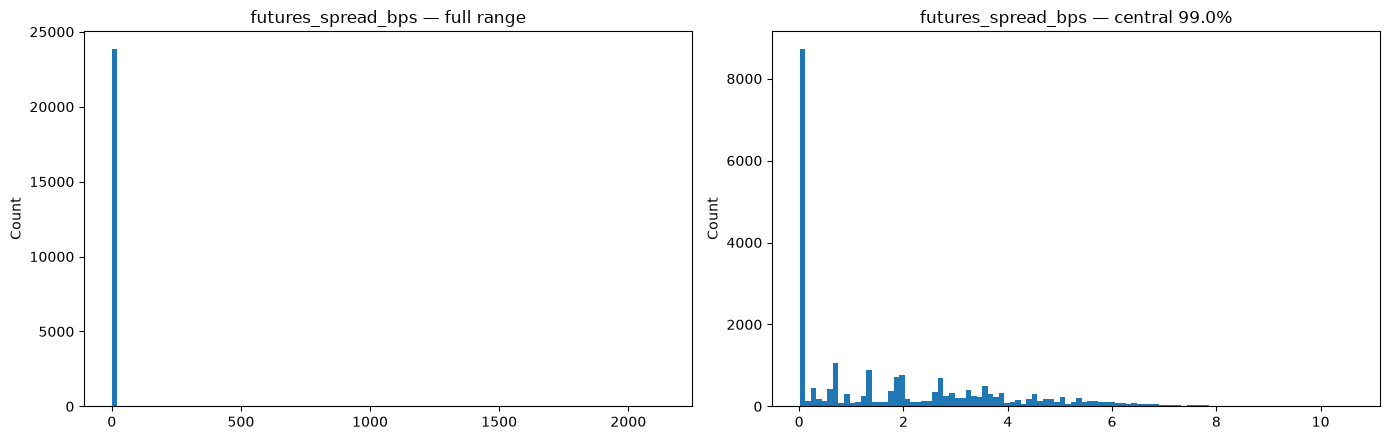

n=23,940 | central bounds [0.0115577, 10.6526] | min=0.0114645 | max=2139.64


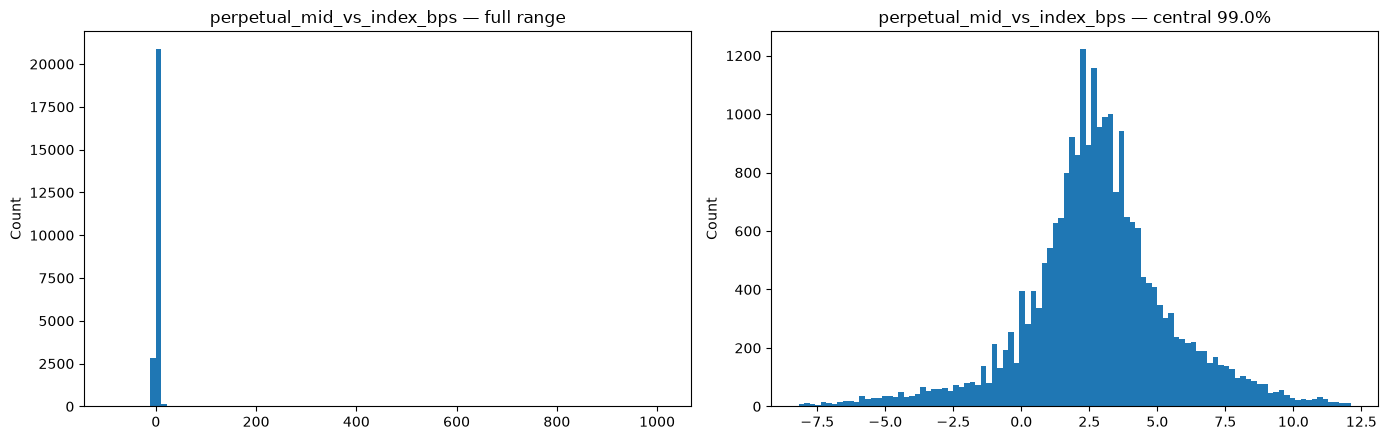

n=23,940 | central bounds [-8.17822, 12.1109] | min=-87.9653 | max=1012.71


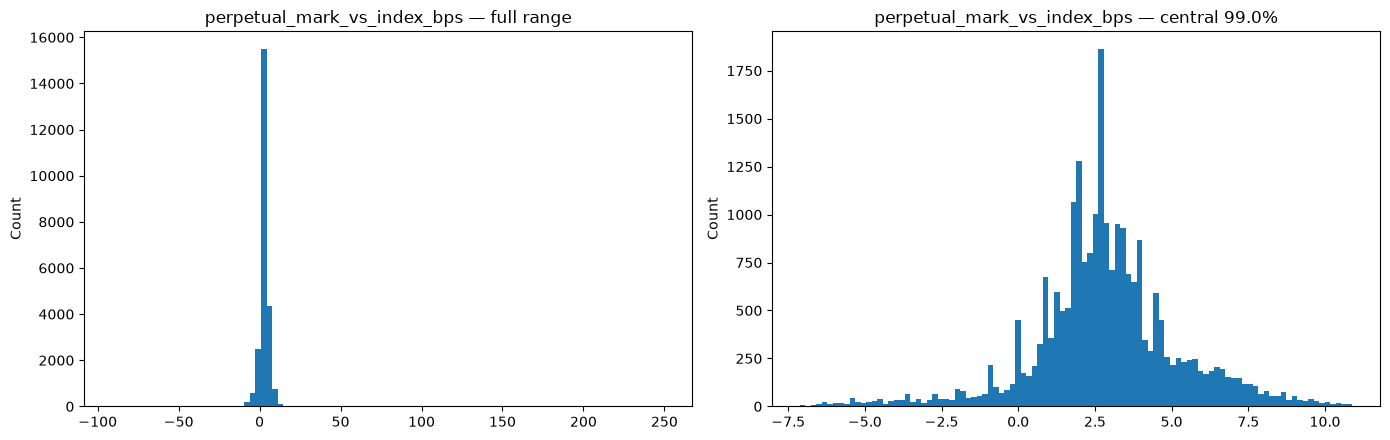

n=23,940 | central bounds [-7.12536, 10.8926] | min=-91.2813 | max=249.983


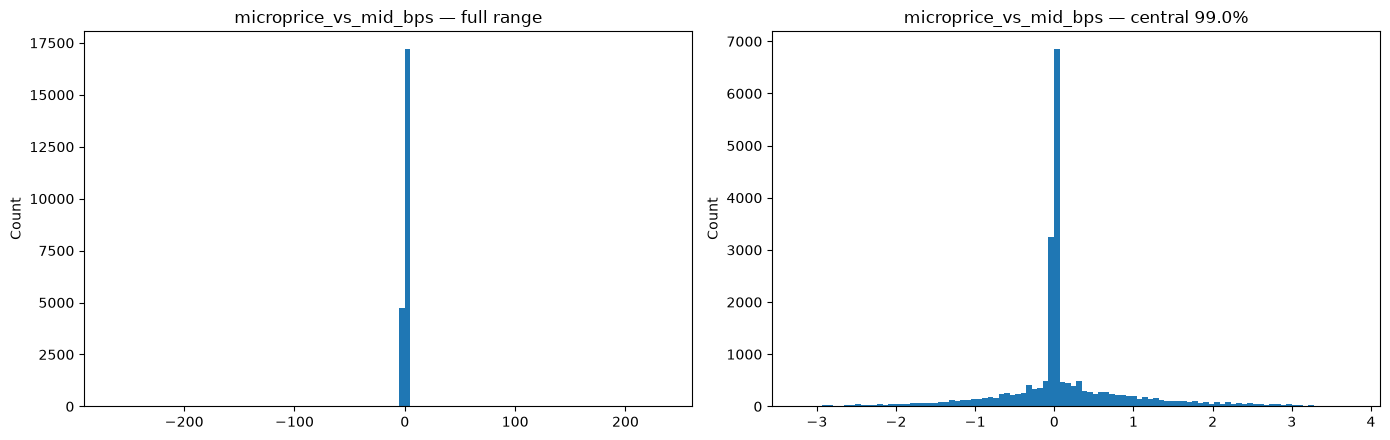

n=22,064 | central bounds [-3.21665, 3.78766] | min=-265.593 | max=235.272


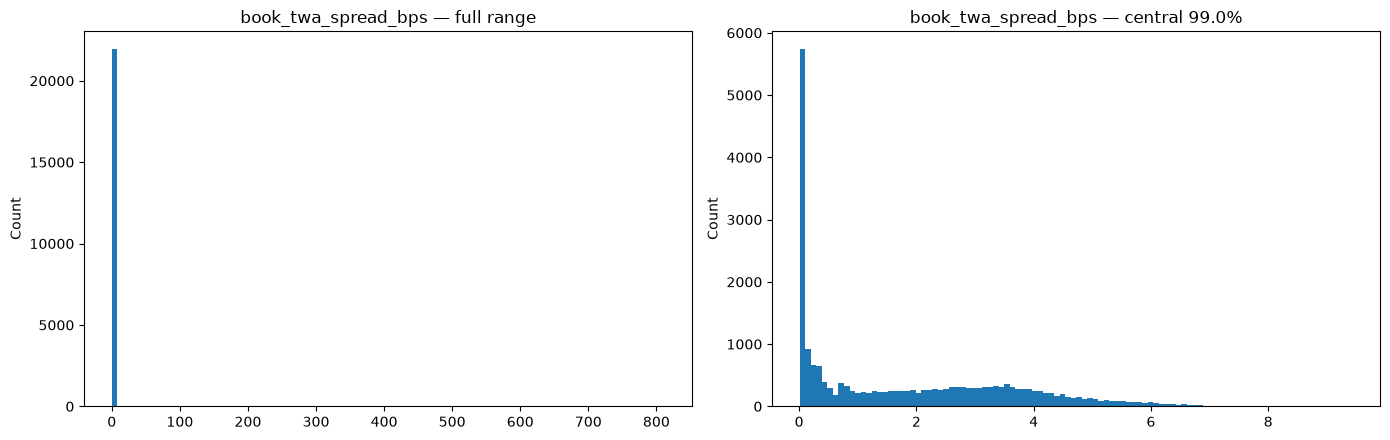

n=22,064 | central bounds [0.0118264, 9.58079] | min=0.0115694 | max=811.677


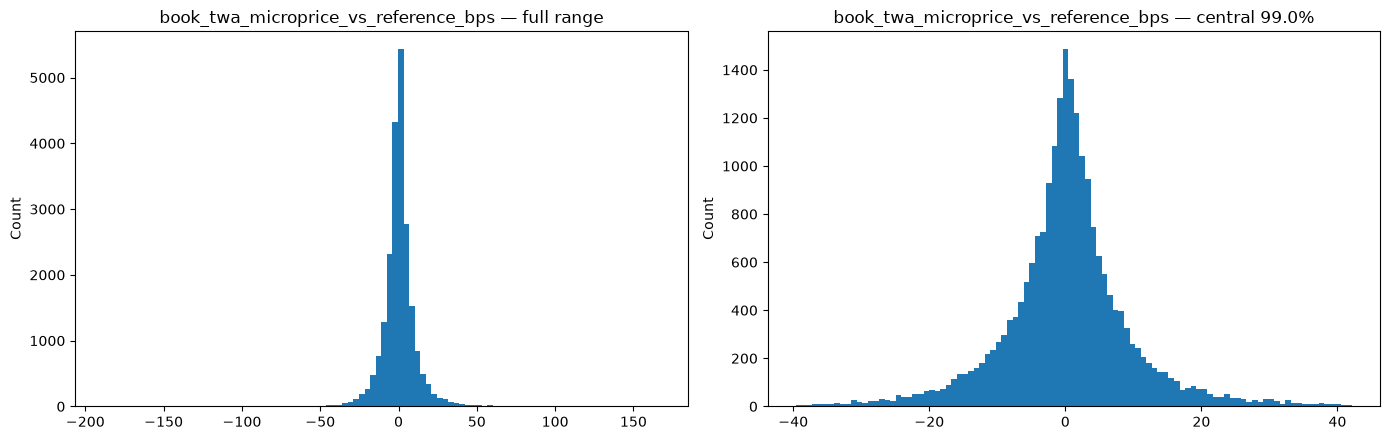

n=22,064 | central bounds [-39.6981, 42.2632] | min=-188.699 | max=166.738


In [17]:
basis_cols = available_groups["basis_spread_microprice"]

display(feature_summary(features, basis_cols))
display(feature_summary(features, basis_cols, group_col="underlying"))

for col in basis_cols:
    plot_full_and_central(features, col)

## 17. Contextual tail inspection

The following tables identify the actual observations behind the tails. This is more informative than simply reporting skewness or kurtosis.

For signed basis/microprice features, both tails are shown. For non-negative spread features, the largest observations are emphasized.

In [18]:
extreme_features = [
    c for c in [
        "futures_spread_bps",
        "perpetual_mid_vs_index_bps",
        "perpetual_mark_vs_index_bps",
        "microprice_vs_mid_bps",
        "book_twa_spread_bps",
        "book_twa_microprice_vs_reference_bps",
    ]
    if c in features.columns
]

for col in extreme_features:
    print("\n" + "=" * 110)
    print(col)
    print("=" * 110)

    if col in {"futures_spread_bps", "book_twa_spread_bps"}:
        display(contextual_extremes(features, col, n=20, absolute=True))
    else:
        display(contextual_extremes(features, col, n=12, absolute=False))


futures_spread_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,futures_spread_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,perpetual_mid_vs_index_bps,book_twa_obi_20,book_twa_spread_bps
0,AVAX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,AVAX,2026-09-22,890,520.985361,0.026031,2.663451,3.480952e+04,0.313985,236.780152,NaN,NaN
1,HYPE|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,HYPE,2026-09-22,890,337.975228,0.011201,1.205931,0.000000e+00,NaN,108.568485,NaN,NaN
2,TRX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,TRX,2026-09-22,890,2139.637859,0.096277,9.012534,0.000000e+00,NaN,1012.713340,NaN,NaN
3,XRP|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,XRP,2026-09-22,890,485.956891,0.027682,2.687570,4.653610e+04,0.957072,222.340923,NaN,NaN
4,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,620.346856,NaN,NaN,0.000000e+00,NaN,321.489381,0.204037,708.054410
5,HYPE|2026-09-28T09:25:00Z,2026-09-28 09:25:00+00:00,HYPE,2026-09-29,1355,523.813942,NaN,NaN,0.000000e+00,NaN,273.211482,0.387108,617.582037
6,HYPE|2026-09-28T09:30:00Z,2026-09-28 09:30:00+00:00,HYPE,2026-09-29,1350,529.528010,-0.000278,NaN,0.000000e+00,NaN,275.537107,0.492602,534.586933
7,HYPE|2026-10-01T09:05:00Z,2026-10-01 09:05:00+00:00,HYPE,2026-10-02,1375,328.927522,0.005630,0.794224,1.172419e+06,-0.999992,46.470384,0.015688,130.314291
8,XRP|2026-10-01T09:05:00Z,2026-10-01 09:05:00+00:00,XRP,2026-10-02,1375,419.589632,0.020564,2.001461,1.498562e+06,0.140236,199.193819,0.109679,32.168631
9,XRP|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,XRP,2026-10-02,1370,442.480794,-0.001120,1.988718,5.102831e+04,1.000000,172.737640,0.226147,438.627035



perpetual_mid_vs_index_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,perpetual_mid_vs_index_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,book_twa_obi_20,book_twa_spread_bps,tail
0,AVAX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,AVAX,2026-09-22,890,236.780152,0.026031,2.663451,3.480952e+04,0.313985,520.985361,NaN,NaN,high
1,TRX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,TRX,2026-09-22,890,1012.713340,0.096277,9.012534,0.000000e+00,NaN,2139.637859,NaN,NaN,high
2,XRP|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,XRP,2026-09-22,890,222.340923,0.027682,2.687570,4.653610e+04,0.957072,485.956891,NaN,NaN,high
3,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,321.489381,NaN,NaN,0.000000e+00,NaN,620.346856,0.204037,708.054410,high
4,HYPE|2026-09-28T09:25:00Z,2026-09-28 09:25:00+00:00,HYPE,2026-09-29,1355,273.211482,NaN,NaN,0.000000e+00,NaN,523.813942,0.387108,617.582037,high
5,HYPE|2026-09-28T09:30:00Z,2026-09-28 09:30:00+00:00,HYPE,2026-09-29,1350,275.537107,-0.000278,NaN,0.000000e+00,NaN,529.528010,0.492602,534.586933,high
6,TRX|2026-10-01T09:05:00Z,2026-10-01 09:05:00+00:00,TRX,2026-10-02,1375,-87.965324,-0.008666,0.824499,1.583659e+04,1.000000,173.782996,-0.109359,49.709454,low
7,XRP|2026-10-01T09:05:00Z,2026-10-01 09:05:00+00:00,XRP,2026-10-02,1375,199.193819,0.020564,2.001461,1.498562e+06,0.140236,419.589632,0.109679,32.168631,high
8,TRX|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,TRX,2026-10-02,1370,-74.104643,0.000000,0.823711,0.000000e+00,NaN,173.782996,-0.297709,173.782996,low
9,XRP|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,XRP,2026-10-02,1370,172.737640,-0.001120,1.988718,5.102831e+04,1.000000,442.480794,0.226147,438.627035,high



perpetual_mark_vs_index_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,perpetual_mark_vs_index_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,perpetual_mid_vs_index_bps,book_twa_obi_20,book_twa_spread_bps,tail
0,AVAX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,AVAX,2026-09-22,890,249.909453,0.026031,2.663451,3.480952e+04,0.313985,520.985361,236.780152,NaN,NaN,high
1,ETH|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,ETH,2026-09-22,890,25.943302,0.001521,0.756441,6.035410e+03,0.391516,48.961828,4.499258,NaN,NaN,high
2,HYPE|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,HYPE,2026-09-22,890,104.006784,0.011201,1.205931,0.000000e+00,NaN,337.975228,108.568485,NaN,NaN,high
3,XRP|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,XRP,2026-09-22,890,162.248781,0.027682,2.687570,4.653610e+04,0.957072,485.956891,222.340923,NaN,NaN,high
4,AVAX|2026-09-23T02:45:00Z,2026-09-23 02:45:00+00:00,AVAX,2026-09-23,315,18.679950,0.004097,1.124737,6.443086e+04,0.748050,8.888889,7.116171,0.413931,11.455239,high
5,AVAX|2026-09-23T14:15:00Z,2026-09-23 14:15:00+00:00,AVAX,2026-09-24,1065,49.665712,-0.001458,NaN,5.705784e+05,-0.322056,274.875271,146.131805,0.654582,66.176412,high
6,AVAX|2026-09-25T08:00:00Z,2026-09-25 08:00:00+00:00,AVAX,2026-09-26,1440,17.621145,0.002006,1.167998,5.230248e+05,0.245428,10.753214,14.194812,0.586702,9.435160,high
7,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,199.950712,NaN,NaN,0.000000e+00,NaN,620.346856,321.489381,0.204037,708.054410,high
8,XRP|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,XRP,2026-09-29,1360,249.983155,NaN,NaN,2.853122e+03,0.931288,24.843052,35.374975,0.252832,811.677494,high
9,HYPE|2026-09-28T09:25:00Z,2026-09-28 09:25:00+00:00,HYPE,2026-09-29,1355,200.044853,NaN,NaN,0.000000e+00,NaN,523.813942,273.211482,0.387108,617.582037,high


... (2 outputs left out)


book_twa_spread_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,book_twa_spread_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,perpetual_mid_vs_index_bps,book_twa_obi_20
0,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,708.054410,NaN,NaN,0.000000e+00,NaN,620.346856,321.489381,0.204037
1,XRP|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,XRP,2026-09-29,1360,811.677494,NaN,NaN,2.853122e+03,0.931288,24.843052,35.374975,0.252832
2,HYPE|2026-09-28T09:25:00Z,2026-09-28 09:25:00+00:00,HYPE,2026-09-29,1355,617.582037,NaN,NaN,0.000000e+00,NaN,523.813942,273.211482,0.387108
3,HYPE|2026-09-28T09:30:00Z,2026-09-28 09:30:00+00:00,HYPE,2026-09-29,1350,534.586933,-0.000278,NaN,0.000000e+00,NaN,529.528010,275.537107,0.492602
4,HYPE|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,HYPE,2026-10-02,1370,328.927522,0.000000,0.777328,3.458520e+01,1.000000,328.927522,20.151585,-0.116879
5,XRP|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,XRP,2026-10-02,1370,438.627035,-0.001120,1.988718,5.102831e+04,1.000000,442.480794,172.737640,0.226147
6,HYPE|2026-10-01T09:15:00Z,2026-10-01 09:15:00+00:00,HYPE,2026-10-02,1365,328.927522,0.000000,0.746217,0.000000e+00,NaN,328.927522,12.193212,-0.116879
7,XRP|2026-10-01T09:15:00Z,2026-10-01 09:15:00+00:00,XRP,2026-10-02,1365,442.480794,0.000000,1.987908,0.000000e+00,NaN,442.480794,174.102650,0.215123
8,HYPE|2026-10-01T09:20:00Z,2026-10-01 09:20:00+00:00,HYPE,2026-10-02,1360,328.927522,0.000000,0.714551,5.409152e+06,0.383049,328.927522,42.637703,-0.116879
9,XRP|2026-10-01T09:20:00Z,2026-10-01 09:20:00+00:00,XRP,2026-10-02,1360,442.480794,0.000000,1.987898,1.529385e+06,0.700511,442.480794,184.351914,0.215123



book_twa_microprice_vs_reference_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,book_twa_microprice_vs_reference_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,perpetual_mid_vs_index_bps,book_twa_obi_20,book_twa_spread_bps,tail
0,AVAX|2026-09-23T12:05:00Z,2026-09-23 12:05:00+00:00,AVAX,2026-09-24,1195,112.425616,-0.022974,2.404836,5.771174e+05,-0.050456,5.522319,4.604052,0.453480,11.740181,high
1,XRP|2026-09-23T14:20:00Z,2026-09-23 14:20:00+00:00,XRP,2026-09-24,1060,99.812329,-0.016668,NaN,5.666636e+05,0.115584,3.302183,0.990753,0.051252,5.845055,high
2,AVAX|2026-09-23T16:00:00Z,2026-09-23 16:00:00+00:00,AVAX,2026-09-24,960,86.479851,-0.009046,1.123777,1.527662e+05,0.303910,5.862810,0.977231,0.268562,4.888375,high
3,AVAX|2026-09-24T14:50:00Z,2026-09-24 14:50:00+00:00,AVAX,2026-09-25,1030,84.442158,-0.012415,1.975086,6.401229e+04,0.119614,4.879715,-1.463700,0.227778,3.046705,high
4,XRP|2026-09-24T14:50:00Z,2026-09-24 14:50:00+00:00,XRP,2026-09-25,1030,97.071346,-0.014021,1.671238,2.685651e+05,-0.194641,4.005608,3.339121,0.083320,3.828006,high
5,AVAX|2026-09-25T14:05:00Z,2026-09-25 14:05:00+00:00,AVAX,2026-09-26,1075,102.059374,-0.018177,2.135685,1.203945e+05,-0.464963,7.826257,10.772696,0.005515,5.716745,high
6,AVAX|2026-09-27T07:25:00Z,2026-09-27 07:25:00+00:00,AVAX,2026-09-27,35,-132.481234,0.019265,1.875386,2.071317e+05,-0.041100,2.681085,1.340722,0.055873,4.565125,low
7,AVAX|2026-09-27T09:10:00Z,2026-09-27 09:10:00+00:00,AVAX,2026-09-28,1370,124.229417,-0.016027,1.996169,8.531265e+04,0.521580,4.525501,4.980531,0.216191,3.803479,high
8,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,-181.059897,NaN,NaN,0.000000e+00,NaN,620.346856,321.489381,0.204037,708.054410,low
9,TRX|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,TRX,2026-09-29,1360,107.231512,NaN,NaN,1.509994e+04,1.000000,62.115511,23.257693,0.686921,253.063184,high


# Part F — Standard L2 State

## 18. Persistent order-book state

This section covers the established L2 level features with sufficient history:

- time-weighted OBI at 5/10/20 levels;
- 5-minute change in deep-book imbalance;
- time-weighted depth;
- time-weighted spread / microprice.

The newer streaming instability statistics (`book_obi_20_std`, roughness, coherence noise, reversal-strength distributions, etc.) are deferred to **Notebook 04**, where their shorter history can be handled explicitly.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,book_twa_obi_5,22071,21.800595,0.024026,0.218645,0.155495,1.575078,-0.856850,-0.746024,-0.573755,-0.331050,0.014796,0.416407,0.637608,0.831074,0.915902
1,ALL,book_twa_obi_10,22071,21.800595,0.014407,0.170799,0.165930,1.043286,-0.795102,-0.539223,-0.416701,-0.266976,0.012838,0.312985,0.477485,0.646548,0.749387
2,ALL,book_twa_obi_20,22071,21.800595,-0.006982,0.158711,-0.260231,2.761221,-0.807421,-0.621508,-0.479865,-0.300645,0.004268,0.221336,0.454874,0.636187,0.714406
3,ALL,book_twa_obi_20_change_5m,22057,21.850198,-0.000094,0.071639,-0.004937,3.998593,-0.593039,-0.337524,-0.199201,-0.115212,-0.000072,0.116380,0.201253,0.325143,0.560171
4,ALL,book_twa_bid_depth_20,22071,21.800595,60157.664016,105285.932267,1.985156,3.562702,2.813166,4.943746,5.704930,6.756768,4584.367096,284863.928718,456619.936691,511867.065399,543079.692383
5,ALL,book_twa_ask_depth_20,22071,21.800595,58049.457169,99231.905071,1.848862,2.702764,1.252731,4.655043,5.534163,6.735648,4466.124532,287602.572762,408399.187803,447361.265253,552024.063997
6,ALL,book_twa_spread,22071,21.800595,0.325685,11.054044,44.020965,2006.009474,0.000010,0.000010,0.000027,0.000113,0.004926,0.215215,1.040961,11.270000,680.549612
7,ALL,book_twa_microprice,22071,21.800595,12473.024640,29378.552459,2.037912,2.162101,0.331749,0.332359,0.333587,0.334985,91.318054,84492.660062,86314.276273,86851.276700,87205.634838


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,book_twa_obi_5,3153,21.800595,0.007574,0.097264,0.905098,9.695041,-0.763327,-0.464243,-0.214922,-0.125882,0.003512,0.153396,0.289625,0.664465,0.664465
1,AVAX,book_twa_obi_10,3153,21.800595,-0.058193,0.161371,0.349873,1.695615,-0.795102,-0.528989,-0.438277,-0.325858,-0.047662,0.199043,0.457588,0.569789,0.644704
2,AVAX,book_twa_obi_20,3153,21.800595,-0.105272,0.302492,0.557091,-0.425704,-0.807421,-0.658858,-0.603715,-0.500451,-0.151517,0.475629,0.626942,0.678324,0.714406
3,AVAX,book_twa_obi_20_change_5m,3151,21.850198,-0.000330,0.093106,-0.045196,2.868705,-0.565236,-0.377061,-0.252273,-0.150939,-0.000246,0.148250,0.256697,0.406794,0.560171
4,AVAX,book_twa_bid_depth_20,3153,21.800595,7743.181312,3854.786115,2.406877,6.789216,100.511548,754.628000,3324.404854,3995.672182,6681.516435,15287.024531,23067.431993,26499.725400,28670.472733
5,AVAX,book_twa_ask_depth_20,3153,21.800595,9851.841077,3904.832756,0.291357,-0.860291,258.092525,1265.831000,3725.791967,4556.610348,9725.731639,16396.781008,18449.051147,20425.728290,21363.112371
6,AVAX,book_twa_spread,3153,21.800595,0.004125,0.009506,14.721753,227.963923,0.001275,0.001488,0.001790,0.002142,0.003291,0.005216,0.008106,0.142000,0.206016
7,AVAX,book_twa_microprice,3153,21.800595,10.813536,0.359371,-0.087362,-0.614298,10.001033,10.056583,10.110101,10.219762,10.890762,11.367306,11.642938,11.880050,11.943124
8,BTC,book_twa_obi_5,3153,21.800595,0.002763,0.177476,0.112780,1.085033,-0.677049,-0.597366,-0.449902,-0.290123,0.000633,0.313136,0.465674,0.655189,0.836630
9,BTC,book_twa_obi_10,3153,21.800595,0.004807,0.164078,0.439847,1.300828,-0.576475,-0.488942,-0.352621,-0.247139,-0.002697,0.286300,0.418366,0.749387,0.749387


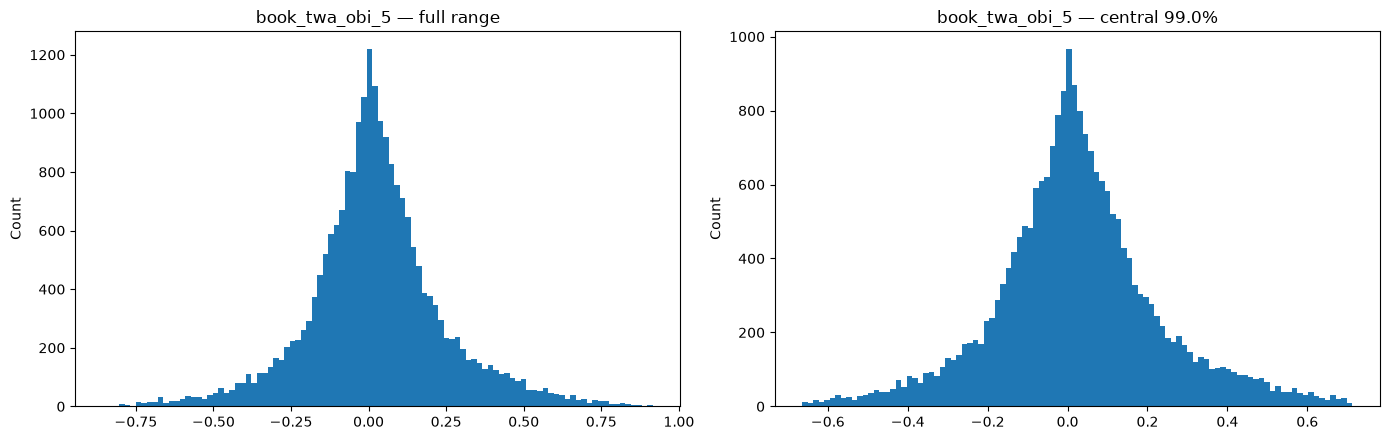

n=22,071 | central bounds [-0.664811, 0.713493] | min=-0.85685 | max=0.915902


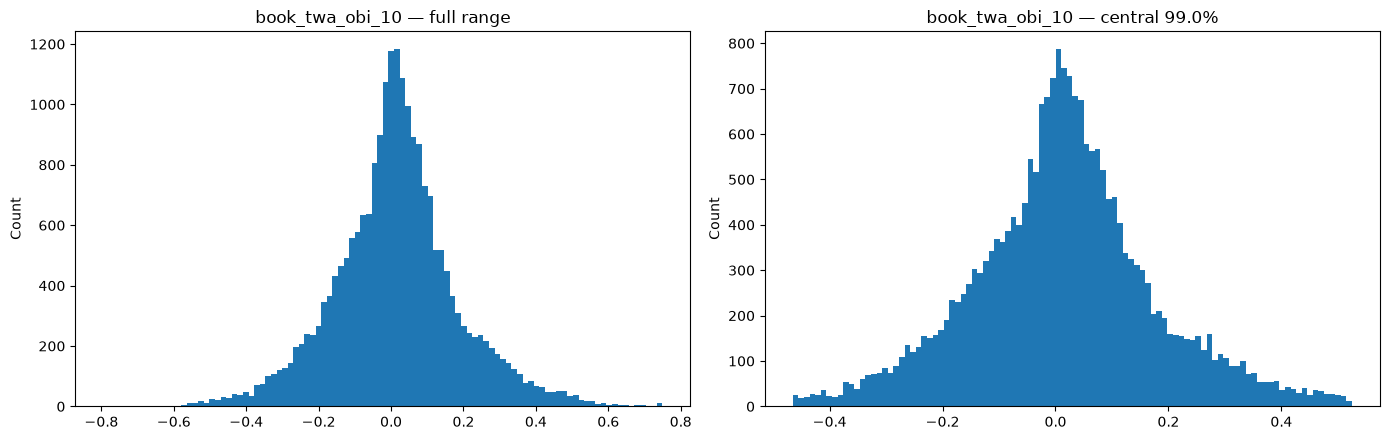

n=22,071 | central bounds [-0.465395, 0.525452] | min=-0.795102 | max=0.749387


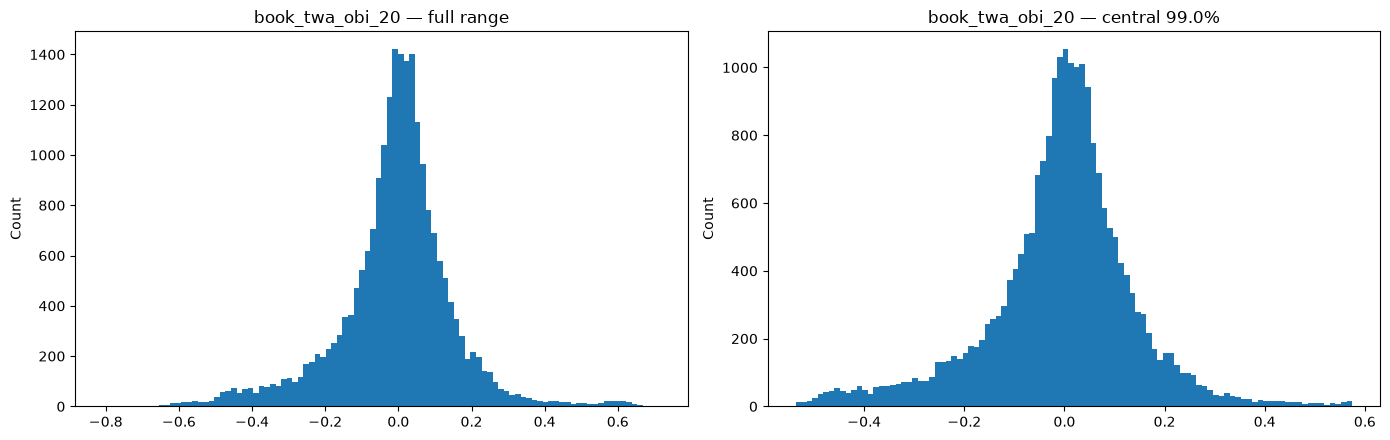

n=22,071 | central bounds [-0.537801, 0.574763] | min=-0.807421 | max=0.714406


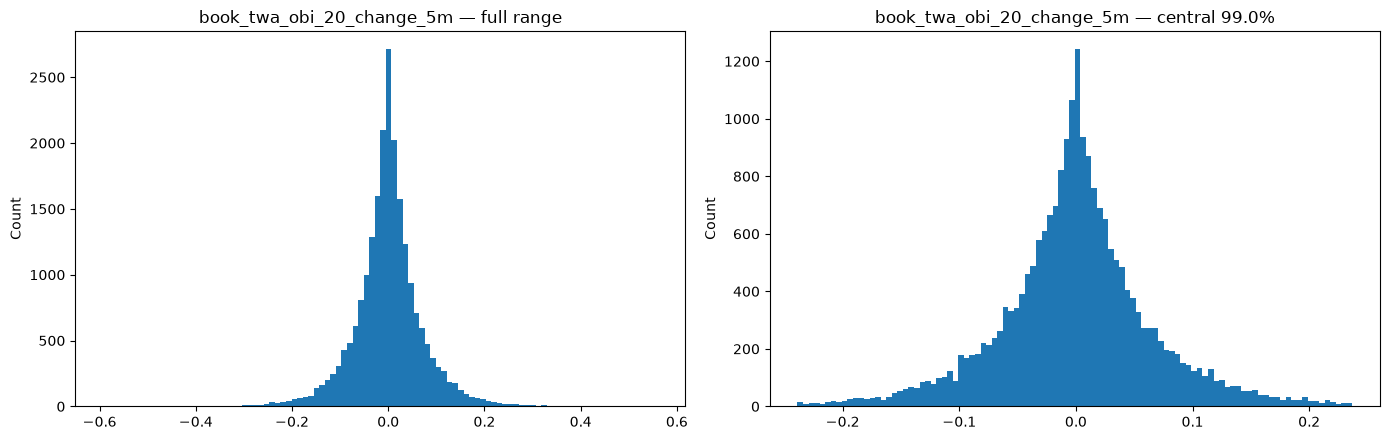

n=22,057 | central bounds [-0.239038, 0.237201] | min=-0.593039 | max=0.560171


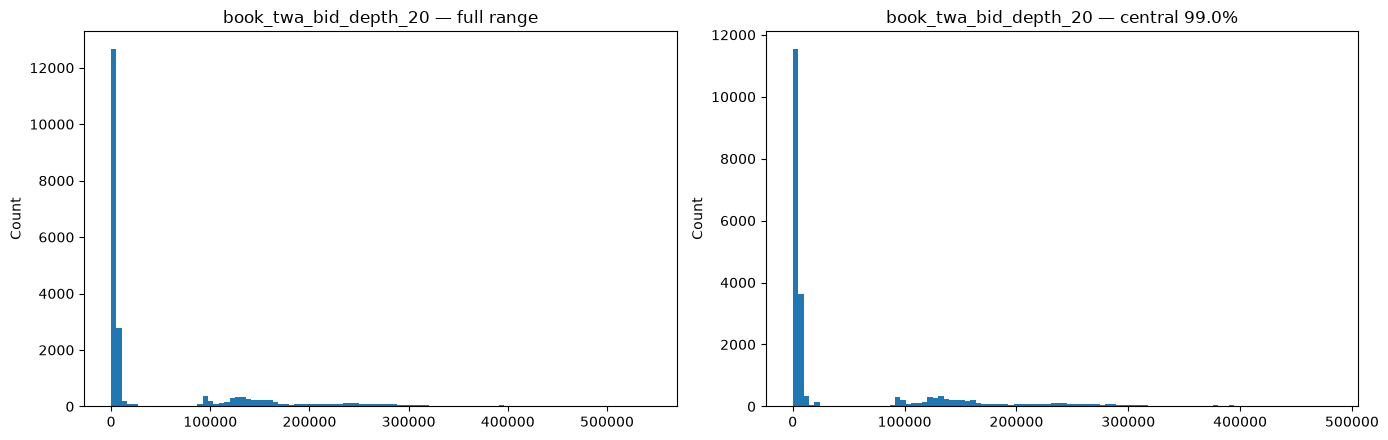

n=22,071 | central bounds [5.40824, 481632] | min=2.81317 | max=543080


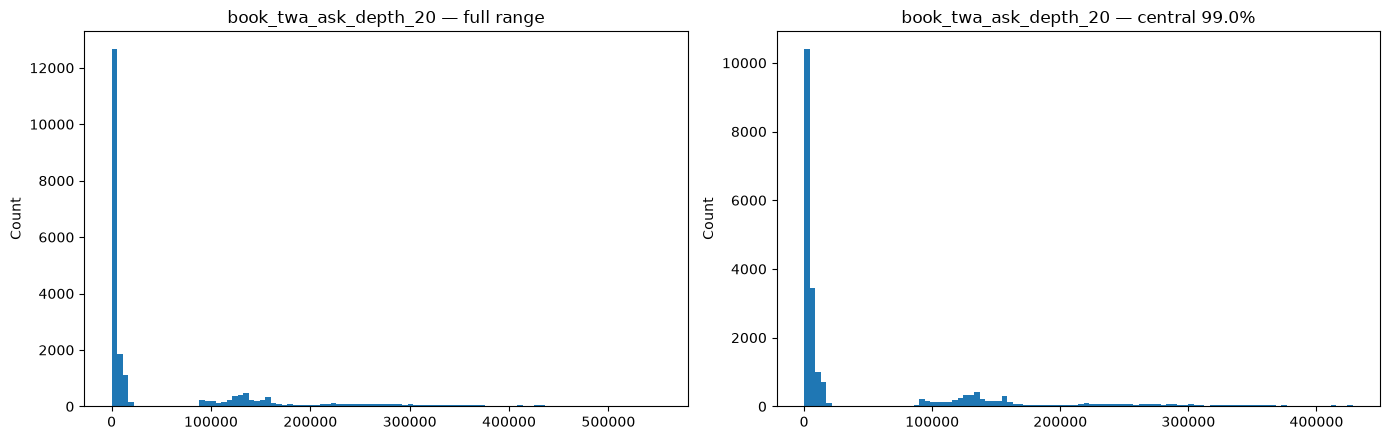

n=22,071 | central bounds [5.26969, 428249] | min=1.25273 | max=552024


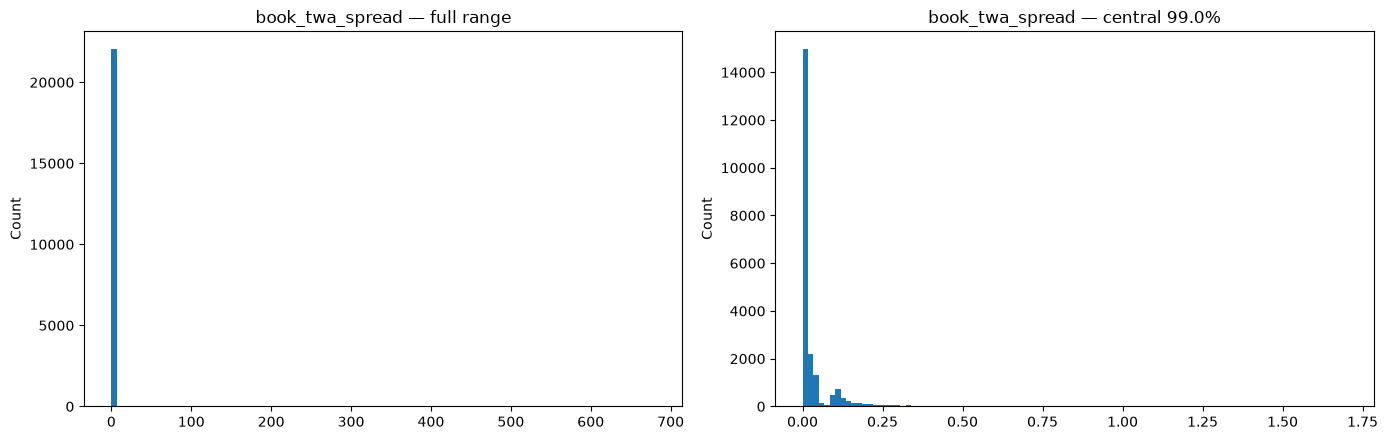

n=22,071 | central bounds [1.20217e-05, 1.69986] | min=1e-05 | max=680.55


In [19]:
l2_cols = available_groups["standard_l2"]

display(feature_summary(features, l2_cols))
display(feature_summary(features, l2_cols, group_col="underlying"))

for col in [
    c for c in [
        "book_twa_obi_5",
        "book_twa_obi_10",
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
        "book_twa_bid_depth_20",
        "book_twa_ask_depth_20",
        "book_twa_spread",
    ]
    if c in features.columns
]:
    plot_full_and_central(features, col)

## 19. Diagnostic depth imbalance

The roadmap calls for depth-ratio style features. The production feature table currently preserves bid and ask depth separately.

For research only, this notebook constructs a diagnostic bounded depth imbalance:

\[
\frac{BidDepth_{20} - AskDepth_{20}}
     {BidDepth_{20} + AskDepth_{20}}
\]

This does **not** promote the variable into the production feature contract. It only tests whether this scale-free representation may be useful later.

**Redundancy check.** `book_twa_obi_20` is the time-weighted average of the instantaneous imbalance, while this variable is the imbalance of time-weighted depths. They differ only through the covariance of depth and time weights, so they are expected to be near-duplicates. The cell reports their correlation; if it is close to 1, the diagnostic adds nothing and is not carried into the persistence study.


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,_diag_depth_imbalance_20,3153,21.800595,-0.115835,0.309785,0.565822,-0.463496,-0.719457,-0.667696,-0.626291,-0.522943,-0.169594,0.478522,0.627250,0.678268,0.731217
1,BTC,_diag_depth_imbalance_20,3153,21.800595,-0.000176,0.111472,0.634677,2.598187,-0.335235,-0.309826,-0.243150,-0.173519,-0.005490,0.187861,0.267937,0.608889,0.623822
2,ETH,_diag_depth_imbalance_20,3153,21.800595,-0.002817,0.134811,-0.039572,-0.214633,-0.441912,-0.385136,-0.320432,-0.223651,-0.005316,0.218397,0.300205,0.351696,0.394622
3,HYPE,_diag_depth_imbalance_20,3153,21.800595,0.012626,0.102943,0.314805,5.259685,-0.615671,-0.451766,-0.275667,-0.141892,0.010394,0.193724,0.304709,0.476852,0.903421
4,SOL,_diag_depth_imbalance_20,3153,21.800595,0.015427,0.060060,0.646344,4.446708,-0.283936,-0.234497,-0.141842,-0.064767,0.009665,0.118326,0.208895,0.264593,0.459208
5,TRX,_diag_depth_imbalance_20,3153,21.800595,0.015079,0.142017,0.355205,1.249507,-0.564122,-0.338865,-0.271907,-0.227777,0.022422,0.239463,0.469724,0.529147,0.683418
6,XRP,_diag_depth_imbalance_20,3153,21.800595,0.016379,0.107017,-0.049861,0.707556,-0.424354,-0.356843,-0.243636,-0.163563,0.028375,0.178522,0.280460,0.415690,0.523673


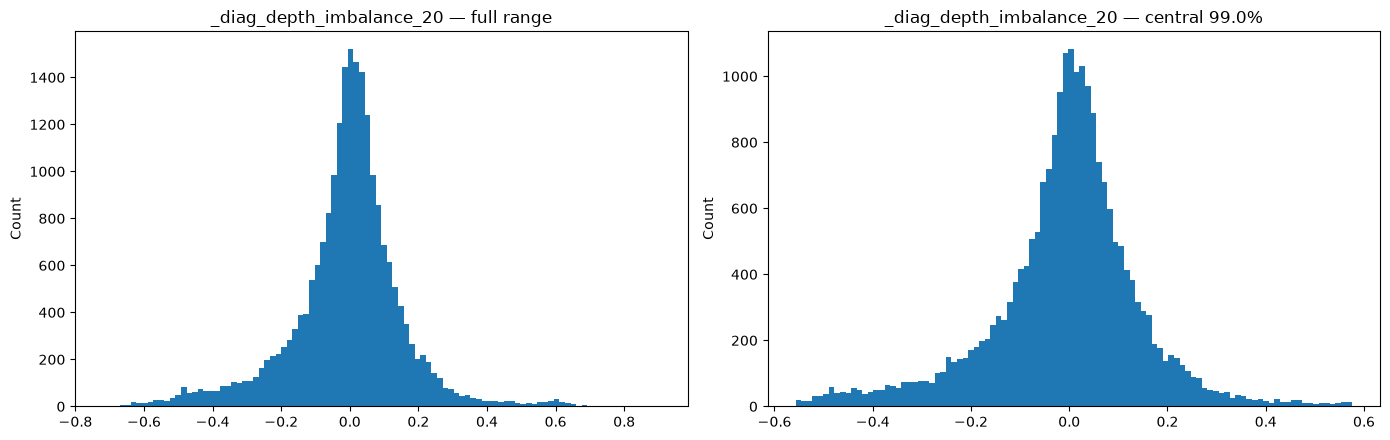

n=22,071 | central bounds [-0.557241, 0.576274] | min=-0.719457 | max=0.903421


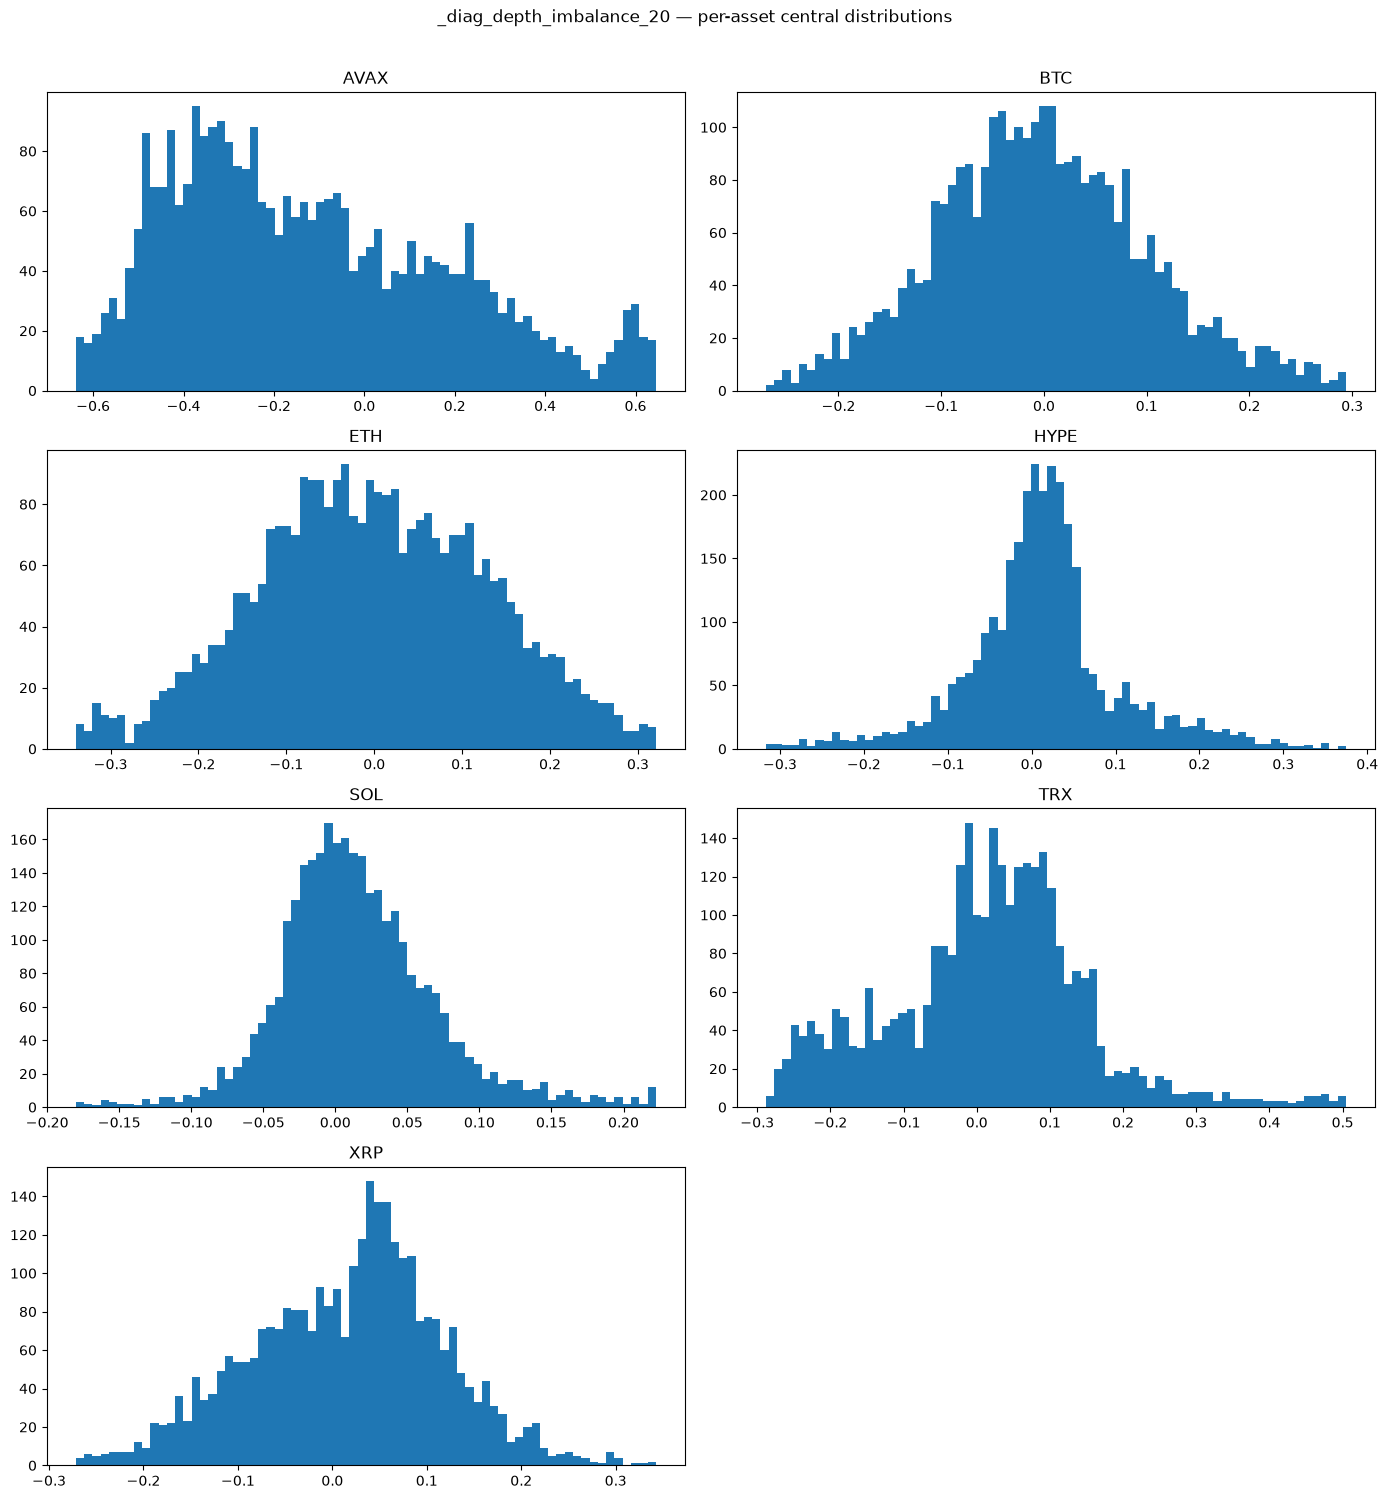

Correlation with book_twa_obi_20 by underlying:


,corr
underlying,
AVAX,0.9983
BTC,0.9979
ETH,0.9985
HYPE,0.9898
SOL,0.9932
TRX,0.9984
XRP,0.9965


Max |difference|: 0.6494


In [20]:
if {
    "book_twa_bid_depth_20",
    "book_twa_ask_depth_20",
}.issubset(features.columns):

    denom = (
        pd.to_numeric(features["book_twa_bid_depth_20"], errors="coerce")
        + pd.to_numeric(features["book_twa_ask_depth_20"], errors="coerce")
    )

    features["_diag_depth_imbalance_20"] = np.where(
        denom > 0,
        (
            pd.to_numeric(features["book_twa_bid_depth_20"], errors="coerce")
            - pd.to_numeric(features["book_twa_ask_depth_20"], errors="coerce")
        ) / denom,
        np.nan,
    )

    display(
        feature_summary(
            features,
            ["_diag_depth_imbalance_20"],
            group_col="underlying"
        )
    )

    plot_full_and_central(features, "_diag_depth_imbalance_20")
    plot_asset_histograms(features, "_diag_depth_imbalance_20")

    if "book_twa_obi_20" in features.columns:
        pair = pd.concat(
            [
                pd.to_numeric(features["book_twa_obi_20"], errors="coerce"),
                features["_diag_depth_imbalance_20"],
            ],
            axis=1,
        ).dropna()
        print("Correlation with book_twa_obi_20 by underlying:")
        display(
            features.loc[pair.index]
            .groupby("underlying")
            .apply(lambda g: g["book_twa_obi_20"].astype(float).corr(g["_diag_depth_imbalance_20"]))
            .to_frame("corr")
            .round(4)
        )
        print(f"Max |difference|: {(pair.iloc[:, 0] - pair.iloc[:, 1]).abs().max():.4f}")


## 20. L2 persistence

Deep-book imbalance is particularly relevant to the structural-regime hypothesis because a persistent directional liquidity imbalance may support momentum, while unstable or rapidly reversing imbalance may belong to the later noise/transition block.

Here we study only the persistent level and its five-minute change.

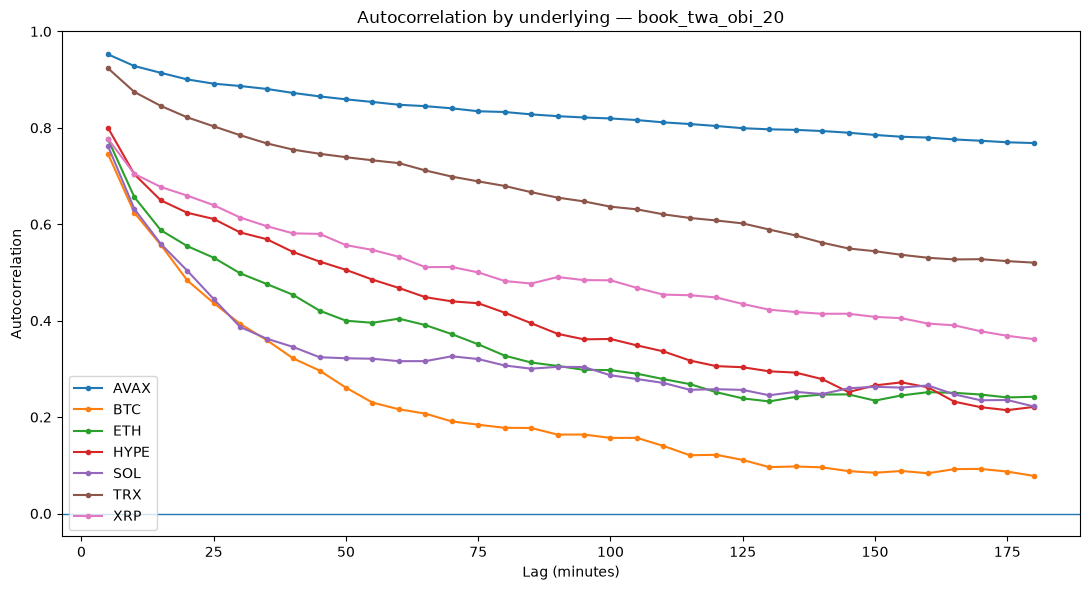

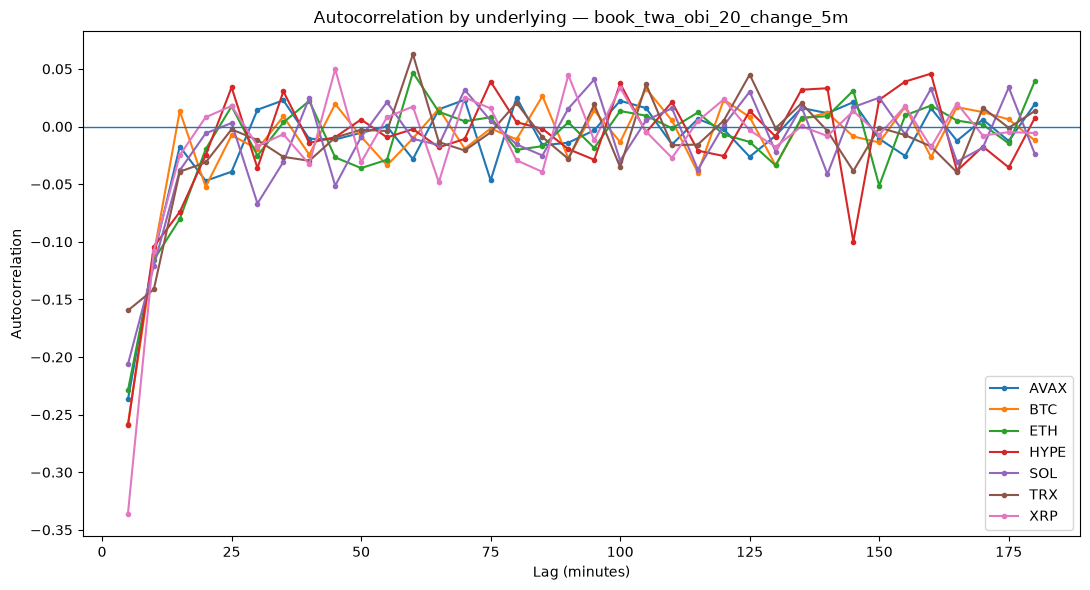

In [21]:
for col in [
    c for c in [
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
    ]
    if c in features.columns
]:
    plot_acf_by_asset(features, col, max_lag=36)

# Part G — Cross-Asset Scale and Session Variation

## 21. Cross-asset scale comparison

We intentionally do **not** standardize here. The purpose is to expose where asset scale differs enough that a later model may need asset-conditioned centering/scaling, robust scale estimates, relative/bounded representations, or separate treatment by feature family.

The table reports medians, IQRs, and 99th-percentile absolute magnitudes for a compact set of representative features.

In [22]:
scale_features = [
    c for c in [
        "return_5m",
        "realized_vol_1h_annualized",
        "log1p_volume_usd",
        "trade_flow_imbalance",
        "intrabar_range_bps",
        "open_interest_return_5m",
        "futures_spread_bps",
        "perpetual_mid_vs_index_bps",
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
    ]
    if c in features.columns
]

scale_rows = []

for asset, group in features.groupby("underlying"):
    for col in scale_features:
        s = clean_numeric(group, col)
        if s.empty:
            continue

        q25, q50, q75 = s.quantile([0.25, 0.50, 0.75])

        scale_rows.append({
            "underlying": asset,
            "feature": col,
            "n": len(s),
            "median": q50,
            "iqr": q75 - q25,
            "std": s.std(),
            "q99_abs": s.abs().quantile(0.99),
            "max_abs": s.abs().max(),
        })

cross_asset_scale = pd.DataFrame(scale_rows)
display(cross_asset_scale.sort_values(["feature", "underlying"]))

,underlying,feature,n,median,iqr,std,q99_abs,max_abs
8,AVAX,book_twa_obi_20,3153,-1.515172e-01,0.455899,0.302492,0.639289,0.807421
18,BTC,book_twa_obi_20,3153,-5.037097e-03,0.135908,0.108990,0.285713,0.624339
28,ETH,book_twa_obi_20,3153,-4.435076e-03,0.183615,0.133268,0.332243,0.432255
38,HYPE,book_twa_obi_20,3153,1.035710e-02,0.078804,0.099588,0.335249,0.614184
48,SOL,book_twa_obi_20,3153,1.022761e-02,0.066113,0.061938,0.220132,0.537040
58,TRX,book_twa_obi_20,3153,2.121339e-02,0.152823,0.139469,0.457339,0.686921
68,XRP,book_twa_obi_20,3153,2.902606e-02,0.129159,0.101916,0.283515,0.558719
9,AVAX,book_twa_obi_20_change_5m,3151,-2.461437e-04,0.092124,0.093106,0.298921,0.565236
19,BTC,book_twa_obi_20_change_5m,3151,4.038395e-04,0.096790,0.077645,0.219017,0.507986
29,ETH,book_twa_obi_20_change_5m,3151,0.000000e+00,0.105398,0.089042,0.256511,0.390359


## 22. Distribution drift across expiry sessions

A regime model will eventually be trained chronologically. Before that, we need to know whether feature distributions themselves move materially from session to session.

With the current short history this is only a diagnostic, not a stationarity conclusion.

,expiry_date,underlying,feature,n,median,q90,q95,q99
0,2026-09-22,AVAX,return_5m,252,0.000068,0.003907,0.004877,0.007295
1,2026-09-22,AVAX,realized_vol_1h_annualized,231,0.995970,1.725125,2.952162,3.967752
2,2026-09-22,AVAX,log1p_volume_usd,257,9.483802,10.877402,11.152397,11.657869
3,2026-09-22,AVAX,futures_spread_bps,257,2.686848,4.498801,5.241285,6.618708
4,2026-09-22,BTC,return_5m,252,0.000070,0.001543,0.002401,0.003570
5,2026-09-22,BTC,realized_vol_1h_annualized,231,0.369939,0.630042,0.693000,0.710566
6,2026-09-22,BTC,log1p_volume_usd,257,12.802016,14.159702,14.454501,14.970006
7,2026-09-22,BTC,futures_spread_bps,257,0.011696,0.537244,0.759239,1.109295
8,2026-09-22,ETH,return_5m,252,0.000077,0.002144,0.003228,0.004080
9,2026-09-22,ETH,realized_vol_1h_annualized,231,0.523032,0.828335,0.990067,1.044037


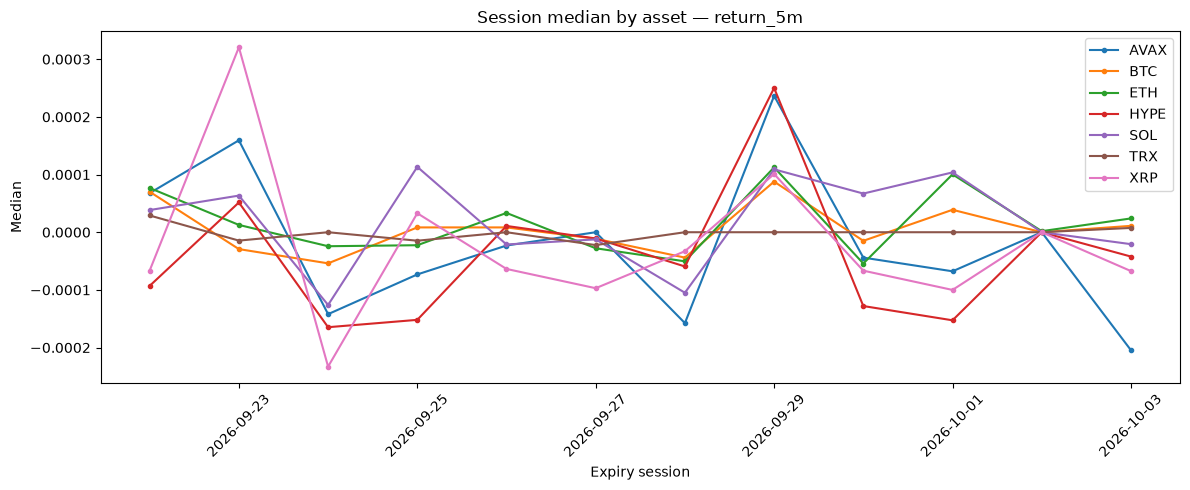

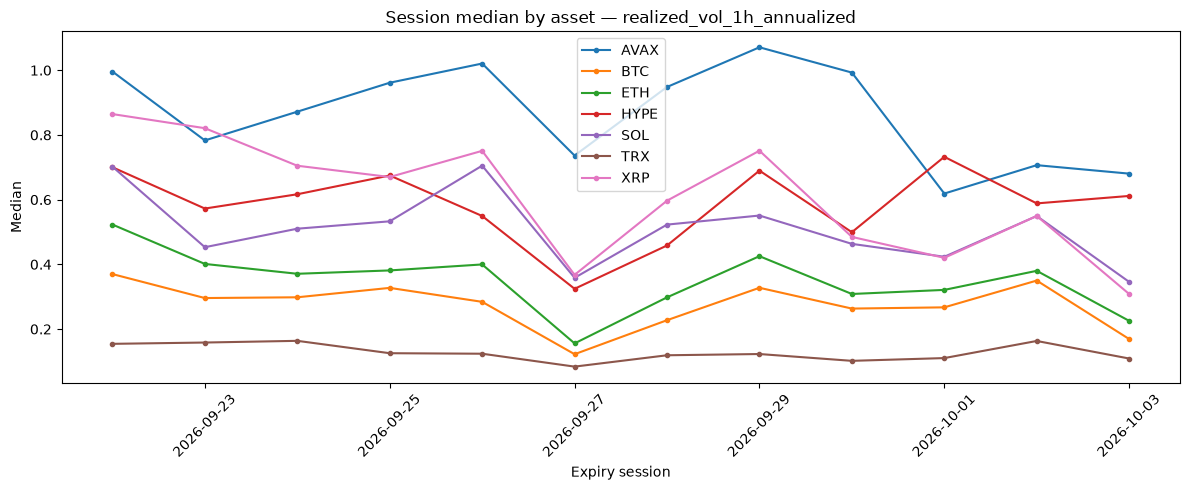

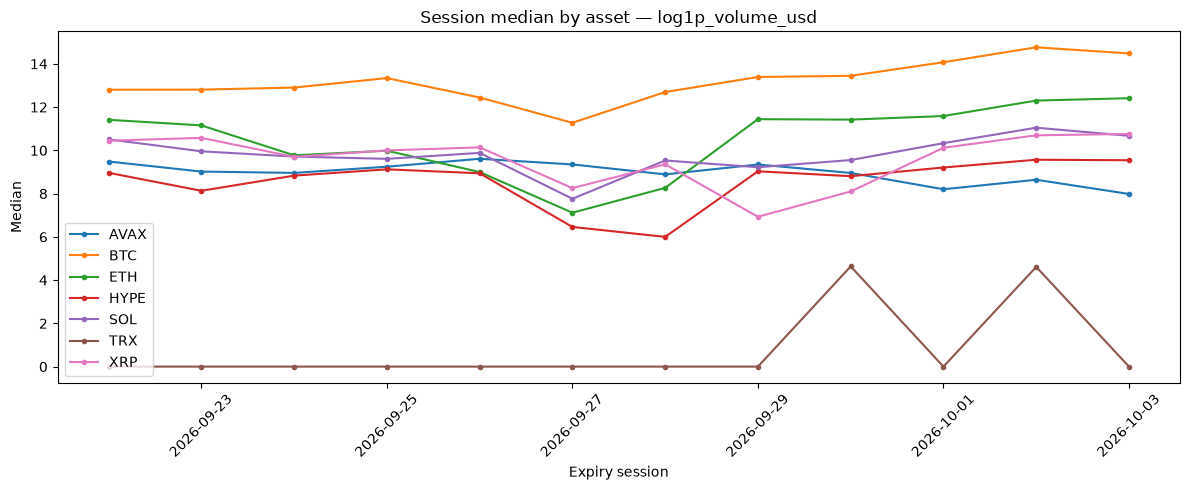

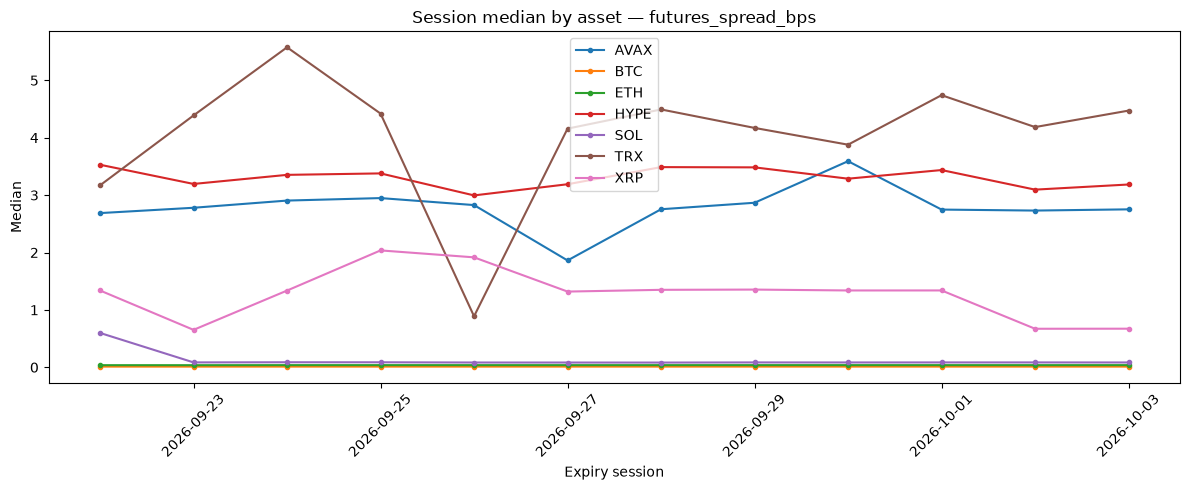

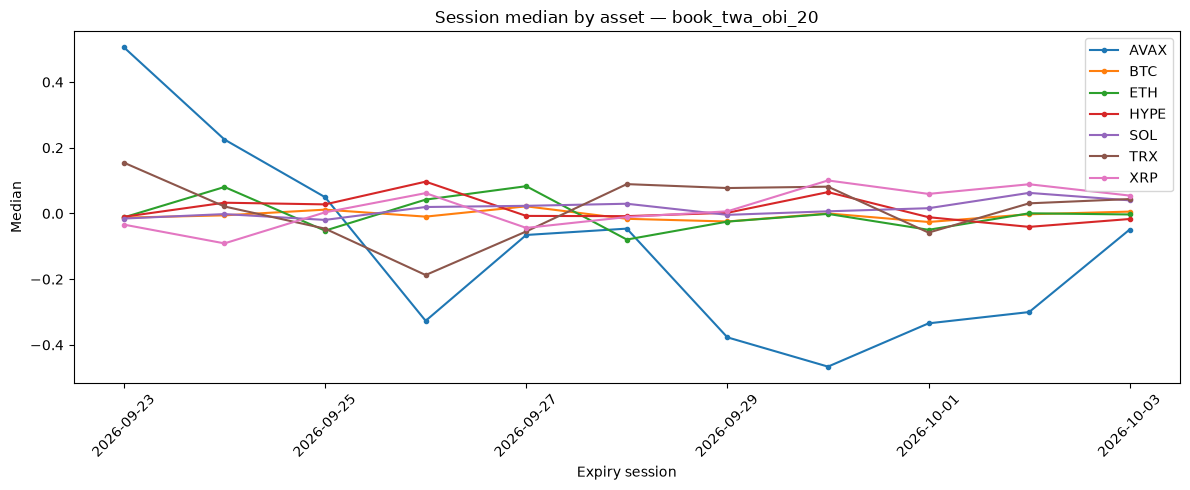

In [23]:
session_features = [
    c for c in [
        "return_5m",
        "realized_vol_1h_annualized",
        "log1p_volume_usd",
        "futures_spread_bps",
        "book_twa_obi_20",
    ]
    if c in features.columns
]

session_rows = []

for (expiry, asset), group in features.groupby(["expiry_date", "underlying"]):
    for col in session_features:
        s = clean_numeric(group, col)
        if s.empty:
            continue

        session_rows.append({
            "expiry_date": expiry,
            "underlying": asset,
            "feature": col,
            "n": len(s),
            "median": s.median(),
            "q90": s.quantile(0.90),
            "q95": s.quantile(0.95),
            "q99": s.quantile(0.99),
        })

session_distribution = pd.DataFrame(session_rows)
display(session_distribution.head(30))

for col in session_features:
    subset = session_distribution[session_distribution["feature"] == col]
    if subset.empty:
        continue

    fig, ax = plt.subplots(figsize=(12, 5))
    for asset, group in subset.groupby("underlying"):
        ax.plot(
            group["expiry_date"],
            group["median"],
            marker="o",
            ms=3,
            label=str(asset),
        )

    ax.set_title(f"Session median by asset — {col}")
    ax.set_xlabel("Expiry session")
    ax.set_ylabel("Median")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    plt.tight_layout()
    plt.show()

# Part H — Candidate Transformations

## 23. Transformation diagnostics

Transformations are evaluated for **scale management and model stability**, not for cosmetic Gaussianization.

Candidate rules used here:

- `log1p(x)` for non-negative long-tailed variables;
- `sign(x) * log1p(|x|)` for signed scale variables;
- raw form retained for bounded variables and returns.

A reduction in skewness is useful evidence, but it is **not sufficient by itself** to promote a transform into production.

In [24]:
TRANSFORM_SPECS = {
    "volume_usd": ("log1p", "non-negative activity scale"),
    "average_trade_size_usd": ("log1p", "non-negative trade-size scale"),
    "intrabar_range_bps": ("log1p", "non-negative range scale"),
    "futures_spread_bps": ("log1p", "non-negative spread scale"),
    "book_twa_spread_bps": ("log1p", "non-negative spread scale"),
    "realized_vol_30m_annualized": ("log1p", "positive volatility scale"),
    "realized_vol_1h_annualized": ("log1p", "positive volatility scale"),
    "realized_vol_4h_annualized": ("log1p", "positive volatility scale"),
    "signed_volume_usd": ("signed_log1p", "signed activity scale"),
    "open_interest_change_5m": ("signed_log1p", "signed level-change scale"),
    "perpetual_mid_vs_index_bps": ("signed_log1p", "signed basis scale"),
    "perpetual_mark_vs_index_bps": ("signed_log1p", "signed basis scale"),
    "microprice_vs_mid_bps": ("signed_log1p", "signed microprice displacement"),
    "book_twa_microprice_vs_reference_bps": (
        "signed_log1p",
        "signed microprice displacement"
    ),
}

transform_rows = []

for col, (transform_name, reason) in TRANSFORM_SPECS.items():
    if col not in features.columns:
        continue

    raw = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

    if transform_name == "log1p":
        transformed = np.log1p(raw.where(raw >= 0))
    elif transform_name == "signed_log1p":
        transformed = signed_log1p(raw)
    else:
        transformed = raw.copy()

    valid_raw = raw.dropna()
    valid_transformed = pd.Series(transformed).replace([np.inf, -np.inf], np.nan).dropna()

    transform_rows.append({
        "feature": col,
        "candidate_transform": transform_name,
        "reason": reason,
        "raw_n": len(valid_raw),
        "raw_skew": valid_raw.skew() if len(valid_raw) else np.nan,
        "raw_excess_kurtosis": valid_raw.kurt() if len(valid_raw) else np.nan,
        "transformed_n": len(valid_transformed),
        "transformed_skew": valid_transformed.skew() if len(valid_transformed) else np.nan,
        "transformed_excess_kurtosis": (
            valid_transformed.kurt() if len(valid_transformed) else np.nan
        ),
    })

transform_assessment = pd.DataFrame(transform_rows)
display(transform_assessment)

,feature,candidate_transform,reason,raw_n,raw_skew,raw_excess_kurtosis,transformed_n,transformed_skew,transformed_excess_kurtosis
0,volume_usd,log1p,non-negative activity scale,23961,41.773862,3382.104714,23961,-0.904741,-0.067565
1,average_trade_size_usd,log1p,non-negative trade-size scale,20694,62.509845,4555.749436,20694,-0.820573,0.467925
2,intrabar_range_bps,log1p,non-negative range scale,20689,3.429338,29.645185,20689,-0.934075,0.549485
3,futures_spread_bps,log1p,non-negative spread scale,23940,53.524993,4517.717488,23940,0.934695,2.987146
4,book_twa_spread_bps,log1p,non-negative spread scale,22064,27.350862,884.175389,22064,0.858417,3.451943
5,realized_vol_30m_annualized,log1p,positive volatility scale,21910,12.052379,358.732018,21910,1.353982,5.189907
6,realized_vol_1h_annualized,log1p,positive volatility scale,20454,9.906100,221.678990,20454,1.286667,5.508085
7,realized_vol_4h_annualized,log1p,positive volatility scale,14056,6.022654,64.996063,14056,1.412572,6.297678
8,signed_volume_usd,signed_log1p,signed activity scale,23961,-4.945988,4240.192318,23961,0.017495,-1.597234
9,open_interest_change_5m,signed_log1p,signed level-change scale,23912,-0.865146,1902.033793,23912,0.060390,0.246199


## 24. Features that should initially remain in native bounded / return form

These are not automatic production decisions. They are the default hypotheses to carry into the later feature-contract notebook.

- Returns: retain signed return interpretation; evaluate robust emission families rather than forcing normality.
- `trade_flow_imbalance`, `buy_volume_share`, and OBI variables: retain bounded support and explicitly model endpoint / boundary behavior where relevant.
- Proportional OI change: retain raw initially unless tails prove numerically problematic.
- Cross-asset scale differences: preserve them until the deterministic normalization study determines what should be asset/TOD/TTE conditioned.

In [25]:
native_form_candidates = [
    c for c in [
        "return_5m",
        "return_15m",
        "return_30m",
        "return_1h",
        "trade_flow_imbalance",
        "buy_volume_share",
        "book_twa_obi_5",
        "book_twa_obi_10",
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
        "open_interest_return_5m",
        "_diag_depth_imbalance_20",
    ]
    if c in features.columns
]

native_summary = feature_summary(features, native_form_candidates)

if not native_summary.empty:
    display(
        native_summary[
            [
                "feature",
                "n",
                "skew",
                "excess_kurtosis",
                "min",
                "q01",
                "median",
                "q99",
                "max",
            ]
        ]
    )

,feature,n,skew,excess_kurtosis,min,q01,median,q99,max
0,return_5m,23317,-0.208627,306.874587,-0.096015,-0.005798,0.000000,0.005687,0.096277
1,return_15m,23296,-0.464800,54.791981,-0.097046,-0.010312,0.000000,0.009904,0.095218
2,return_30m,23247,-0.404792,20.281032,-0.096828,-0.014083,0.000000,0.013206,0.095638
3,return_1h,23205,-0.136310,8.709333,-0.096610,-0.019086,-0.000041,0.018819,0.093610
4,trade_flow_imbalance,20694,0.020513,-1.069728,-1.000000,-1.000000,-0.003459,1.000000,1.000000
5,buy_volume_share,20694,0.020513,-1.069728,0.000000,0.000000,0.498271,1.000000,1.000000
6,book_twa_obi_5,22071,0.155495,1.575078,-0.856850,-0.573755,0.014796,0.637608,0.915902
7,book_twa_obi_10,22071,0.165930,1.043286,-0.795102,-0.416701,0.012838,0.477485,0.749387
8,book_twa_obi_20,22071,-0.260231,2.761221,-0.807421,-0.479865,0.004268,0.454874,0.714406
9,book_twa_obi_20_change_5m,22057,-0.004937,3.998593,-0.593039,-0.199201,-0.000072,0.201253,0.560171


# Part I — Futures Data Integrity

## 25. Why this part exists

Parts A–E show tail events that may be **feed artifacts rather than market behaviour** (audit A1): constant spreads with `return_5m = 0` for an hour while trading continued, a ±9.6% TRX round trip on zero volume, and 500–800 bps book spreads with no trades.

Before any return-based feature is trusted, each five-minute futures state is tested with signals that existed **before collector v0.3**:

| Test | Raw fields | What it detects |
|---|---|---|
| Wide quote | `best_bid_price`, `best_ask_price` | Spread far above the asset's own typical spread |
| Mid off index | ticker mid, `index_price` | Perpetual mid detached from the settlement index |
| Ticker vs L2 disagreement | ticker BBO vs `book_best_bid_price` / `book_best_ask_price` | One of the two feeds is stale |
| Stale BBO vs index | BBO unchanged across states while the index moved more than half the quoted spread | Quotes that a live market would have repriced |
| Frozen BBO with trades | identical BBO for ≥ `FROZEN_MIN_BARS` states while `trade_count > 0` | Trading continues against a frozen quote |
| Last trade outside BBO | `close`, `last_trade_timestamp_ms` vs boundary BBO | A trade printed shortly before the boundary outside the recorded quote |
| No L2 updates | `book_update_count = 0` with `trade_count > 0` | Dead book subscription |

**Scope.** Thresholds here are full-sample robust statistics, used only to **find and describe** episodes. They are not a production rule: the integrity gate in `quality_contract.py` must estimate its thresholds on training history only. Nothing is dropped from any table.

All timestamps in this part are **UTC** (`SET TimeZone='UTC'` in Section 1).

In [26]:
RAW_WANTED = [
    "underlying", "bar_end", "instrument_name",
    "best_bid_price", "best_ask_price", "mid_price",
    "mark_price", "index_price", "open_interest",
    "book_valid", "book_best_bid_price", "book_best_ask_price", "book_mid_price",
    "book_update_count", "book_stats_complete", "book_age_ms",
    "ticker_age_ms", "ticker_exchange_timestamp_ms",
    "open", "high", "low", "close", "vwap",
    "volume_usd", "trade_count", "last_trade_timestamp_ms",
    "stream_complete", "stream_incomplete_reason", "connection_count",
    "collector_version",
]

def load_raw_futures():
    """Raw perpetual rows with every pre-v0.3 integrity field.

    Uses the research DB's raw view when present; otherwise reads the
    Parquet files directly. Both paths are read-only.
    """
    has_view = con.execute(
        "SELECT COUNT(*) FROM duckdb_views() WHERE view_name = 'raw_futures_5m'"
    ).fetchone()[0] > 0

    if has_view:
        source = "raw_futures_5m"
    else:
        glob = (DATA_ROOT / "futures" / "5m" / "date=*" / "futures_5m.parquet").as_posix()
        source = (
            f"read_parquet('{glob}', hive_partitioning = true, union_by_name = true)"
        )

    available = set(
        con.execute(f"DESCRIBE SELECT * FROM {source}").df()["column_name"]
    )
    selected = [c for c in RAW_WANTED if c in available]
    missing = [c for c in RAW_WANTED if c not in available]

    raw = con.execute(
        f"SELECT {', '.join(selected)} FROM {source} "
        "ORDER BY underlying, bar_end, instrument_name"
    ).df()

    return raw, source, missing

raw_futures_all, raw_source, raw_missing = load_raw_futures()

raw_futures_all["bar_end"] = pd.to_datetime(raw_futures_all["bar_end"], utc=True)

print(f"Source:            {raw_source}")
print(f"Raw rows:          {len(raw_futures_all):,}")
print(f"First / last bar:  {raw_futures_all['bar_end'].min()}  /  {raw_futures_all['bar_end'].max()}")
print(f"Fields not found:  {raw_missing if raw_missing else 'none'}")

# One perpetual per underlying is expected. Several instruments per
# underlying would make the canonical rank-by-name choice switch
# instruments, which would show up as OI and price jumps.
instrument_inventory = (
    raw_futures_all
    .groupby(["underlying", "instrument_name"], dropna=False)
    .agg(rows=("bar_end", "size"), first_bar=("bar_end", "min"), last_bar=("bar_end", "max"))
    .reset_index()
)
display(instrument_inventory)

dup_states = int(raw_futures_all.duplicated(["underlying", "bar_end"]).sum())
print(f"Duplicate (underlying, bar_end) rows: {dup_states:,}")

# Same canonical choice as build_canonical.py: first instrument_name per state.
raw_futures = (
    raw_futures_all
    .drop_duplicates(["underlying", "bar_end"], keep="first")
    .sort_values(["underlying", "bar_end"])
    .reset_index(drop=True)
)

if "collector_version" in raw_futures.columns:
    display(
        raw_futures
        .assign(collector_version=raw_futures["collector_version"].fillna("pre-v0.3 (unstamped)"))
        .groupby("collector_version")
        .agg(rows=("bar_end", "size"), first_bar=("bar_end", "min"), last_bar=("bar_end", "max"))
    )

Source:            raw_futures_5m
Raw rows:          28,539
First / last bar:  2026-09-21 10:30:00+00:00  /  2026-10-05 14:25:00+00:00
Fields not found:  none


,underlying,instrument_name,rows,first_bar,last_bar
0,AVAX,AVAX_USDC-PERPETUAL,4077,2026-09-21 10:30:00+00:00,2026-10-05 14:25:00+00:00
1,BTC,BTC_USDC-PERPETUAL,4077,2026-09-21 10:30:00+00:00,2026-10-05 14:25:00+00:00
2,ETH,ETH_USDC-PERPETUAL,4077,2026-09-21 10:30:00+00:00,2026-10-05 14:25:00+00:00
3,HYPE,HYPE_USDC-PERPETUAL,4077,2026-09-21 10:30:00+00:00,2026-10-05 14:25:00+00:00
4,SOL,SOL_USDC-PERPETUAL,4077,2026-09-21 10:30:00+00:00,2026-10-05 14:25:00+00:00
5,TRX,TRX_USDC-PERPETUAL,4077,2026-09-21 10:30:00+00:00,2026-10-05 14:25:00+00:00
6,XRP,XRP_USDC-PERPETUAL,4077,2026-09-21 10:30:00+00:00,2026-10-05 14:25:00+00:00


Duplicate (underlying, bar_end) rows: 0


,rows,first_bar,last_bar
collector_version,,,
futures_5m_l2_v0.3.0,1862,2026-10-04 16:20:00+00:00,2026-10-05 14:25:00+00:00
pre-v0.3 (unstamped),26677,2026-09-21 10:30:00+00:00,2026-10-04 16:15:00+00:00


## 26. Per-state integrity metrics

All lags are taken on the exact five-minute grid per asset; a lag across a gap is `NaN`, never bridged.

Definitions (bps of the relevant price):

$$
s_t = 10^4\,\frac{a_t - b_t}{m_t}, \qquad
\text{basis}_t = 10^4 \ln\frac{m_t}{I_t}, \qquad
\Delta^{\text{tick/L2}}_t = 10^4\,\frac{\left|m_t - m^{L2}_t\right|}{m_t}
$$

where $b_t, a_t, m_t$ are the ticker bid, ask and mid at the state boundary, $m^{L2}_t$ is the L2 book mid and $I_t$ is the Deribit index.

**Stale BBO vs index.** Let $t_0$ be the last state at which the ticker BBO changed. If the BBO is unchanged at $t$ but

$$
10^4\left|\ln\frac{I_t}{I_{t_0}}\right| > \tfrac12\, s_t,
$$

the recorded quote no longer brackets where the index says the market is.

**Last trade outside BBO.** Only trades within `LAST_TRADE_RECENCY_MS` of the boundary are tested, so that a legitimate move between the trade and the snapshot is small:

$$
o_t = 10^4\,\frac{\max\left(\text{close}_t - a_t,\; b_t - \text{close}_t,\; 0\right)}{m_t}
$$

In [27]:
LAST_TRADE_RECENCY_MS = 30_000
FROZEN_MIN_BARS = 3

def lag_on_grid(g, column, lag=1):
    """Value `lag` five-minute states earlier, or NaN if the grid has a gap."""
    shifted = g[column].shift(lag)
    gap_ok = (g["bar_end"] - g["bar_end"].shift(lag)) == pd.Timedelta(minutes=5 * lag)
    return shifted.where(gap_ok)

def num(df, col):
    if col not in df.columns:
        return pd.Series(np.nan, index=df.index)
    return pd.to_numeric(df[col], errors="coerce")

def integrity_metrics(g):
    g = g.sort_values("bar_end").copy()

    bid, ask, index = num(g, "best_bid_price"), num(g, "best_ask_price"), num(g, "index_price")
    two_sided = (bid > 0) & (ask > 0) & (bid <= ask)
    mid = ((bid + ask) / 2).where(two_sided)
    g["tick_mid"] = mid
    g["tick_spread_bps"] = (1e4 * (ask - bid) / mid).where(two_sided)
    g["mid_vs_index_bps"] = (1e4 * np.log(mid / index)).where(index > 0)
    g["mark_vs_index_bps"] = (1e4 * np.log(num(g, "mark_price") / index)).where(index > 0)

    vwap = num(g, "vwap")
    g["vwap_vs_index_bps"] = (1e4 * np.log(vwap / index)).where((vwap > 0) & (index > 0))

    l2_bid, l2_ask = num(g, "book_best_bid_price"), num(g, "book_best_ask_price")
    l2_ok = (l2_bid > 0) & (l2_ask > 0) & (l2_bid <= l2_ask)
    g["l2_spread_bps"] = (1e4 * (l2_ask - l2_bid) / ((l2_ask + l2_bid) / 2)).where(l2_ok)
    g["tick_vs_l2_mid_bps"] = (1e4 * ((l2_bid + l2_ask) / 2 - mid).abs() / mid).where(l2_ok & two_sided)

    # BBO change tracking on the exact grid.
    g["_bid"], g["_ask"] = bid.where(two_sided), ask.where(two_sided)
    prev_bid, prev_ask = lag_on_grid(g, "_bid"), lag_on_grid(g, "_ask")
    g["bbo_unchanged"] = (g["_bid"] == prev_bid) & (g["_ask"] == prev_ask)

    # A new run starts whenever the BBO changes, the grid breaks or the quote is invalid.
    run_start = ~g["bbo_unchanged"]
    run_id = run_start.cumsum()
    g["bbo_run_bars"] = g.groupby(run_id).cumcount() + 1
    g["_index_at_change"] = index.where(run_start).groupby(run_id).transform("first")
    g["index_drift_since_bbo_change_bps"] = (
        1e4 * np.log(index / g["_index_at_change"]).abs()
    ).where(g["bbo_unchanged"])

    trades = num(g, "trade_count").fillna(0)
    g["_trades"] = trades
    g["bbo_frozen_trade_bars"] = (
        (g["bbo_unchanged"] & (trades > 0))
        .astype(int)
        .groupby(run_id)
        .cumsum()
    )

    # Last trade close vs the boundary quote, only for recent trades.
    end_ms = g["bar_end"].astype("int64") // 10**6
    recency = end_ms - num(g, "last_trade_timestamp_ms")
    close = num(g, "close")
    outside = np.maximum.reduce([close - ask, bid - close, pd.Series(0.0, index=g.index)])
    g["last_trade_recency_ms"] = recency
    g["last_trade_outside_bbo_bps"] = (1e4 * outside / mid).where(
        two_sided & (close > 0) & (recency >= 0) & (recency <= LAST_TRADE_RECENCY_MS)
    )

    g["index_return_5m"] = np.log(index / lag_on_grid(g.assign(_i=index), "_i")).where(index > 0)
    g["mid_return_5m_raw"] = np.log(mid / lag_on_grid(g.assign(_m=mid), "_m"))
    g["two_sided_ticker"] = two_sided

    return g.drop(columns=["_bid", "_ask", "_index_at_change", "_trades"])

def per_asset(df, func, **kwargs):
    """Apply a frame-level function per underlying (explicit loop: no groupby.apply)."""
    parts = [func(g, **kwargs) for _, g in df.groupby("underlying", sort=True)]
    return pd.concat(parts, ignore_index=True) if parts else df.iloc[0:0].copy()

integrity = per_asset(raw_futures, integrity_metrics)

metric_cols = [
    "tick_spread_bps", "l2_spread_bps", "tick_vs_l2_mid_bps",
    "mid_vs_index_bps", "mark_vs_index_bps", "vwap_vs_index_bps",
    "index_drift_since_bbo_change_bps", "last_trade_outside_bbo_bps",
    "ticker_age_ms", "book_age_ms", "book_update_count",
]
display(feature_summary(integrity, [c for c in metric_cols if c in integrity.columns], group_col="underlying"))

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,tick_spread_bps,4073,0.098111,3.618495,11.806923,27.609321,1013.617599,0.873324,0.889183,0.900899,0.958764,2.729879,5.590757,7.547580,1.279164e+02,5.209854e+02
1,AVAX,l2_spread_bps,265,93.500123,2.199570,0.910337,2.276932,8.885015,0.900212,0.900447,0.901624,0.909000,1.820830,3.654503,5.443134,7.683299e+00,8.177729e+00
2,AVAX,tick_vs_l2_mid_bps,265,93.500123,0.001723,0.028050,16.278821,265.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.360731e-01,4.566210e-01
3,AVAX,mid_vs_index_bps,4073,0.098111,2.256386,5.796407,20.198565,728.468299,-39.557725,-12.341003,-7.930069,-3.626213,2.254436,7.269662,11.073582,5.102279e+01,2.340204e+02
4,AVAX,mark_vs_index_bps,4073,0.098111,2.266931,4.898070,30.719115,1528.721968,-9.786913,-8.877605,-7.234058,-2.781133,1.949508,6.674235,9.593763,1.568847e+01,2.468378e+02
5,AVAX,vwap_vs_index_bps,3744,8.167770,2.174227,15.903964,-0.266225,3.131443,-101.908263,-72.187237,-41.752863,-23.304828,2.577362,27.105026,43.105978,7.386808e+01,7.827100e+01
6,AVAX,index_drift_since_bbo_change_bps,41,98.994359,9.670628,19.831629,2.314983,4.347151,0.000000,0.000000,0.000000,0.000000,0.919667,55.982088,73.201062,7.483364e+01,7.501504e+01
7,AVAX,ticker_age_ms,4073,0.098111,1366.282102,2492.264845,7.060354,79.698270,68.000000,82.360000,121.000000,193.000000,626.000000,5049.000000,11781.720000,2.636855e+04,4.926200e+04
8,AVAX,book_age_ms,3805,6.671572,6287.753482,114868.753423,23.164382,570.690962,69.000000,82.000000,103.080000,161.000000,449.000000,2332.600000,4706.360000,2.275838e+06,3.417038e+06
9,AVAX,book_update_count,3809,6.573461,607.930953,130.352549,-0.591628,1.149640,0.000000,0.000000,303.000000,394.000000,616.000000,805.000000,851.000000,8.741920e+02,8.810000e+02


## 27. Candidate integrity flags

Robust per-asset scale: for a metric $x$ with per-asset median $\tilde x$,

$$
z_t = \frac{x_t - \tilde x}{\max\left(1.4826\,\mathrm{MAD}(x),\ \text{floor}\right)}
$$

The floor stops a zero MAD (TRX and HYPE often sit on one tick) from flagging every one-tick change. Spread is scored in logs because it is positive and right-skewed.

`ROBUST_Z` is a **diagnostic** cutoff. The table after the flags shows how the flag counts respond to it; a count that changes a lot between $z = 6$ and $z = 10$ is a sign the cutoff, not the data, is deciding.

In [28]:
ROBUST_Z = 8.0
LOG_SPREAD_FLOOR = 0.10   # ≈ 10% change in spread
BASIS_FLOOR_BPS = 1.0
TICK_L2_FLOOR_BPS = 1.0
LAST_TRADE_OUTSIDE_MIN_BPS = 5.0

def robust_z(x, floor):
    x = pd.to_numeric(x, errors="coerce")
    med = x.median()
    mad = (x - med).abs().median()
    scale = max(1.4826 * mad, floor) if np.isfinite(mad) else floor
    return (x - med) / scale

def add_flags(g, z=ROBUST_Z):
    g = g.copy()
    log_spread = np.log(g["tick_spread_bps"].where(g["tick_spread_bps"] > 0))
    g["z_log_spread"] = robust_z(log_spread, LOG_SPREAD_FLOOR)
    g["z_basis"] = robust_z(g["mid_vs_index_bps"], BASIS_FLOOR_BPS)
    g["z_tick_l2"] = robust_z(g["tick_vs_l2_mid_bps"], TICK_L2_FLOOR_BPS)

    trades = num(g, "trade_count").fillna(0)
    updates = num(g, "book_update_count")

    g["flag_wide_spread"] = g["z_log_spread"] > z
    g["flag_mid_off_index"] = g["z_basis"].abs() > z
    g["flag_tick_l2_disagree"] = g["z_tick_l2"] > z
    g["flag_stale_vs_index"] = (
        g["bbo_unchanged"]
        & (g["index_drift_since_bbo_change_bps"] > 0.5 * g["tick_spread_bps"])
    )
    g["flag_frozen_with_trades"] = g["bbo_frozen_trade_bars"] >= FROZEN_MIN_BARS
    g["flag_trade_outside_bbo"] = g["last_trade_outside_bbo_bps"] > LAST_TRADE_OUTSIDE_MIN_BPS
    g["flag_no_l2_updates"] = (updates == 0) & (trades > 0)
    g["flag_no_two_sided"] = ~g["two_sided_ticker"].astype(bool)
    return g

FLAG_COLS = [
    "flag_wide_spread", "flag_mid_off_index", "flag_tick_l2_disagree",
    "flag_stale_vs_index", "flag_frozen_with_trades",
    "flag_trade_outside_bbo", "flag_no_l2_updates", "flag_no_two_sided",
]

integrity = per_asset(integrity, add_flags)
integrity[FLAG_COLS] = integrity[FLAG_COLS].fillna(False).astype(bool)
integrity["suspect_quote"] = integrity[FLAG_COLS].any(axis=1)

flag_counts = (
    integrity
    .groupby("underlying")[FLAG_COLS + ["suspect_quote"]]
    .sum()
    .assign(states=integrity.groupby("underlying").size())
)
flag_pct = flag_counts[FLAG_COLS + ["suspect_quote"]].div(flag_counts["states"], axis=0).mul(100)

print("Flagged states (count):")
display(flag_counts)
print("Flagged states (% of raw states):")
display(flag_pct.round(3))

# Sensitivity of the robust-z flags to the cutoff.
sensitivity_rows = []
for z in [4, 6, 8, 10, 15]:
    tmp = per_asset(integrity, add_flags, z=z)
    for asset, g in tmp.groupby("underlying"):
        sensitivity_rows.append({
            "underlying": asset, "z": z,
            "wide_spread": int(g["flag_wide_spread"].sum()),
            "mid_off_index": int(g["flag_mid_off_index"].sum()),
            "tick_l2_disagree": int(g["flag_tick_l2_disagree"].sum()),
        })
flag_sensitivity = pd.DataFrame(sensitivity_rows)
display(flag_sensitivity.pivot(index="underlying", columns="z"))

Flagged states (count):


,flag_wide_spread,flag_mid_off_index,flag_tick_l2_disagree,flag_stale_vs_index,flag_frozen_with_trades,flag_trade_outside_bbo,flag_no_l2_updates,flag_no_two_sided,suspect_quote,states
underlying,,,,,,,,,,
AVAX,2,12,0,17,8,0,8,4,35,4077
BTC,222,11,0,10,8,0,4,4,234,4077
ETH,184,13,0,12,7,0,7,4,197,4077
HYPE,16,14,0,0,8,0,8,4,21,4077
SOL,1105,11,0,6,7,0,7,4,1116,4077
TRX,13,14,0,65,0,0,0,4,83,4077
XRP,0,16,0,30,2,0,6,4,50,4077


Flagged states (% of raw states):


,flag_wide_spread,flag_mid_off_index,flag_tick_l2_disagree,flag_stale_vs_index,flag_frozen_with_trades,flag_trade_outside_bbo,flag_no_l2_updates,flag_no_two_sided,suspect_quote
underlying,,,,,,,,,
AVAX,0.049,0.294,0.0,0.417,0.196,0.0,0.196,0.098,0.858
BTC,5.445,0.270,0.0,0.245,0.196,0.0,0.098,0.098,5.740
ETH,4.513,0.319,0.0,0.294,0.172,0.0,0.172,0.098,4.832
HYPE,0.392,0.343,0.0,0.000,0.196,0.0,0.196,0.098,0.515
SOL,27.103,0.270,0.0,0.147,0.172,0.0,0.172,0.098,27.373
TRX,0.319,0.343,0.0,1.594,0.000,0.0,0.000,0.098,2.036
XRP,0.000,0.392,0.0,0.736,0.049,0.0,0.147,0.098,1.226


wide_spread                         mid_off_index                 tick_l2_disagree            
z                   4     6     8     10    15            4   6   8   10  15               4  6  8  10 15
underlying                                                                                               
AVAX                17    16     2     0     0            59  14  12   9   7                0  0  0  0  0
BTC                231   231   222   222   215            19  11  11  10   9                0  0  0  0  0
ETH                195   195   184   184   182            21  13  13  13   8                0  0  0  0  0
HYPE                16    16    16     2     0            21  15  14  11   6                0  0  0  0  0
SOL               1194  1194  1105  1105  1006            22  12  11   8   7                0  0  0  0  0
TRX                 16    15    13     1     0            15  14  14  13   3                0  0  0  0  0
XRP                 13     6     0     0     0            66  19  16  16  15                0  0  0  0  0

## 28. Suspect episodes

Consecutive suspect states per asset are merged into **episodes**. A single long episode and many isolated states call for different gate designs: the first points to a feed failure, the second to a threshold or an illiquid asset.

`cross_asset_overlap` counts how many other underlyings have a suspect state at the same timestamp. Simultaneous episodes across unrelated perpetuals point to the collector or the exchange, not the market.

In [29]:
work = integrity.sort_values(["underlying", "bar_end"]).copy()
prev_suspect = work.groupby("underlying")["suspect_quote"].shift(1, fill_value=False)
prev_time = work.groupby("underlying")["bar_end"].shift(1)
contiguous = (work["bar_end"] - prev_time) == pd.Timedelta(minutes=5)
work["_episode_start"] = work["suspect_quote"] & ~(prev_suspect & contiguous)
work["episode_id"] = work.groupby("underlying")["_episode_start"].cumsum().where(work["suspect_quote"])

suspect_by_time = work.loc[work["suspect_quote"]].groupby("bar_end")["underlying"].nunique()
work["cross_asset_overlap"] = work["bar_end"].map(suspect_by_time).fillna(0).astype(int) - work["suspect_quote"].astype(int)

ep = work.loc[work["suspect_quote"]]
episodes = (
    ep.groupby(["underlying", "episode_id"])
    .agg(
        start=("bar_end", "min"),
        end=("bar_end", "max"),
        states=("bar_end", "size"),
        trades=("trade_count", "sum"),
        volume_usd=("volume_usd", "sum"),
        max_spread_bps=("tick_spread_bps", "max"),
        max_abs_basis_bps=("mid_vs_index_bps", lambda s: s.abs().max()),
        max_abs_mid_return=("mid_return_5m_raw", lambda s: s.abs().max()),
        max_abs_index_return=("index_return_5m", lambda s: s.abs().max()),
        max_cross_asset_overlap=("cross_asset_overlap", "max"),
        **{f.replace("flag_", "n_"): (f, "sum") for f in FLAG_COLS},
    )
    .reset_index()
    .sort_values(["states", "max_spread_bps"], ascending=False)
)

print(f"Suspect states: {int(work['suspect_quote'].sum()):,} in {len(episodes):,} episodes")
display(
    episodes.groupby("underlying").agg(
        episodes=("states", "size"),
        single_state=("states", lambda s: int((s == 1).sum())),
        median_states=("states", "median"),
        max_states=("states", "max"),
    )
)
print("Longest / widest episodes:")
display(episodes.head(30))

print("Suspect states by UTC date and underlying:")
display(
    work.assign(date=work["bar_end"].dt.date)
    .pivot_table(index="date", columns="underlying", values="suspect_quote", aggfunc="sum", fill_value=0)
)

Suspect states: 1,736 in 1,088 episodes


,episodes,single_state,median_states,max_states
underlying,,,,
AVAX,23,21,1.0,11
BTC,168,132,1.0,14
ETH,144,120,1.0,12
HYPE,5,3,1.0,12
SOL,664,457,1.0,19
TRX,48,37,1.0,13
XRP,36,34,1.0,12


Longest / widest episodes:


,underlying,episode_id,start,end,states,trades,volume_usd,max_spread_bps,max_abs_basis_bps,max_abs_mid_return,max_abs_index_return,max_cross_asset_overlap,n_wide_spread,n_mid_off_index,n_tick_l2_disagree,n_stale_vs_index,n_frozen_with_trades,n_trade_outside_bbo,n_no_l2_updates,n_no_two_sided
457,SOL,118.0,2026-09-23 15:50:00+00:00,2026-09-23 17:20:00+00:00,19,8827,2.277191e+06,3.599570,5.816638,0.007838,0.008554,2,19,0,0,0,0,0,0,0
893,SOL,554.0,2026-10-01 09:00:00+00:00,2026-10-01 10:10:00+00:00,15,990,1.660617e+07,66.662132,36.986817,0.004576,0.005061,6,15,9,0,0,7,0,7,0
173,BTC,151.0,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,14,3046,1.777760e+08,53.876085,38.266111,0.000941,0.003681,6,14,11,0,2,7,0,4,0
1049,TRX,46.0,2026-10-01 09:00:00+00:00,2026-10-01 10:00:00+00:00,13,5,1.583659e+04,189.781676,88.354503,0.008666,0.001397,6,12,12,0,1,0,0,0,0
358,SOL,19.0,2026-09-21 18:10:00+00:00,2026-09-21 19:10:00+00:00,13,3264,1.498894e+05,3.741528,4.356601,0.003283,0.003190,2,13,0,0,0,0,0,0,0
450,SOL,111.0,2026-09-23 12:35:00+00:00,2026-09-23 13:35:00+00:00,13,3594,7.330119e+05,3.013721,2.651771,0.004725,0.004611,1,13,0,0,0,0,0,0,0
1064,XRP,13.0,2026-10-01 09:05:00+00:00,2026-10-01 10:00:00+00:00,12,417,5.766427e+06,487.063411,197.235868,0.020564,0.001812,6,0,12,0,0,2,0,6,0
338,HYPE,4.0,2026-10-01 09:05:00+00:00,2026-10-01 10:00:00+00:00,12,233,8.386108e+06,328.927522,60.740728,0.005630,0.003036,6,12,9,0,0,8,0,8,0
324,ETH,134.0,2026-10-01 09:05:00+00:00,2026-10-01 10:00:00+00:00,12,1014,7.382589e+07,41.985735,40.432337,0.000851,0.001022,6,12,11,0,3,7,0,7,0
9,AVAX,10.0,2026-10-01 09:10:00+00:00,2026-10-01 10:00:00+00:00,11,121,7.628047e+05,127.916404,70.511954,0.000000,0.003505,6,0,7,0,2,8,0,8,0


Suspect states by UTC date and underlying:


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
date,,,,,,,
2026-09-21,1,50,54,1,109,1,1
2026-09-22,0,41,38,0,93,5,2
2026-09-23,1,27,25,0,128,1,0
2026-09-24,0,17,10,0,103,0,1
2026-09-25,1,17,7,0,104,7,0
2026-09-26,1,4,4,0,65,29,3
2026-09-27,1,3,1,0,78,4,0
2026-09-28,3,19,17,6,98,10,4
2026-09-29,2,5,9,1,77,5,2


## 29. Known windows from the audit

The three windows found in Parts D–E are re-examined on raw fields. The plot windows are deliberately wide (±3 h): the audit times were read from notebook outputs printed before the UTC fix, so they may carry a two-hour offset.

For each window the question is the same: **did the market move, or did the quote stop updating?** The index and the trade VWAP are the references; the perpetual mid is the suspect.


=== TRX ±9.6% round trip on zero volume | 2026-09-21 14:10 – 20:10 UTC ===


,states,suspect,first_suspect,last_suspect,max_spread_bps,trades
underlying,,,,,,
AVAX,73,1,2026-09-21 17:10:00+00:00,2026-09-21 17:10:00+00:00,520.985361,2541
TRX,73,1,2026-09-21 17:10:00+00:00,2026-09-21 17:10:00+00:00,2139.637859,704
XRP,73,1,2026-09-21 17:10:00+00:00,2026-09-21 17:10:00+00:00,485.956891,5462


,bar_end,underlying,tick_spread_bps,l2_spread_bps,mid_vs_index_bps,vwap_vs_index_bps,tick_vs_l2_mid_bps,bbo_run_bars,index_drift_since_bbo_change_bps,last_trade_outside_bbo_bps,trade_count,volume_usd,book_update_count,book_age_ms,ticker_age_ms,mid_return_5m_raw,index_return_5m,stream_complete,suspect_quote,flag_wide_spread,flag_mid_off_index,flag_tick_l2_disagree,flag_stale_vs_index,flag_frozen_with_trades,flag_trade_outside_bbo,flag_no_l2_updates,flag_no_two_sided
79,2026-09-21 17:10:00+00:00,AVAX,520.985361,NaN,234.020389,-1.791399,NaN,1,NaN,NaN,50,34809.520862,NaN,NaN,1622.0,0.026031,0.001994,True,True,True,True,False,False,False,False,False,False
20464,2026-09-21 17:10:00+00:00,TRX,2139.637859,NaN,964.652706,NaN,NaN,1,NaN,NaN,0,0.000000,NaN,NaN,9753.0,0.096277,0.000308,True,True,True,True,False,False,False,False,False,False
24541,2026-09-21 17:10:00+00:00,XRP,485.956891,NaN,219.905187,-19.706719,NaN,1,NaN,NaN,11,46536.096300,NaN,NaN,1464.0,0.027682,0.006027,True,True,False,True,False,False,False,False,False,False


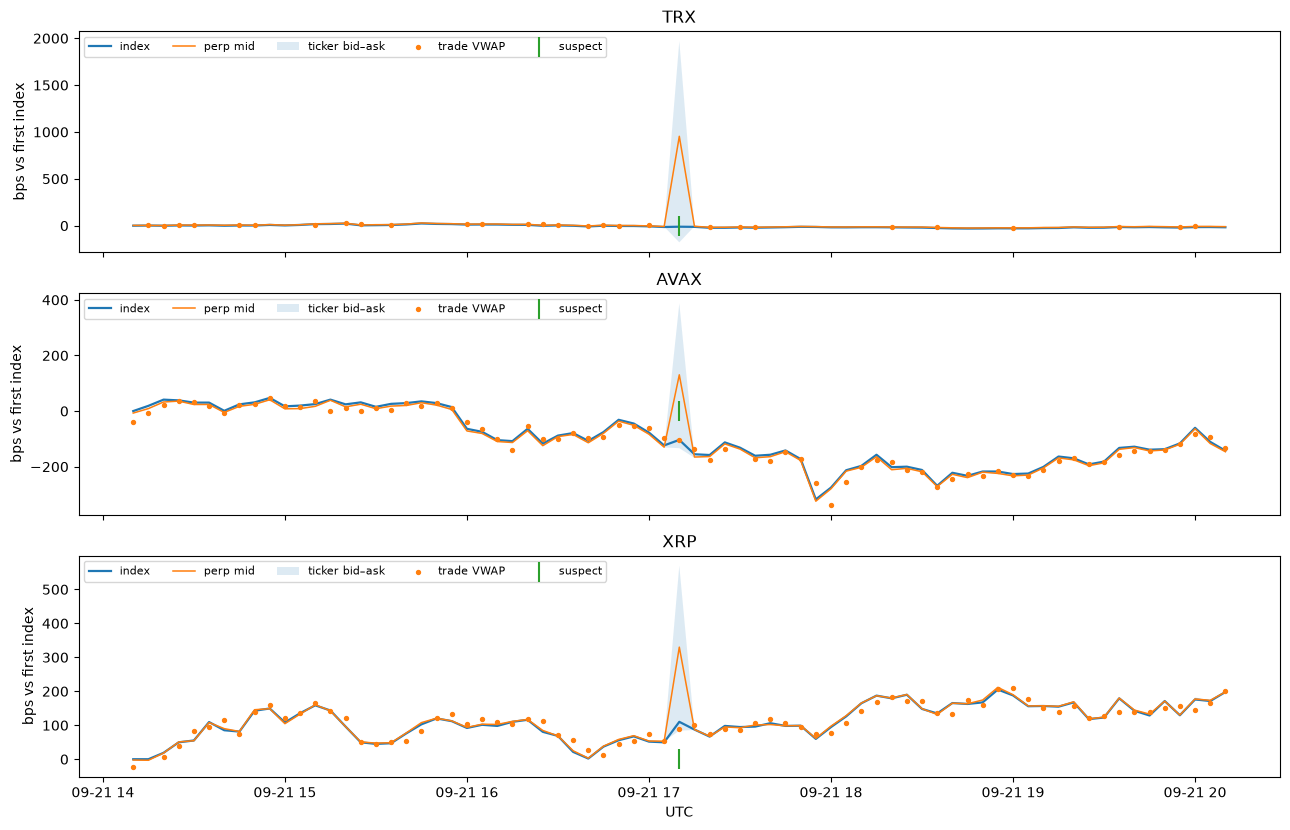


=== HYPE / XRP wide book spreads, no trades | 2026-09-28 06:25 – 12:25 UTC ===


,states,suspect,first_suspect,last_suspect,max_spread_bps,trades
underlying,,,,,,
HYPE,73,6,2026-09-28 09:05:00+00:00,2026-09-28 09:30:00+00:00,620.346856,1733
XRP,73,4,2026-09-28 09:05:00+00:00,2026-09-28 09:20:00+00:00,24.843052,1195


,bar_end,underlying,tick_spread_bps,l2_spread_bps,mid_vs_index_bps,vwap_vs_index_bps,tick_vs_l2_mid_bps,bbo_run_bars,index_drift_since_bbo_change_bps,last_trade_outside_bbo_bps,trade_count,volume_usd,book_update_count,book_age_ms,ticker_age_ms,mid_return_5m_raw,index_return_5m,stream_complete,suspect_quote,flag_wide_spread,flag_mid_off_index,flag_tick_l2_disagree,flag_stale_vs_index,flag_frozen_with_trades,flag_trade_outside_bbo,flag_no_l2_updates,flag_no_two_sided
14227,2026-09-28 09:05:00+00:00,HYPE,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,4,15821.40095,27.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,False,False,True
14228,2026-09-28 09:10:00+00:00,HYPE,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,0,0.00000,0.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,False,False,True
14229,2026-09-28 09:15:00+00:00,HYPE,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,0,0.00000,0.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,False,False,True
14230,2026-09-28 09:20:00+00:00,HYPE,620.346856,NaN,316.429765,NaN,NaN,1,NaN,NaN,0,0.00000,3.0,166.0,166.0,NaN,NaN,False,True,True,True,False,False,False,False,False,False
14231,2026-09-28 09:25:00+00:00,HYPE,523.813942,NaN,269.545873,NaN,NaN,1,NaN,NaN,0,0.00000,167.0,288.0,1215.0,-0.005719,-0.001031,True,True,True,True,False,False,False,False,False,False
14232,2026-09-28 09:30:00+00:00,HYPE,529.528010,NaN,271.809392,NaN,NaN,1,NaN,NaN,0,0.00000,220.0,1929.0,1072.0,-0.000278,-0.000505,True,True,True,True,False,False,False,False,False,False
26458,2026-09-28 09:05:00+00:00,XRP,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,1,69.61170,45.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,False,False,True
26459,2026-09-28 09:10:00+00:00,XRP,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,0,0.00000,0.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,False,False,True
26460,2026-09-28 09:15:00+00:00,XRP,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,0,0.00000,0.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,False,False,True
26461,2026-09-28 09:20:00+00:00,XRP,24.843052,NaN,35.312552,122.780138,NaN,1,NaN,NaN,10,2853.12240,14.0,260.0,260.0,NaN,NaN,False,True,False,True,False,False,False,False,False,False


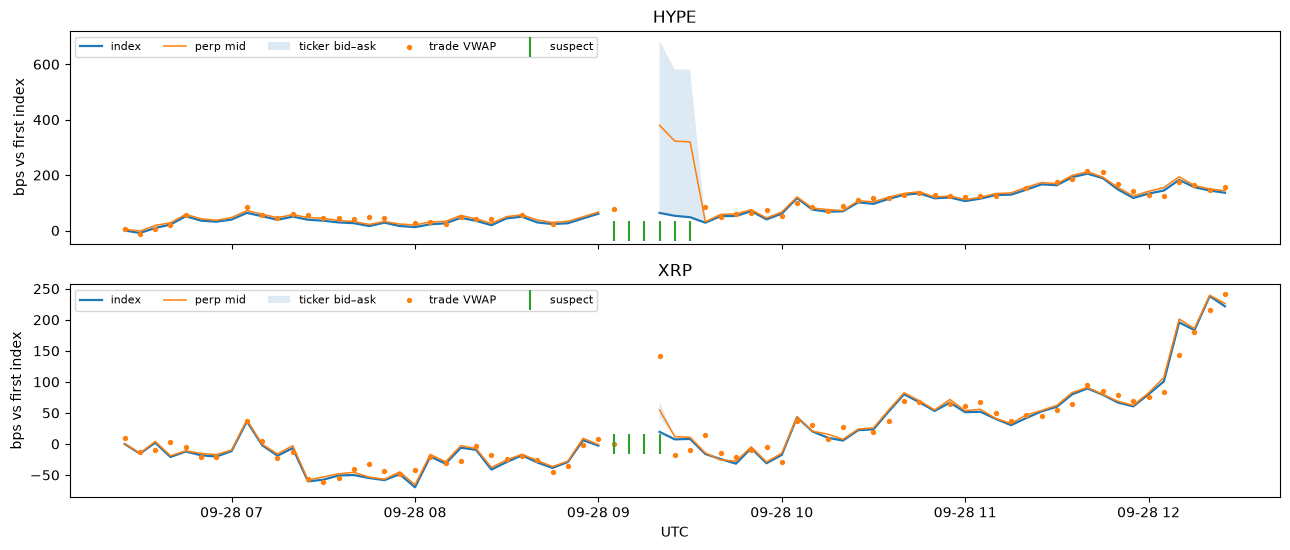


=== Constant spreads and zero returns while trading | 2026-10-01 06:30 – 12:30 UTC ===


,states,suspect,first_suspect,last_suspect,max_spread_bps,trades
underlying,,,,,,
AVAX,73,12,2026-10-01 09:10:00+00:00,2026-10-01 10:15:00+00:00,127.916404,708
HYPE,73,12,2026-10-01 09:05:00+00:00,2026-10-01 10:00:00+00:00,328.927522,987
TRX,73,16,2026-10-01 07:40:00+00:00,2026-10-01 10:00:00+00:00,189.781676,976
XRP,73,12,2026-10-01 09:05:00+00:00,2026-10-01 10:00:00+00:00,487.063411,2516


,bar_end,underlying,tick_spread_bps,l2_spread_bps,mid_vs_index_bps,vwap_vs_index_bps,tick_vs_l2_mid_bps,bbo_run_bars,index_drift_since_bbo_change_bps,last_trade_outside_bbo_bps,trade_count,volume_usd,book_update_count,book_age_ms,ticker_age_ms,mid_return_5m_raw,index_return_5m,stream_complete,suspect_quote,flag_wide_spread,flag_mid_off_index,flag_tick_l2_disagree,flag_stale_vs_index,flag_frozen_with_trades,flag_trade_outside_bbo,flag_no_l2_updates,flag_no_two_sided
2861,2026-10-01 09:10:00+00:00,AVAX,127.916404,NaN,-39.557725,-101.908263,NaN,2,35.054640,NaN,2,2.634839e+03,0.0,417038.0,1033.0,0.000000,0.003505,True,True,False,True,False,False,False,False,True,False
2862,2026-10-01 09:15:00+00:00,AVAX,127.916404,NaN,-22.495173,NaN,NaN,3,17.992088,NaN,0,0.000000e+00,0.0,717038.0,1928.0,0.000000,-0.001706,True,True,False,True,False,False,False,False,False,False
2863,2026-10-01 09:20:00+00:00,AVAX,127.916404,NaN,-8.104093,-70.454632,NaN,4,3.601008,NaN,35,3.366552e+05,0.0,1017038.0,1824.0,0.000000,-0.001439,True,True,False,False,False,False,False,False,True,False
2864,2026-10-01 09:25:00+00:00,AVAX,127.916404,NaN,-2.702094,-65.052633,NaN,5,1.800991,NaN,1,5.516000e+02,0.0,1317038.0,2724.0,0.000000,-0.000540,True,True,False,False,False,False,True,False,True,False
2865,2026-10-01 09:30:00+00:00,AVAX,127.916404,NaN,3.603928,-58.746610,NaN,6,8.107013,NaN,34,3.031723e+04,0.0,1617038.0,1610.0,0.000000,-0.000631,True,True,False,False,False,False,True,False,True,False
2866,2026-10-01 09:35:00+00:00,AVAX,127.916404,NaN,9.012257,-53.338281,NaN,7,13.515342,NaN,12,3.832448e+04,0.0,1917038.0,1506.0,0.000000,-0.000541,True,True,False,False,False,False,True,False,True,False
2867,2026-10-01 09:40:00+00:00,AVAX,127.916404,NaN,34.289873,-28.060666,NaN,8,38.792958,NaN,21,2.369847e+05,0.0,2217038.0,4409.0,0.000000,-0.002528,True,True,False,True,False,False,True,False,True,False
2868,2026-10-01 09:45:00+00:00,AVAX,127.916404,NaN,45.142727,-17.207811,NaN,9,49.645812,NaN,15,1.151160e+05,0.0,2517038.0,22432.0,0.000000,-0.001085,True,True,False,True,False,False,True,False,True,False
2869,2026-10-01 09:50:00+00:00,AVAX,127.916404,NaN,65.977012,NaN,NaN,10,70.480097,NaN,0,0.000000e+00,0.0,2817038.0,6185.0,0.000000,-0.002083,True,True,False,True,False,True,True,False,False,False
2870,2026-10-01 09:55:00+00:00,AVAX,127.916404,NaN,70.511954,8.161415,NaN,11,75.015038,NaN,1,2.220653e+03,0.0,3117038.0,1036.0,0.000000,-0.000453,True,True,False,True,False,True,True,False,True,False


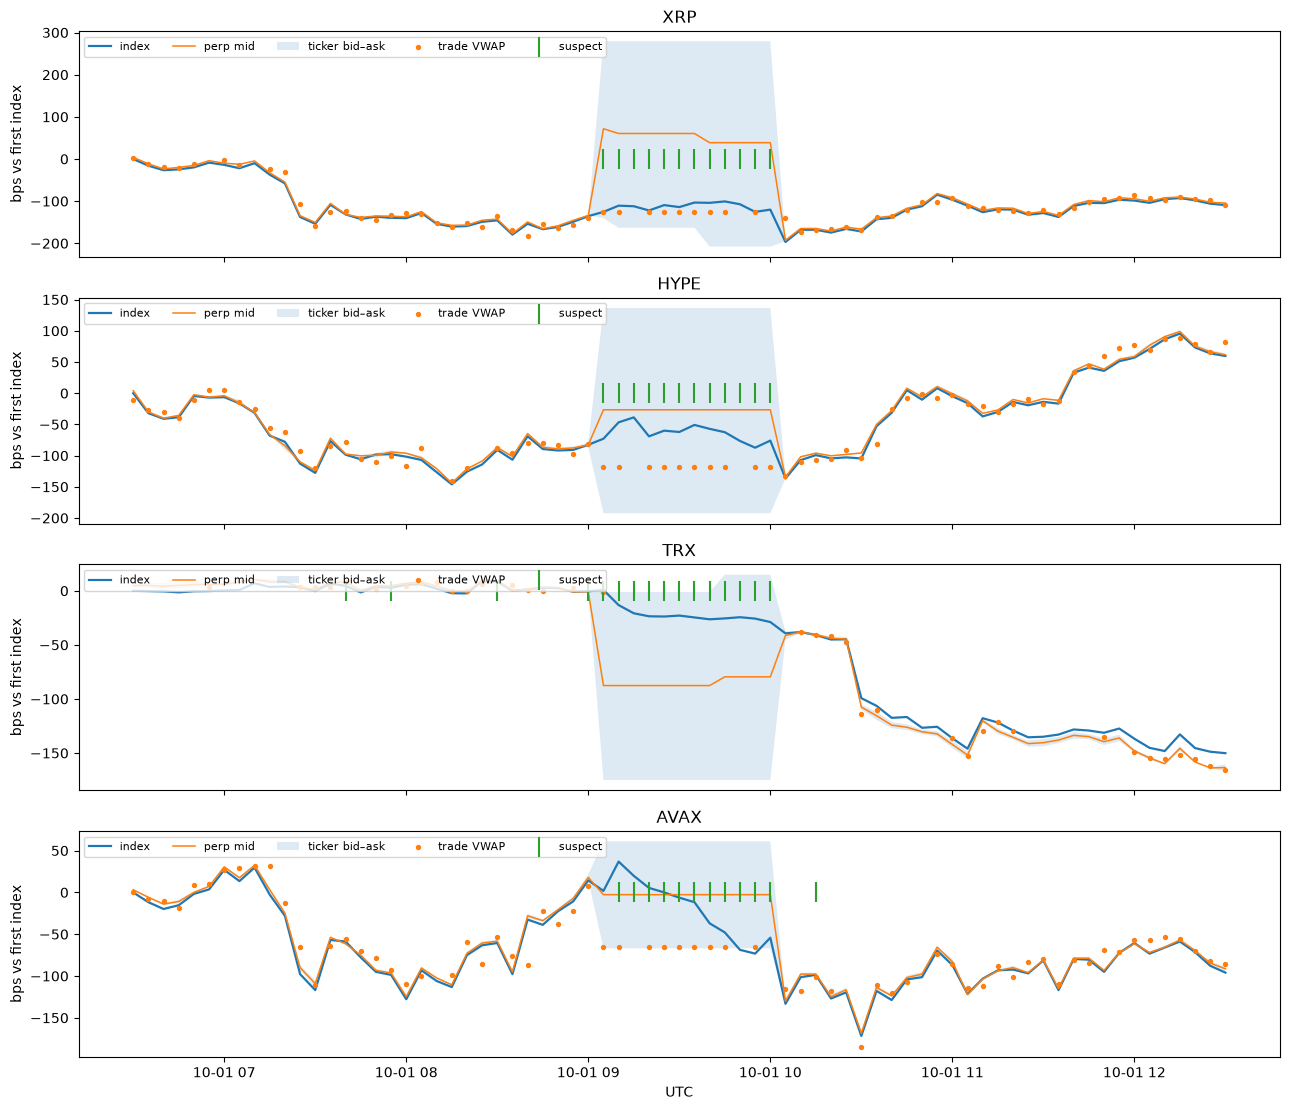

In [30]:
KNOWN_WINDOWS = [
    ("TRX ±9.6% round trip on zero volume", "2026-09-21 17:10", ["TRX", "AVAX", "XRP"]),
    ("HYPE / XRP wide book spreads, no trades", "2026-09-28 09:25", ["HYPE", "XRP"]),
    ("Constant spreads and zero returns while trading", "2026-10-01 09:30", ["XRP", "HYPE", "TRX", "AVAX"]),
]
WINDOW_HALF_WIDTH = pd.Timedelta(hours=3)

window_cols = [
    "bar_end", "underlying", "tick_spread_bps", "l2_spread_bps", "mid_vs_index_bps",
    "vwap_vs_index_bps", "tick_vs_l2_mid_bps", "bbo_run_bars", "index_drift_since_bbo_change_bps",
    "last_trade_outside_bbo_bps", "trade_count", "volume_usd", "book_update_count",
    "book_age_ms", "ticker_age_ms", "mid_return_5m_raw", "index_return_5m",
    "stream_complete", "suspect_quote",
] + FLAG_COLS
window_cols = [c for c in window_cols if c in integrity.columns]

for title, centre, assets in KNOWN_WINDOWS:
    centre = pd.Timestamp(centre, tz="UTC")
    lo, hi = centre - WINDOW_HALF_WIDTH, centre + WINDOW_HALF_WIDTH
    w = integrity[(integrity["bar_end"].between(lo, hi)) & (integrity["underlying"].isin(assets))]

    print(f"\n=== {title} | {lo:%Y-%m-%d %H:%M} – {hi:%H:%M} UTC ===")
    if w.empty:
        print("No raw rows in this window.")
        continue

    display(
        w.groupby("underlying").agg(
            states=("bar_end", "size"),
            suspect=("suspect_quote", "sum"),
            first_suspect=("bar_end", lambda s: s[w.loc[s.index, "suspect_quote"]].min()),
            last_suspect=("bar_end", lambda s: s[w.loc[s.index, "suspect_quote"]].max()),
            max_spread_bps=("tick_spread_bps", "max"),
            trades=("trade_count", "sum"),
        )
    )
    display(w.loc[w["suspect_quote"], window_cols].head(40))

    fig, axes = plt.subplots(len(assets), 1, figsize=(13, 2.8 * len(assets)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, asset in zip(axes, assets):
        a = w[w["underlying"] == asset].sort_values("bar_end")
        if a.empty:
            ax.set_title(f"{asset}: no rows")
            continue
        ref = pd.to_numeric(a["index_price"], errors="coerce")
        base = ref.dropna().iloc[0] if ref.notna().any() else np.nan
        to_bps = lambda s: 1e4 * np.log(pd.to_numeric(s, errors="coerce") / base)
        ax.plot(a["bar_end"], to_bps(a["index_price"]), label="index", linewidth=1.6)
        ax.plot(a["bar_end"], to_bps(a["tick_mid"]), label="perp mid", linewidth=1.1)
        ax.fill_between(
            a["bar_end"], to_bps(a["best_bid_price"]), to_bps(a["best_ask_price"]),
            alpha=0.15, label="ticker bid–ask",
        )
        ax.scatter(a["bar_end"], to_bps(a["vwap"]), s=8, label="trade VWAP", zorder=3)
        sus = a[a["suspect_quote"]]
        ax.scatter(sus["bar_end"], np.zeros(len(sus)), marker="|", s=200, label="suspect", zorder=4)
        ax.set_title(asset)
        ax.set_ylabel("bps vs first index")
        ax.legend(loc="upper left", fontsize=8, ncol=5)
    axes[-1].set_xlabel("UTC")
    plt.tight_layout()
    plt.show()

## 30. Impact on returns and realized volatility

Three return series are compared on the same grid:

1. `return_5m` from `time_series_feature_state` (perpetual mid, current pipeline);
2. the same mid return with any return whose **start or end state** is suspect set to missing;
3. the Deribit **index** return $r^{I}_t = \ln(I_t / I_{t-5m})$.

The recomputed mid return is first checked against the pipeline value, so that the comparison is between data sources and not between two implementations.

If the index return keeps the genuine tails (it moves with the market) but loses the isolated spikes, that is evidence for audit A1: structural returns should come from the index, and the perpetual should be kept for flow, basis and L2 features. The index is also the settlement reference of the options.

Pairs compared:              23,317
Max |pipeline − recomputed|: 0.000e+00
Pipeline returns with no recomputed value: 0
Return distribution by source:


n                                    zero_share_pct                                    std_bps                                    excess_kurtosis                                     \
series     index mid (pipeline) mid, suspect masked          index mid (pipeline) mid, suspect masked   index mid (pipeline) mid, suspect masked           index mid (pipeline) mid, suspect masked   
underlying                                                                                                                                                                                            
AVAX        3416           3331                3297          1.786          1.111               0.607  31.698         32.469              31.355           5.065          8.579               5.258   
BTC         3416           3331                2959          0.000          0.390               0.000  11.331         11.384              10.147           7.891          8.478               4.184   
ETH         3416           3331                3011          0.146          0.510               0.000  13.981         14.017              12.757           8.101          8.091               8.730   
HYPE        3416           3331                3312          0.146          0.360               0.030  21.343         22.238              21.308           3.612         11.781               3.554   
SOL         3416           3331                1702          0.059          0.480               0.059  19.375         19.491              15.957           9.184          9.047               4.149   
TRX         3416           3331                3210          0.439          4.953               2.866   4.915         24.153               5.025           9.750       1507.891              13.309   
XRP         3416           3331                3272          1.581          1.261               0.397  24.104         25.583              24.135           6.413         14.904               6.154   

           max_abs_bps                                     
series           index mid (pipeline) mid, suspect masked  
underlying                                                 
AVAX           230.293        295.783             241.222  
BTC            112.049        116.794              69.609  
ETH            136.669        140.169             140.169  
HYPE           148.433        288.146             146.899  
SOL            213.748        211.248             128.156  
TRX             54.502        962.766              62.890  
XRP            188.785        276.821             189.722

Mid vs index agreement and 30m RV (annualized):


,underlying,corr_mid_index,corr_mid_masked_index,max_rv30_pipeline,max_rv30_mid_masked,max_rv30_index,median_rv30_pipeline,median_rv30_index
0,AVAX,0.9723,0.9970,5.3042,3.5418,3.5219,0.7905,0.7989
1,BTC,0.9939,0.9949,1.6264,1.3034,1.5539,0.2545,0.2568
2,ETH,0.9950,0.9964,1.9812,1.9812,1.9389,0.3254,0.3262
3,HYPE,0.9582,0.9949,3.8667,2.6927,2.7565,0.5491,0.5544
4,SOL,0.9960,0.9975,3.0651,1.2290,3.1132,0.4646,0.4674
5,TRX,0.2061,0.9571,17.9984,0.8487,0.7540,0.1167,0.1194
6,XRP,0.9593,0.9970,4.8973,3.5024,3.4934,0.5622,0.5577


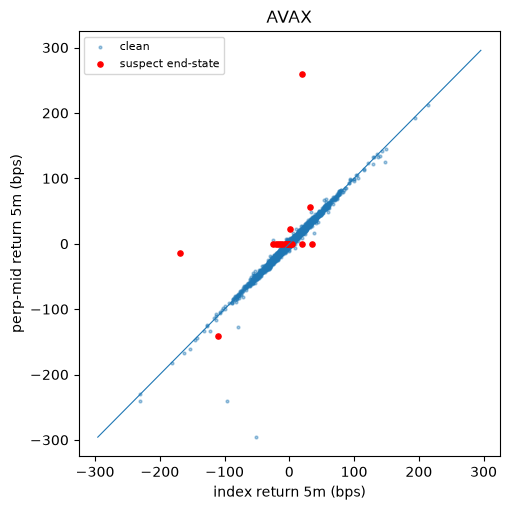

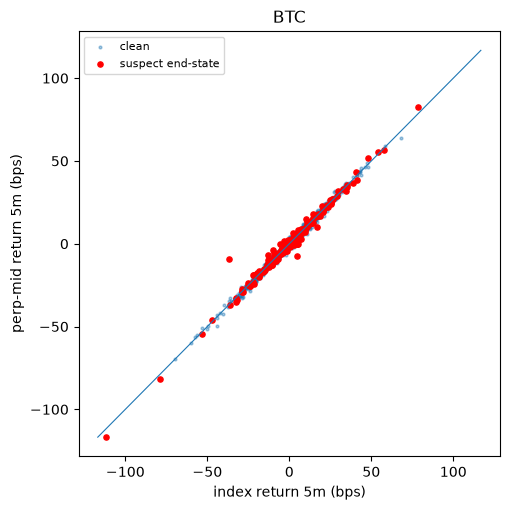

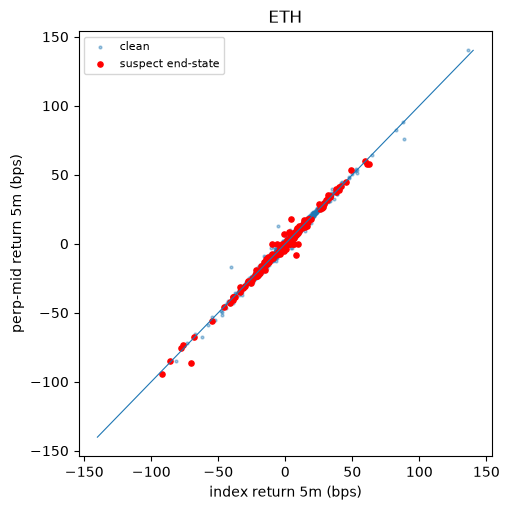

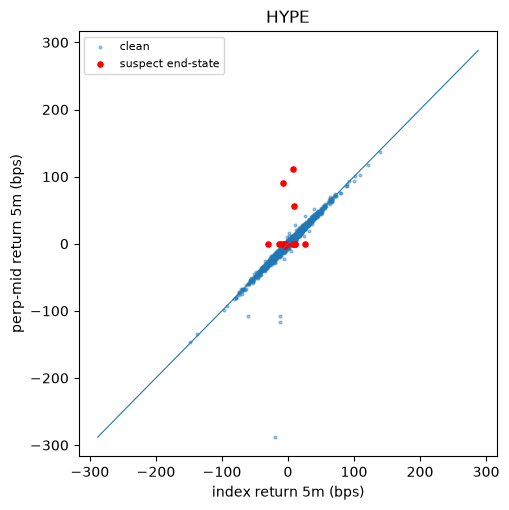

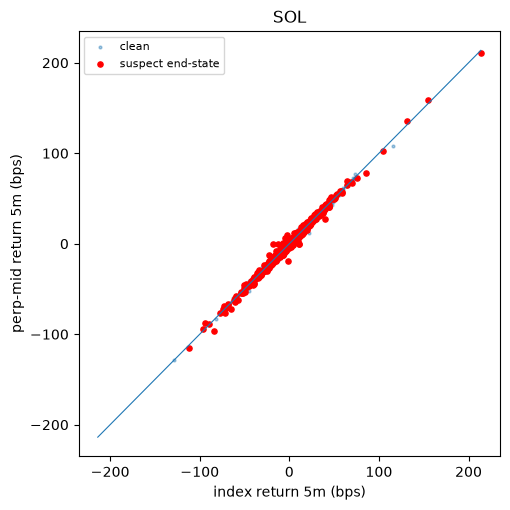

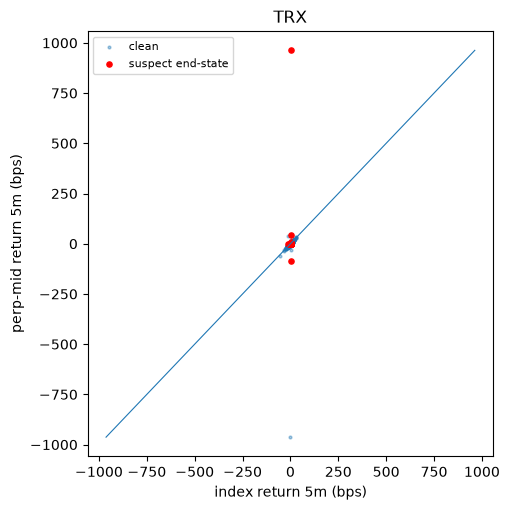

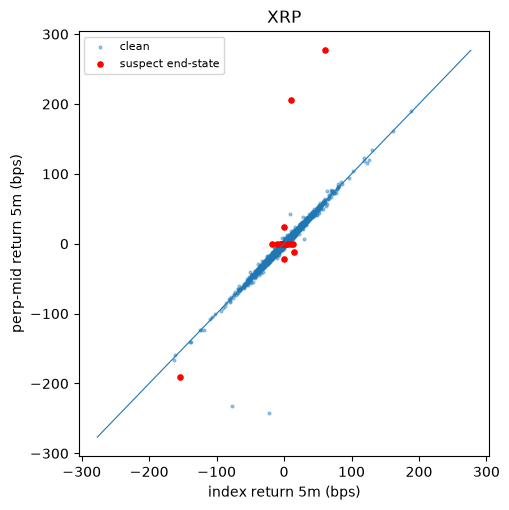

In [31]:
impact = integrity.merge(
    features[["underlying", "state_time", "return_5m", "realized_vol_30m_annualized"]]
    .assign(state_time=lambda d: pd.to_datetime(d["state_time"], utc=True)),
    left_on=["underlying", "bar_end"],
    right_on=["underlying", "state_time"],
    how="inner",
).sort_values(["underlying", "bar_end"])

# 1) Implementation check against the pipeline.
both = impact[["return_5m", "mid_return_5m_raw"]].dropna()
print(f"Pairs compared:              {len(both):,}")
print(f"Max |pipeline − recomputed|: {(both['return_5m'] - both['mid_return_5m_raw']).abs().max():.3e}")
print(f"Pipeline returns with no recomputed value: {int(impact['return_5m'].notna().sum() - len(both)):,}")

# 2) Mask returns touching a suspect endpoint.
impact = per_asset(impact, lambda g: g.assign(_prev_suspect=lag_on_grid(g, "suspect_quote")))
prev_suspect = impact["_prev_suspect"].fillna(False).astype(bool)
impact["mid_return_5m_clean"] = impact["return_5m"].where(~(impact["suspect_quote"] | prev_suspect))

PERIODS_PER_YEAR = 365.0 * 24.0 * 12.0

def rv_annualized(r, window=6):
    """Complete-window RV, same definition as the pipeline (requires `window` returns)."""
    sq = r.pow(2)
    s = sq.rolling(window, min_periods=window).sum()
    return np.sqrt(s / window * PERIODS_PER_YEAR)

impact["rv30_index"] = impact.groupby("underlying", group_keys=False)["index_return_5m"].apply(rv_annualized)
impact["rv30_mid_clean"] = impact.groupby("underlying", group_keys=False)["mid_return_5m_clean"].apply(rv_annualized)

rows, pair_rows = [], []
for asset, g in impact.groupby("underlying"):
    for label, col in [
        ("mid (pipeline)", "return_5m"),
        ("mid, suspect masked", "mid_return_5m_clean"),
        ("index", "index_return_5m"),
    ]:
        s = g[col].dropna()
        rows.append({
            "underlying": asset,
            "series": label,
            "n": len(s),
            "zero_share_pct": 100 * (s == 0).mean() if len(s) else np.nan,
            "std_bps": 1e4 * s.std(),
            "excess_kurtosis": s.kurt(),
            "max_abs_bps": 1e4 * s.abs().max() if len(s) else np.nan,
        })

    pair = g[["return_5m", "index_return_5m"]].dropna()
    pair_clean = g[["mid_return_5m_clean", "index_return_5m"]].dropna()
    pair_rows.append({
        "underlying": asset,
        "corr_mid_index": pair.corr().iloc[0, 1] if len(pair) > 20 else np.nan,
        "corr_mid_masked_index": pair_clean.corr().iloc[0, 1] if len(pair_clean) > 20 else np.nan,
        "max_rv30_pipeline": g["realized_vol_30m_annualized"].max(),
        "max_rv30_mid_masked": g["rv30_mid_clean"].max(),
        "max_rv30_index": g["rv30_index"].max(),
        "median_rv30_pipeline": g["realized_vol_30m_annualized"].median(),
        "median_rv30_index": g["rv30_index"].median(),
    })

return_source_impact = pd.DataFrame(rows)
return_source_pairs = pd.DataFrame(pair_rows)
print("Return distribution by source:")
display(return_source_impact.pivot(index="underlying", columns="series").round(3))
print("Mid vs index agreement and 30m RV (annualized):")
display(return_source_pairs.round(4))

for asset, g in impact.groupby("underlying"):
    pair = g[["return_5m", "index_return_5m", "suspect_quote"]].dropna(subset=["return_5m", "index_return_5m"])
    if pair.empty:
        continue
    fig, ax = plt.subplots(figsize=(5.2, 5.2))
    ax.scatter(1e4 * pair["index_return_5m"], 1e4 * pair["return_5m"], s=4, alpha=0.4, label="clean")
    s = pair[pair["suspect_quote"]]
    ax.scatter(1e4 * s["index_return_5m"], 1e4 * s["return_5m"], s=14, color="red", label="suspect end-state")
    lim = np.nanmax(np.abs(1e4 * pair[["return_5m", "index_return_5m"]].to_numpy()))
    ax.plot([-lim, lim], [-lim, lim], linewidth=0.8)
    ax.set_xlabel("index return 5m (bps)")
    ax.set_ylabel("perp-mid return 5m (bps)")
    ax.set_title(asset)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 31. Open-interest jumps

Part D showed 5-minute OI returns of +94% (BTC), +76% (HYPE) and +53% (ETH), and a BTC OI distribution with median ≈ 466 but 95th percentile ≈ 1,480. The pooled median OI return is also negative, which together with rare large positive jumps suggests a **sawtooth**: slow decay punctuated by step increases.

Candidate explanations, each with a test in the next cell:

| Hypothesis | Observable signature |
|---|---|
| Instrument switch / units change | `instrument_name` changes at the jump; OI level shifts by a constant factor |
| Collector artifact | jump coincides with a restart, `stream_complete = False`, or a stale ticker |
| Exchange mechanic at a fixed time | jumps cluster at one UTC time of day across assets |
| Genuine positioning | no time pattern, no feed anomaly; the new level persists |

Until one of these is confirmed, OI features stay out of the feature contract.

,n,negative_share,zero_share,median,jumps_up,jumps_down
underlying,,,,,,
AVAX,4068,0.462840,0.192053,0.000000e+00,0,0
BTC,4068,0.460142,0.001717,6.031241e-05,2,0
ETH,4068,0.515575,0.002698,-6.007205e-07,2,0
HYPE,4068,0.384597,0.306598,0.000000e+00,3,2
SOL,4068,0.552367,0.001717,-1.060667e-06,2,1
TRX,4068,0.090017,0.813834,0.000000e+00,1,0
XRP,4068,0.465048,0.120922,0.000000e+00,2,1


OI jumps with |return| > 10%: 16


,underlying,bar_end,utc_hhmm,instrument_name,instrument_changed,_prev_oi,open_interest,oi_return_5m,_next_oi_return,stream_complete,stream_incomplete_reason,connection_count,ticker_age_ms,trade_count,volume_usd
24639,XRP,2026-09-22 01:20:00+00:00,01:20,XRP_USDC-PERPETUAL,False,5.968970e+06,5.028244e+06,-0.157603,0.004150,True,NaN,NaN,427.0,264,2.880622e+05
17422,SOL,2026-09-25 07:35:00+00:00,07:35,SOL_USDC-PERPETUAL,False,2.225827e+05,2.468075e+05,0.108835,-0.115827,True,NaN,NaN,1003.0,1246,7.224647e+06
17423,SOL,2026-09-25 07:40:00+00:00,07:40,SOL_USDC-PERPETUAL,False,2.468075e+05,2.182206e+05,-0.115827,-0.058942,True,NaN,NaN,291.0,900,3.527901e+06
14571,HYPE,2026-09-29 13:45:00+00:00,13:45,HYPE_USDC-PERPETUAL,False,8.410789e+04,1.477198e+05,0.756314,-0.220090,True,NaN,NaN,676.0,339,5.898774e+06
14572,HYPE,2026-09-29 13:50:00+00:00,13:50,HYPE_USDC-PERPETUAL,False,1.477198e+05,1.152082e+05,-0.220090,-0.000693,True,NaN,NaN,405.0,333,3.509976e+06
14622,HYPE,2026-09-29 18:00:00+00:00,18:00,HYPE_USDC-PERPETUAL,False,1.122294e+05,9.966280e+04,-0.111973,-0.061969,True,NaN,NaN,197.0,624,1.471119e+06
22875,TRX,2026-09-30 02:15:00+00:00,02:15,TRX_USDC-PERPETUAL,False,2.339483e+06,2.647633e+06,0.131717,0.000000,True,NaN,NaN,1359.0,200,1.182601e+05
6937,BTC,2026-10-01 09:05:00+00:00,09:05,BTC_USDC-PERPETUAL,False,4.837977e+02,7.572641e+02,0.565249,0.010169,True,NaN,NaN,1412.0,440,3.984608e+07
11014,ETH,2026-10-01 09:05:00+00:00,09:05,ETH_USDC-PERPETUAL,False,9.657246e+03,1.476920e+04,0.529338,0.012994,True,NaN,NaN,3383.0,199,2.065622e+07
15091,HYPE,2026-10-01 09:05:00+00:00,09:05,HYPE_USDC-PERPETUAL,False,9.164518e+04,1.048659e+05,0.144260,0.000000,True,NaN,NaN,636.0,4,1.172419e+06


Jump times of day (UTC), all assets:


,jumps
utc_hhmm,
09:20,5
09:05,4
13:45,1
13:50,1
18:00,1
07:35,1
07:40,1
02:15,1
01:20,1


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
utc_hour,,,,,,,
0,-0.021,0.025,-0.011,0.016,0.001,0.010,0.019
1,-0.028,0.018,0.020,0.019,0.011,-0.028,-0.105
2,0.015,0.015,0.019,-0.048,0.021,0.085,0.016
3,-0.004,0.009,0.007,0.002,-0.012,-0.031,0.053
4,-0.010,0.013,0.003,-0.034,-0.023,0.013,0.033
5,-0.017,-0.009,0.013,0.006,0.005,0.025,0.010
6,-0.028,0.040,0.002,-0.001,-0.005,0.016,0.019
7,-0.065,-0.004,0.037,-0.056,-0.050,-0.136,-0.045
8,-0.012,0.020,-0.012,0.038,-0.010,-0.018,-0.037


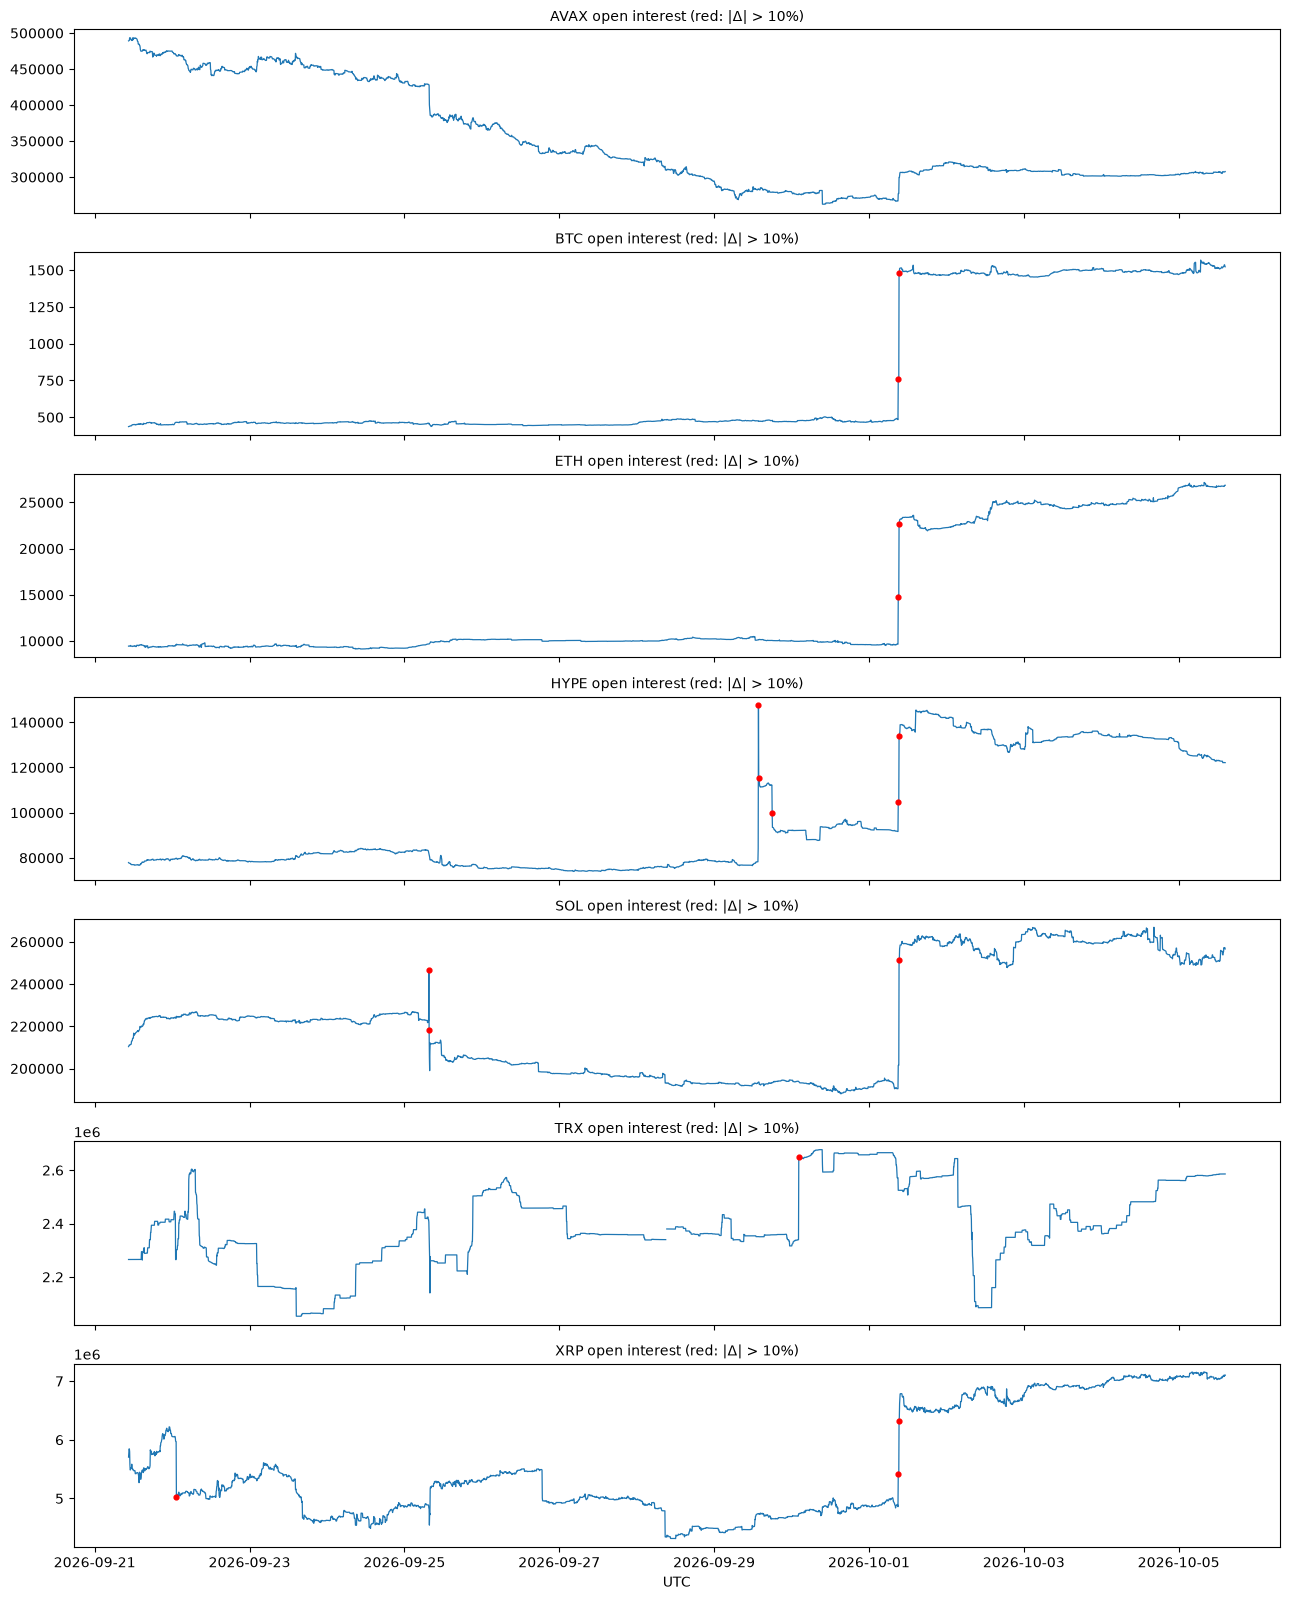

In [32]:
OI_JUMP_THRESHOLD = 0.10

oi = raw_futures_all.sort_values(["underlying", "bar_end"]).copy()
oi["open_interest"] = pd.to_numeric(oi["open_interest"], errors="coerce")
oi["_prev_instrument"] = oi.groupby("underlying")["instrument_name"].shift(1)
oi = per_asset(oi, lambda g: g.assign(_prev_oi=lag_on_grid(g, "open_interest")))
oi["oi_return_5m"] = (oi["open_interest"] / oi["_prev_oi"] - 1).where(oi["_prev_oi"] > 0)
oi["_next_oi_return"] = oi.groupby("underlying")["oi_return_5m"].shift(-1)
oi["instrument_changed"] = oi["instrument_name"] != oi["_prev_instrument"]
oi["utc_hhmm"] = oi["bar_end"].dt.strftime("%H:%M")

# Sawtooth check.
display(
    oi.groupby("underlying")["oi_return_5m"].agg(
        n="count",
        negative_share=lambda s: (s < 0).mean(),
        zero_share=lambda s: (s == 0).mean(),
        median="median",
        jumps_up=lambda s: int((s > OI_JUMP_THRESHOLD).sum()),
        jumps_down=lambda s: int((s < -OI_JUMP_THRESHOLD).sum()),
    )
)

jump_cols = [
    "underlying", "bar_end", "utc_hhmm", "instrument_name", "instrument_changed",
    "_prev_oi", "open_interest", "oi_return_5m", "_next_oi_return",
    "stream_complete", "stream_incomplete_reason", "connection_count", "ticker_age_ms",
    "trade_count", "volume_usd",
]
oi_jumps = oi.loc[oi["oi_return_5m"].abs() > OI_JUMP_THRESHOLD, [c for c in jump_cols if c in oi.columns]]
print(f"OI jumps with |return| > {OI_JUMP_THRESHOLD:.0%}: {len(oi_jumps):,}")
display(oi_jumps.sort_values("bar_end").head(60))

if not oi_jumps.empty:
    print("Jump times of day (UTC), all assets:")
    display(oi_jumps["utc_hhmm"].value_counts().head(15).to_frame("jumps"))

# Mean OI return by UTC hour: a fixed-time mechanic shows as one dominant hour.
hourly = (
    oi.assign(utc_hour=oi["bar_end"].dt.hour)
    .pivot_table(index="utc_hour", columns="underlying", values="oi_return_5m", aggfunc="mean")
)
display((100 * hourly).round(3))

assets = sorted(oi["underlying"].dropna().unique())
fig, axes = plt.subplots(len(assets), 1, figsize=(13, 2.3 * len(assets)), sharex=True)
for ax, asset in zip(np.atleast_1d(axes), assets):
    a = oi[oi["underlying"] == asset]
    ax.plot(a["bar_end"], a["open_interest"], linewidth=0.9)
    j = a[a["oi_return_5m"].abs() > OI_JUMP_THRESHOLD]
    ax.scatter(j["bar_end"], j["open_interest"], color="red", s=12, zorder=3)
    ax.set_title(f"{asset} open interest (red: |Δ| > {OI_JUMP_THRESHOLD:.0%})", fontsize=10)
np.atleast_1d(axes)[-1].set_xlabel("UTC")
plt.tight_layout()
plt.show()

## 32. Integrity findings to carry forward

`futures_integrity_diagnostics` (in memory, keyed by `underlying × state_time`) holds every metric and flag from this part. It is **not** written to the database; the production gate belongs in `quality_contract.py`.

Record here, after running:

1. Which flags fire in the three known windows, and which never fire anywhere (candidates to drop from the gate).
2. Whether suspect states are mostly long episodes (feed failure) or isolated states (illiquidity, threshold).
3. Whether suspect episodes overlap across assets (collector/exchange) or not (market/liquidity).
4. How much of each asset's return kurtosis and maximum RV disappears when suspect returns are masked, and how the index return compares.
5. Which OI hypothesis the evidence supports.
6. Whether the flag counts are stable between $z = 6$ and $z = 10$.

Post-v0.3 rows carry direct signals (`bbo_last_change`, `trades_outside_book_bbo`, REST stale confirmation). Once a few weeks exist, compare them with the pre-v0.3 proxies above on the overlapping period to validate the proxies used for history.

In [33]:
futures_integrity_diagnostics = integrity.rename(columns={"bar_end": "state_time"})[
    ["underlying", "state_time", "suspect_quote"]
    + FLAG_COLS
    + [c for c in metric_cols if c in integrity.columns]
    + ["index_return_5m", "mid_return_5m_raw"]
]

print(f"Rows:          {len(futures_integrity_diagnostics):,}")
print(f"Suspect rows:  {int(futures_integrity_diagnostics['suspect_quote'].sum()):,}")
print(f"Episodes:      {len(episodes):,}")
print(f"OI jumps:      {len(oi_jumps):,}")

Rows:          28,539
Suspect rows:  1,736
Episodes:      1,088
OI jumps:      16


# Part J — Research Handoff

## 33. Notebook 02 interpretation checklist

Before moving to `03_surface_distributions.ipynb`, record the answers to these questions:

1. Which market features show materially different scale across underlyings?
2. Which features have genuine structural boundary masses rather than smooth distributions?
3. Which tails are driven by isolated observations versus repeated episodes?
4. Are extreme spreads/basis observations concentrated in particular assets or market conditions?
5. Which variables show enough persistence to be plausible structural-state descriptors?
6. Which variables change too rapidly and may be better suited to the future noise/transition blocks?
7. Does `log1p_volume_usd` materially improve the activity representation relative to raw volume?
8. Which positive scale variables are plausible `log1p` candidates?
9. Which signed scale variables are plausible signed-log candidates?
10. Which bounded variables should remain in native support?
11. Is session-to-session distribution drift large enough to affect later chronological validation design?
12. Are any findings based on too little history to support a production decision?
13. Which tails in Parts A–E survive once suspect quote states are masked (Section 30)?
14. Should structural returns move from the perpetual mid to the index (audit A1), given Section 30?
15. Which integrity flags belong in the production gate, and which never fire (Section 32)?
16. What explains the open-interest jumps, and can OI features enter the contract (Section 31)?

**Do not freeze the model feature contract here.**  
Notebook 02 creates evidence for the later feature-contract decision; it does not make the final decision.

In [34]:
market_distribution_report = {
    "overall_availability": overall_availability,
    "availability_by_asset": availability_by_asset,
    "return_pooled": return_pooled if "return_pooled" in globals() else pd.DataFrame(),
    "return_by_asset": return_by_asset if "return_by_asset" in globals() else pd.DataFrame(),
    "rv_summary": rv_summary if "rv_summary" in globals() else pd.DataFrame(),
    "rv_by_asset": rv_by_asset if "rv_by_asset" in globals() else pd.DataFrame(),
    "boundary_mass": boundary_mass if "boundary_mass" in globals() else pd.DataFrame(),
    "cross_asset_scale": cross_asset_scale if "cross_asset_scale" in globals() else pd.DataFrame(),
    "session_distribution": session_distribution if "session_distribution" in globals() else pd.DataFrame(),
    "transform_assessment": transform_assessment if "transform_assessment" in globals() else pd.DataFrame(),
    "integrity_flag_counts": flag_counts.reset_index() if "flag_counts" in globals() else pd.DataFrame(),
    "integrity_flag_sensitivity": flag_sensitivity if "flag_sensitivity" in globals() else pd.DataFrame(),
    "integrity_episodes": episodes if "episodes" in globals() else pd.DataFrame(),
    "return_source_impact": return_source_impact if "return_source_impact" in globals() else pd.DataFrame(),
    "return_source_pairs": return_source_pairs if "return_source_pairs" in globals() else pd.DataFrame(),
    "oi_jumps": oi_jumps if "oi_jumps" in globals() else pd.DataFrame(),
    "futures_integrity_diagnostics": futures_integrity_diagnostics if "futures_integrity_diagnostics" in globals() else pd.DataFrame(),
}

print("Market-distribution report sections:")
for name, frame in market_distribution_report.items():
    print(f"  {name:<28} {len(frame):>7,} rows")

Market-distribution report sections:
  overall_availability              36 rows
  availability_by_asset              7 rows
  return_pooled                      4 rows
  return_by_asset                   28 rows
  rv_summary                         6 rows
  rv_by_asset                       42 rows
  boundary_mass                      7 rows
  cross_asset_scale                 70 rows
  session_distribution             413 rows
  transform_assessment              14 rows
  integrity_flag_counts              7 rows
  integrity_flag_sensitivity        35 rows
  integrity_episodes             1,088 rows
  return_source_impact              21 rows
  return_source_pairs                7 rows
  oi_jumps                          16 rows
  futures_integrity_diagnostics  28,539 rows


## 34. Close the read-only connection

In [35]:
con.close()
print("DuckDB connection closed.")

DuckDB connection closed.
